# 01 · Vue d'ensemble et qualité des données

**Projet 2 · Marketing Econometrics (TSE M2)** : *prédire qui va racheter le mois prochain.*

Ce notebook couvre les deux premières étapes du cadre demandé : **1. Contexte et objectifs** et **2. Vue d'ensemble des données**, avec un accent volontaire sur la **préparation des données** (premier critère de la grille de notation) : valeurs manquantes, valeurs extrêmes, qualité, suppression de variables, traitements statistiques.

Fil rouge : pour chaque anomalie, on **la chiffre**, on **décide** (garder, corriger, regrouper, supprimer, plafonner) et on **justifie**. Toutes les décisions sont rassemblées dans un tableau final (`results/01_cleaning_decisions.csv`) ; les règles déjà appliquées sont celles de `common._clean`, dont on vérifie ici (assertions) qu'elles font ce qu'on dit. Ce que le notebook ne fait pas (plafonnement, regroupements, imputations) est confié au notebook 02.

| Partie | Contenu |
|---|---|
| 1 | Contexte métier, cible, période d'observation, périmètre |
| 2 | Volumes, dictionnaire des variables, train vs test, cible par pli |
| 3 | **Qualité des données** : chaque anomalie chiffrée, avec traitement et justification |
| 4 | **Valeurs extrêmes** : distributions, détection, plafonnement proposé |
| 5 | Dynamique temporelle (mois, jours, heures, confinement, août) |
| 6 | Taux de rachat selon les variables brutes (classes + effectifs) |
| 7 | Tableau des décisions de préparation et passage de relais au notebook 02 |
| 8 | Limites et pistes d'amélioration |

In [1]:
import sys
sys.path.insert(0, '.')
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown
from scipy import stats
from sklearn.metrics import roc_auc_score
import common as c

c.set_style()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

KEY = {}    # chiffres clés, réutilisés dans results/01_summary.md
DEC = []    # décisions de préparation (tableau de la partie 7)
FIGS = {}   # figures : nom -> message (une phrase)


def fr(x, d=0):
    """Nombre à la française : espace fine insécable pour les milliers, virgule décimale."""
    return f'{x:,.{d}f}'.replace(',', ' ').replace('.', ',')


def pc(x, d=1):
    """Proportion -> pourcentage à la française."""
    return fr(100 * x, d) + ' %'


def md(s):
    display(Markdown(s))


def dec(theme, variable, anomalie, decision, justification, impact, applique):
    DEC.append(dict(theme=theme, variable=variable, anomalie=anomalie, decision=decision,
                    justification=justification, impact_chiffre=impact, applique_dans=applique))


def savefig(fig, name, message):
    FIGS['01_' + name] = message
    c.save_fig(fig, '01_' + name)
    plt.show()
    plt.close(fig)


def fmtnum(v, d=2):
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        if pd.isna(v):
            return ''
        return fr(v, 0) if (float(v).is_integer() or abs(v) >= 1000) else fr(v, d)
    return v


def nice(df, d=2):
    """Tableau avec séparateurs de milliers et virgule décimale."""
    return df.style.format(lambda v: fmtnum(v, d))


def wilson(k, n, z=1.96):
    """Intervalle de confiance de Wilson pour une proportion."""
    p = k / n
    den = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return centre - half, centre + half

## 1. Contexte et objectifs

**Pourquoi ce problème compte.** Une enseigne de supermarchés prépare un e-mailing promotionnel et ne peut pas écrire à toute sa base : le marketing veut cibler **au plus 10 % des clients**, ceux qui ont le plus de chances de racheter. Dans le cycle de vie client, on se situe après l'acquisition : tous les clients de la base ont déjà acheté, et la question est « qui va revenir dans le mois ? » (cas d'usage « propension à racheter dans le mois », slide 50 du cours). Un **score de propension** classe les clients du plus au moins susceptible de racheter ; le marketing garde le haut du classement. Le score ne dit pas *quoi* faire de ces clients (relancer ceux qui s'éloignent, ou récompenser ceux qui reviendraient de toute façon ?) : c'est l'objet de la recommandation finale, mais le premier arbitrage se lit déjà dans les données de ce notebook.

**Lien avec le cours** : cadrage d'un scoring (slides 50-51 : cible, périmètre, profondeur d'historique, fenêtre de calcul de la cible, saisonnalité) et phases d'un projet data (slides 82-84).

| Élément de cadrage | Définition retenue |
|---|---|
| **Unité statistique** | un client (`id_client`) |
| **Périmètre** | « client » = au moins un ticket sur les 12 mois observés. Pas de prospect ni de client dormant depuis plus d'un an : le score classe des clients **déjà actifs** |
| **Période d'observation** (profondeur d'historique) | du 01/08/2019 au 31/07/2020, soit 12 mois |
| **Cible** `repurchase` | 1 si le client achète au moins une fois en **août 2020** (fenêtre de calcul : 1 mois, juste après l'observation), 0 sinon |
| **Fuite d'information** | aucune ligne d'août 2020 dans les fichiers : vérifié ci-dessous |
| **Contrainte d'usage** | au plus 10 % de la base ciblée : un score se juge à son classement (AUC, précision dans le top 10 %) plus qu'à ses probabilités |
| **Validation** | 5 plis stratifiés fixés une fois pour toutes (`c.get_folds()`), communs à tous les notebooks |

## 2. Vue d'ensemble des données

### 2.1 Chargement et volumes
`load_raw` lit les CSV sans aucune transformation (une ligne du fichier = une ligne de ticket) ; `load_clean` applique les règles de `common._clean` et renvoie une table de **tickets** et une table de **clients**.

In [2]:
raw_tr, raw_te = c.load_raw('train'), c.load_raw('test')
tk_tr, cl_tr = c.load_clean('train')
tk_te, cl_te = c.load_clean('test')
y = c.load_target()
folds = c.get_folds()
sample = pd.read_csv(c.DATA / 'sampling_sample.csv')

# pas de fuite : rien à partir du 01/08/2020, rien avant le 01/08/2019 (heures UTC, comme les données)
for nm, t in [('train', tk_tr), ('test', tk_te)]:
    assert t.ts.min() >= c.START_DATE and t.ts.max() < c.REF_DATE, nm


def volumes(raw, tk, cl):
    pt = tk[~tk.is_return]
    return pd.Series({
        'Lignes brutes du CSV': len(raw), 'Tickets (après agrégation)': len(tk), 'Clients': len(cl),
        'Premier ticket': tk.ts.min().strftime('%d/%m/%Y %H:%M'), 'Dernier ticket': tk.ts.max().strftime('%d/%m/%Y %H:%M'),
        'Jours calendaires avec au moins un ticket': tk.ts.dt.normalize().nunique(),
        'Chiffre d\'affaires des tickets d\'achat (M€)': pt.basket_value.sum() / 1e6,
        'Taux de rachat (août 2020)': y.mean() if cl is cl_tr else np.nan})


vol = pd.concat({'Train': volumes(raw_tr, tk_tr, cl_tr), 'Test': volumes(raw_te, tk_te, cl_te)}, axis=1)
vol = vol.astype(object)
vol.loc['Chiffre d\'affaires des tickets d\'achat (M€)'] = [fr(v, 1) for v in vol.loc['Chiffre d\'affaires des tickets d\'achat (M€)']]
vol.loc['Taux de rachat (août 2020)'] = [pc(y.mean(), 2), '(inconnu)']
for r in ['Lignes brutes du CSV', 'Tickets (après agrégation)', 'Clients', 'Jours calendaires avec au moins un ticket']:
    vol.loc[r] = [fr(v) for v in vol.loc[r]]
display(vol)

KEY.update(n_rows_train=len(raw_tr), n_rows_test=len(raw_te), n_tickets_train=len(tk_tr), n_tickets_test=len(tk_te),
           n_clients_train=len(cl_tr), n_clients_test=len(cl_te), rate=float(y.mean()), n_pos=int(y.sum()))

,Train,Test
Lignes brutes du CSV,3 298 736,824 282
Tickets (après agrégation),3 292 994,822 894
Clients,160 424,40 106
Premier ticket,01/08/2019 00:23,01/08/2019 07:55
Dernier ticket,31/07/2020 23:55,31/07/2020 23:42
Jours calendaires avec au moins un ticket,366,366
Chiffre d'affaires des tickets d'achat (M€),"155,6","38,8"
Taux de rachat (août 2020),"7,72 %",(inconnu)


In [3]:
# IDs : les clients du fichier d'exemple Kaggle sont exactement ceux du test, sans recoupement avec le train
ids_str = pd.read_csv(c.DATA / 'Train_transactions.csv', usecols=['id_client'], dtype=str)['id_client']
assert ids_str.nunique() == raw_tr.id_client.nunique(), 'la conversion en entier fusionne des identifiants'
assert set(sample.ID) == set(cl_te.index) and sample.ID.is_unique
assert len(set(sample.ID) & set(cl_tr.index)) == 0
assert set(y.index) == set(cl_tr.index) and y.index.is_unique and set(folds.index) == set(cl_tr.index)
md(f"""**Contrôles d'identifiants.** Les {fr(len(sample))} ID de `sampling_sample.csv` sont exactement les {fr(len(cl_te))} clients du test (aucun doublon, aucun client commun avec le train).
Dans les CSV, `id_client` est écrit sur {ids_str.str.len().max()} caractères fixes (par exemple `{ids_str.iloc[0]}`), avec des zéros initiaux, alors que le fichier d'exemple les omet : la conversion en entier est sans perte
({fr(ids_str.nunique())} identifiants distincts avant et après) et fait correspondre les deux fichiers. La cible couvre exactement les {fr(len(y))} clients du train.""")

**Contrôles d'identifiants.** Les 40 106 ID de `sampling_sample.csv` sont exactement les 40 106 clients du test (aucun doublon, aucun client commun avec le train).
Dans les CSV, `id_client` est écrit sur 10 caractères fixes (par exemple `0037520523`), avec des zéros initiaux, alors que le fichier d'exemple les omet : la conversion en entier est sans perte
(160 424 identifiants distincts avant et après) et fait correspondre les deux fichiers. La cible couvre exactement les 160 424 clients du train.

### 2.2 Dictionnaire des variables
Pour chaque colonne brute : description, niveau auquel elle est constante, part de manquants au **niveau ligne** (une ligne du CSV) et au **niveau client** (le client a-t-il l'information ?). Les deux chiffres diffèrent parce que les clients très actifs ont beaucoup plus de lignes.

In [4]:
ATTR = ['email_domain', 'civility', 'zip_code', 'card_subscription', 'multicard', 'price_segmentation']
att_first = raw_tr.groupby('id_client')[ATTR].first()
att_nuniq = raw_tr.groupby('id_client')[ATTR].nunique(dropna=True)
# attributs client : au plus une valeur par client (donc "first" ne perd rien) ; manquant = tout ou rien par client
na_share = raw_tr[ATTR].isna().groupby(raw_tr['id_client']).mean()
assert (att_nuniq.max() <= 1).all(), 'un attribut varie à l\'intérieur d\'un client'
assert na_share.isin([0.0, 1.0]).all().all(), 'un attribut est manquant sur certains tickets seulement'

desc = {
    'id_client': ('Identifiant client', 'entier', 'client'),
    'transaction_date': ('Date et heure du ticket (UTC, à la minute)', 'texte ISO', 'ticket'),
    'stores_nb': ('Magasin : 2 premiers chiffres = département, 3 derniers = n° de magasin', 'entier', 'ticket'),
    'item_count': ('Nombre d\'articles', 'entier', 'ligne'),
    'gross_amount': ('Montant brut (€)', 'décimal', 'ligne'),
    'discount_amount': ('Remises (€)', 'décimal', 'ligne'),
    'basket_value': ('Montant payé (€) = brut − remises', 'décimal', 'ligne'),
    'payment_gift': ('Payé (en partie) par cadeau / avoir', '0/1', 'ligne'),
    'payment_cheque': ('Payé (en partie) par chèque', '0/1', 'ligne'),
    'payment_cash': ('Payé (en partie) en espèces', '0/1', 'ligne'),
    'payment_card': ('Payé (en partie) par carte bancaire', '0/1', 'ligne'),
    'email_domain': ('Domaine de l\'e-mail, si renseigné', 'catégorielle', 'client'),
    'civility': ('Civilité : M, MME, NR (non renseigné)', 'catégorielle', 'client'),
    'zip_code': ('Code INSEE / postal du client', 'texte', 'client'),
    'card_subscription': ('Date d\'adhésion à la carte de fidélité (JJ/MM/AAAA)', 'date', 'client'),
    'multicard': ('Inscrit à des programmes de fidélité d\'autres enseignes', '0/1', 'client'),
    'price_segmentation': ('Segment de prix des produits achetés : Access, Mixte, Quali, xx, 8', 'catégorielle', 'client'),
}
dico = pd.DataFrame(desc, index=['description', 'type', 'niveau constant']).T
dico['manquants lignes (%)'] = (raw_tr.isna().mean() * 100).round(1)
dico['manquants clients (%)'] = (att_first.isna().mean() * 100).reindex(dico.index).round(1)
dico['valeurs distinctes'] = [raw_tr[v].nunique() for v in dico.index]
dico['manquants clients (%)'] = dico['manquants clients (%)'].fillna(0.0)
display(dico)
md(f"""**Lecture.** Les six attributs *client* (`email_domain` … `price_segmentation`) sont **constants à l'intérieur de chaque client**, et leur éventuel manquant est « tout ou rien » par client (assertions ci-dessus) : une ligne par client suffit, sans arbitrage entre versions contradictoires.
`price_segmentation`, décrit comme propre à chaque achat, est en réalité un **attribut client** (au plus une modalité par client) : l'idée de « segment de prix dominant » n'a donc pas de sens, c'est la modalité unique du client.
Les variables numériques de transaction (`item_count`, `gross_amount`, `discount_amount`, `basket_value`) et les indicateurs de paiement n'ont aucun manquant.""")

,description,type,niveau constant,manquants lignes (%),manquants clients (%),valeurs distinctes
id_client,Identifiant client,entier,client,0.0,0.0,160424
transaction_date,"Date et heure du ticket (UTC, à la minute)",texte ISO,ticket,0.0,0.0,285764
stores_nb,"Magasin : 2 premiers chiffres = département, 3 derniers = n° de magasin",entier,ticket,0.0,0.0,1453
item_count,Nombre d'articles,entier,ligne,0.0,0.0,433
gross_amount,Montant brut (€),décimal,ligne,0.0,0.0,45175
discount_amount,Remises (€),décimal,ligne,0.0,0.0,13218
basket_value,Montant payé (€) = brut − remises,décimal,ligne,0.0,0.0,43138
payment_gift,Payé (en partie) par cadeau / avoir,0/1,ligne,0.0,0.0,2
payment_cheque,Payé (en partie) par chèque,0/1,ligne,0.0,0.0,2
payment_cash,Payé (en partie) en espèces,0/1,ligne,0.0,0.0,2


**Lecture.** Les six attributs *client* (`email_domain` … `price_segmentation`) sont **constants à l'intérieur de chaque client**, et leur éventuel manquant est « tout ou rien » par client (assertions ci-dessus) : une ligne par client suffit, sans arbitrage entre versions contradictoires.
`price_segmentation`, décrit comme propre à chaque achat, est en réalité un **attribut client** (au plus une modalité par client) : l'idée de « segment de prix dominant » n'a donc pas de sens, c'est la modalité unique du client.
Les variables numériques de transaction (`item_count`, `gross_amount`, `discount_amount`, `basket_value`) et les indicateurs de paiement n'ont aucun manquant.

### 2.3 Train vs test : sont-ils comparables ?
Le test est un tirage aléatoire de 20 % des clients. On compare des profils **calculés de la même manière** sur les deux échantillons (aucune décision n'est prise à partir du test : c'est un simple contrôle d'homogénéité). Pour les variables continues, la statistique de Kolmogorov-Smirnov *D* mesure l'écart maximal entre les deux distributions (D < 0,01 = écart négligeable) ; la *p*-valeur n'est pas à lire seule, car avec 40 000 clients le moindre écart devient « significatif ».

In [5]:
def client_agg(tk, cl):
    """Agrégats client simples (une ligne par client) à partir des tickets nettoyés, pour la description."""
    buy = tk[~tk.is_return]
    gb = buy.groupby('id_client')
    a = pd.DataFrame({
        'n_tickets': tk.groupby('id_client').size(),
        'n_buy': gb.size(),
        'n_returns': tk.groupby('id_client').is_return.sum(),
        'last_any': tk.groupby('id_client').ts.max(),
        'last_buy': gb.ts.max(),
        'ca': gb.basket_value.sum(),
        'basket_mean': gb.basket_value.mean(),
    }).reindex(cl.index)
    a['n_buy'] = a['n_buy'].fillna(0)
    a['last'] = a['last_buy'].fillna(a['last_any'])                   # 10 clients n'ont que des retours
    a['recency'] = (c.REF_DATE - a['last']).dt.days   # jours révolus entre le dernier achat et le 01/08/2020 (0 = dernières 24 h)
    # moyens de paiement : part des tickets de chaque mode (un ticket peut cumuler plusieurs modes), mode dominant
    pay = tk[['payment_card', 'payment_cash', 'payment_cheque', 'payment_gift']].copy()
    pay['payment_none'] = (pay.sum(axis=1) == 0)
    sh = pay.groupby(tk['id_client']).mean().reindex(cl.index)
    a['pay_dom'] = sh.idxmax(axis=1).str.replace('payment_', '', regex=False)
    # département du magasin le plus fréquenté, et magasin le plus fréquenté
    for col, name in [('store_region', 'region'), ('store5', 'store_mode')]:
        cnt = (tk.groupby(['id_client', col]).size().rename('n').reset_index()
                 .sort_values(['id_client', 'n', col], ascending=[True, False, True]))
        a[name] = cnt.drop_duplicates('id_client').set_index('id_client')[col].reindex(cl.index)
    a['n_regions'] = tk.groupby('id_client').store_region.nunique().reindex(cl.index)
    a['ps_na_share'] = tk.price_segmentation.isna().groupby(tk['id_client']).mean().reindex(cl.index)
    a['price_seg'] = tk.groupby('id_client').price_segmentation.first().reindex(cl.index)
    return cl.join(a)


D_tr, D_te = client_agg(tk_tr, cl_tr), client_agg(tk_te, cl_te)
D_tr['y'] = y.reindex(D_tr.index)
D_tr['fold'] = folds.reindex(D_tr.index)
assert D_tr[['ps_na_share']].isin([0.0, 1.0]).all().all() and D_te[['ps_na_share']].isin([0.0, 1.0]).all().all()


def profile(tk, D):
    pt = tk[~tk.is_return]
    return pd.Series({
        'Clients': len(D),
        'Tickets': len(tk),
        'Tickets par client : moyenne': len(tk) / len(D),
        'Tickets par client : médiane': D.n_tickets.median(),
        'Récence médiane (jours révolus depuis le dernier achat, au 01/08/2020)': D.recency.median(),
        'Panier moyen d\'un ticket d\'achat (€)': pt.basket_value.mean(),
        'Panier médian (€)': pt.basket_value.median(),
        'Chiffre d\'affaires par client sur 12 mois (€)': D.ca.mean(),
        'Tickets de retour (% des tickets)': 100 * tk.is_return.mean(),
        'Clients avec e-mail (%)': 100 * D.has_email.mean(),
        'Clients sans civilité ni multicard : anonymes (%)': 100 * D.anonymous.mean(),
        'Clients avec carte de fidélité (%)': 100 * D.has_card.mean(),
        'Clients multicard = 1 (%)': 100 * (D.multicard == 1).mean(),
        'Clients sans code postal valide (%)': 100 * D.zip5.isna().mean(),
        'Clients sans price_segmentation (%)': 100 * (D.ps_na_share == 1).mean(),
    })


cmp = pd.concat({'Train': profile(tk_tr, D_tr), 'Test': profile(tk_te, D_te)}, axis=1)
ks = {}
for lab, col in [('Tickets par client : moyenne', 'n_tickets'),
                 ('Récence médiane (jours révolus depuis le dernier achat, au 01/08/2020)', 'recency'),
                 ('Chiffre d\'affaires par client sur 12 mois (€)', 'ca')]:
    r = stats.ks_2samp(D_tr[col].dropna(), D_te[col].dropna())
    ks[lab] = r.statistic
cmp['KS D'] = pd.Series(ks)
cmp['Écart relatif (%)'] = 100 * (cmp['Test'] / cmp['Train'] - 1)
cmp.loc[['Clients', 'Tickets'], 'Écart relatif (%)'] = np.nan   # volumes : écart sans objet (échantillon de 20 %)
display(cmp.style.format({'Train': lambda v: fmtnum(v), 'Test': lambda v: fmtnum(v), 'KS D': lambda v: '' if pd.isna(v) else fr(v, 4), 'Écart relatif (%)': lambda v: '' if pd.isna(v) else fr(v, 1)}))
KEY['ks_max'] = float(max(ks.values()))
KEY['cmp_max_rel_gap'] = float(cmp['Écart relatif (%)'].drop(['Clients', 'Tickets']).abs().max())
md(f"""**Lecture.** À l'exception des volumes (le test est cinq fois plus petit par construction), les deux échantillons sont **indiscernables** : l'écart relatif maximal sur les profils est de {fr(KEY['cmp_max_rel_gap'], 1)} % et la statistique KS ne dépasse pas {fr(KEY['ks_max'], 3)}.
Un modèle validé en validation croisée sur le train a donc de bonnes chances de se comporter de la même façon sur le test (et sur le classement Kaggle public).""")

,Train,Test,KS D,Écart relatif (%)
Clients,160 424,40 106,,
Tickets,3 292 994,822 894,,
Tickets par client : moyenne,"20,53","20,52","0,0019","-0,0"
Tickets par client : médiane,8,8,,"0,0"
"Récence médiane (jours révolus depuis le dernier achat, au 01/08/2020)",45,45,"0,0047","0,0"
Panier moyen d'un ticket d'achat (€),"47,34","47,22",,"-0,3"
Panier médian (€),"29,37","29,30",,"-0,2"
Chiffre d'affaires par client sur 12 mois (€),"969,71","966,90","0,0030","-0,3"
Tickets de retour (% des tickets),"0,21","0,20",,"-2,2"
Clients avec e-mail (%),"54,65","54,67",,"0,0"


**Lecture.** À l'exception des volumes (le test est cinq fois plus petit par construction), les deux échantillons sont **indiscernables** : l'écart relatif maximal sur les profils est de 5,1 % et la statistique KS ne dépasse pas 0,005.
Un modèle validé en validation croisée sur le train a donc de bonnes chances de se comporter de la même façon sur le test (et sur le classement Kaggle public).

### 2.4 La cible : taux de rachat global et par pli

In [6]:
fold_tab = D_tr.groupby('fold').y.agg(clients='size', rachats='sum', taux='mean')
fold_tab.loc['Total'] = [len(D_tr), D_tr.y.sum(), D_tr.y.mean()]
fold_tab[['clients', 'rachats']] = fold_tab[['clients', 'rachats']].astype(int)
fold_tab['taux (%)'] = (100 * fold_tab.pop('taux')).round(3)
display(fold_tab)
spread = fold_tab['taux (%)'].iloc[:5].max() - fold_tab['taux (%)'].iloc[:5].min()
KEY['fold_spread_pts'] = float(spread)
md(f"""Le taux de rachat global est de **{pc(y.mean(), 2)}** ({fr(y.sum())} clients sur {fr(len(y))}) ; l'écart entre plis est de {fr(spread, 3)} point : la stratification fait son travail, les plis sont des images fidèles de la base.
Comme {pc(1 - y.mean(), 0)} des clients sont négatifs, **l'exactitude (accuracy) serait trompeuse** (un modèle qui répond toujours « non » aurait {pc(1 - y.mean())} de bonnes réponses) : on juge les scores par l'AUC, la précision et le rappel dans le top 10 %.""")

,clients,rachats,taux (%)
fold,,,
0,32085,2478,7.723
1,32085,2478,7.723
2,32085,2479,7.726
3,32085,2479,7.726
4,32084,2478,7.723
Total,160424,12392,7.725


Le taux de rachat global est de **7,72 %** (12 392 clients sur 160 424) ; l'écart entre plis est de 0,003 point : la stratification fait son travail, les plis sont des images fidèles de la base.
Comme 92 % des clients sont négatifs, **l'exactitude (accuracy) serait trompeuse** (un modèle qui répond toujours « non » aurait 92,3 % de bonnes réponses) : on juge les scores par l'AUC, la précision et le rappel dans le top 10 %.

#### Un taux de rachat plus bas que l'activité observée : à garder en tête
Le taux de rachat d'août 2020 est faible. Est-ce normal pour une base de clients actifs ? On compare avec ce que l'historique observe : **parmi les clients qui ont acheté le mois m, quelle part rachète le mois m+1 ?** (aucun biais de sélection : un client actif le mois m est forcément dans la base).

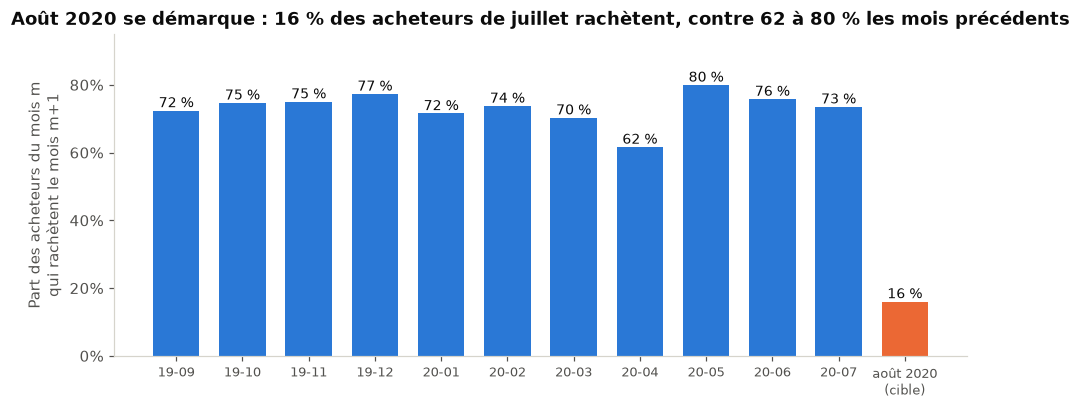

**Anomalie de cadrage, à signaler.** Dans l'historique, 62 % à 80 % des acheteurs d'un mois rachètent le mois suivant, et 43 % de la base est active en juillet 2020.
Or seuls **7,7 % de la base** (et 16 % des acheteurs de juillet) sont positifs en août 2020. Le taux observé équivaut à l'activité de la base sur environ **1,9 jour(s)** d'un mois typique.
Hypothèses (non vérifiables ici, août 2020 n'étant pas fourni) : fenêtre de calcul de la cible plus courte que le mois, extraction partielle d'août, ou rupture réelle d'activité.
**Conséquence pour la suite** : seul le *classement* des clients compte (AUC, top 10 %) ; les probabilités prédites ne sont pas des taux de rachat « mensuels » transposables tels quels, et le niveau absolu de la précision dans le top 10 % ne doit pas être extrapolé à une vraie campagne (question à poser à l'enseignante, et raison de plus de mesurer l'effet réel par un test A/B).

In [7]:
tk_tr['month'] = tk_tr.ts.dt.to_period('M')
active = {m: set(g.id_client) for m, g in tk_tr.groupby('month')}
months = sorted(active)
persist = pd.Series({str(b): len(active[a] & active[b]) / len(active[a]) for a, b in zip(months[:-1], months[1:])})
jul_clients = list(active[months[-1]])
persist['août 2020\n(cible)'] = y.loc[jul_clients].mean()
share_active_jul = len(active[months[-1]]) / len(cl_tr)

# à quelle fenêtre d'un mois « typique » correspond un taux de 7,7 % ? part de la base active pendant les k premiers jours d'un mois
first_days = {}
for k in range(1, 8):
    first_days[k] = np.mean([tk_tr[(tk_tr.ts >= m.to_timestamp()) & (tk_tr.ts < m.to_timestamp() + pd.Timedelta(days=k))].id_client.nunique() / len(cl_tr)
                             for m in months[1:]])
first_days = pd.Series(first_days)
k_eq = float(np.interp(y.mean(), first_days.values, first_days.index.values))
KEY.update(persist_min=float(persist.iloc[:-1].min()), persist_max=float(persist.iloc[:-1].max()), persist_aug=float(persist.iloc[-1]),
           share_active_jul=float(share_active_jul), k_eq_days=k_eq)

fig, ax = plt.subplots(figsize=(10, 3.8))
vals = persist.values
ax.bar(range(len(vals)), vals, color=[c.BLUE] * (len(vals) - 1) + [c.ACCENT], width=0.7)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f'{fr(100 * v, 0)} %', ha='center', fontsize=9)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels([s if '\n' in s else s[2:] for s in persist.index], fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.95)
ax.set_ylabel('Part des acheteurs du mois m\nqui rachètent le mois m+1')
ax.set_title(f'Août 2020 se démarque : {fr(100 * persist.iloc[-1], 0)} % des acheteurs de juillet rachètent, contre {fr(100 * persist.iloc[:-1].min(), 0)} à {fr(100 * persist.iloc[:-1].max(), 0)} % les mois précédents')
savefig(fig, 'cible_vs_activite', f'Les acheteurs de juillet rachètent bien moins en août ({fr(100 * persist.iloc[-1], 0)} %) que d\'un mois à l\'autre dans l\'historique ({fr(100 * persist.iloc[:-1].min(), 0)}-{fr(100 * persist.iloc[:-1].max(), 0)} %) : la cible est plus étroite que « acheter dans le mois ».')

md(f"""**Anomalie de cadrage, à signaler.** Dans l'historique, {pc(KEY['persist_min'], 0)} à {pc(KEY['persist_max'], 0)} des acheteurs d'un mois rachètent le mois suivant, et {pc(share_active_jul, 0)} de la base est active en juillet 2020.
Or seuls **{pc(y.mean(), 1)} de la base** (et {pc(persist.iloc[-1], 0)} des acheteurs de juillet) sont positifs en août 2020. Le taux observé équivaut à l'activité de la base sur environ **{fr(k_eq, 1)} jour(s)** d'un mois typique.
Hypothèses (non vérifiables ici, août 2020 n'étant pas fourni) : fenêtre de calcul de la cible plus courte que le mois, extraction partielle d'août, ou rupture réelle d'activité.
**Conséquence pour la suite** : seul le *classement* des clients compte (AUC, top 10 %) ; les probabilités prédites ne sont pas des taux de rachat « mensuels » transposables tels quels, et le niveau absolu de la précision dans le top 10 % ne doit pas être extrapolé à une vraie campagne (question à poser à l'enseignante, et raison de plus de mesurer l'effet réel par un test A/B).""")
dec('Cadrage', 'repurchase', f'Taux de rachat de la cible ({pc(y.mean(), 1)}) très inférieur à l\'activité mensuelle historique',
    'Conserver la cible telle que fournie ; ne pas interpréter les probabilités comme des taux mensuels ; juger par le classement',
    'Seul le rang des clients sert au ciblage ; la définition exacte de la fenêtre août 2020 n\'est pas vérifiable',
    f"Reconduction mensuelle historique {pc(KEY['persist_min'], 0)}-{pc(KEY['persist_max'], 0)} contre {pc(persist.iloc[-1], 0)} pour juillet vers août 2020",
    'notebooks 06-07 (lecture des scores)')

In [8]:
# ce que la base « garde » du périmètre : combien de clients sont encore proches de la sortie du périmètre ?
rec_all = D_tr.recency
KEY['share_inactive_180'] = float((rec_all > 180).mean())
KEY['only_returns'] = int((D_tr.n_buy == 0).sum())
md(f"""**Périmètre : ce que « client actif sur 12 mois » veut dire dans cette base.** {pc(KEY['share_inactive_180'])} des clients n'ont pas acheté depuis plus de 180 jours : ils sont dans le périmètre grâce à un unique achat ancien,
et leur propension à racheter est très faible (voir partie 6). {KEY['only_returns']} clients n'ont que des tickets de retour (aucun achat), donc ne répondent pas à la définition ; ils sont conservés (effet négligeable, voir partie 3.3).
Il n'existe pas de client « jamais acheteur » : ce score ne servira pas à l'acquisition.""")

**Périmètre : ce que « client actif sur 12 mois » veut dire dans cette base.** 25,3 % des clients n'ont pas acheté depuis plus de 180 jours : ils sont dans le périmètre grâce à un unique achat ancien,
et leur propension à racheter est très faible (voir partie 6). 10 clients n'ont que des tickets de retour (aucun achat), donc ne répondent pas à la définition ; ils sont conservés (effet négligeable, voir partie 3.3).
Il n'existe pas de client « jamais acheteur » : ce score ne servira pas à l'acquisition.

## 3. Qualité des données

Principe (slide 86, « garbage in, garbage out ») : on ne corrige que ce qu'on a mesuré. Chaque sous-partie donne le chiffre, la décision et sa justification ; les décisions sont reprises dans le tableau de la partie 7.

### 3.1 Intégrité générale

In [9]:
dups = int(raw_tr.duplicated().sum())
fmt_ok = int(raw_tr.transaction_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:00\.000Z').sum())
assert fmt_ok == len(raw_tr), 'format de date inattendu'
assert dups == 0
md(f"""- **Doublons parfaits** : {dups} ligne identique sur les {fr(len(raw_tr))} lignes du train.
- **Horodatage** : les {fr(fmt_ok)} dates ont le même format ISO (UTC, minute entière, aucune seconde) ; période `{tk_tr.ts.min():%d/%m/%Y}` → `{tk_tr.ts.max():%d/%m/%Y}` (train), `{tk_te.ts.min():%d/%m/%Y}` → `{tk_te.ts.max():%d/%m/%Y}` (test) : **12 mois pleins, aucune date hors période**.
- **Valeurs numériques manquantes** : 0 (articles, montants, indicateurs de paiement). Aucune imputation numérique n'est nécessaire à ce stade.
- **Horodatage en UTC** : `common._clean` garde l'UTC « naïf », comme la coupure d'août 2020 faite en amont. Heure locale = UTC + 1 h (hiver) ou + 2 h (été) ; seuls les tickets de 22 h à 24 h UTC pourraient changer de jour local,
soit {pc(((tk_tr.ts.dt.hour >= 22)).mean(), 2)} des tickets : effet négligeable, et on ne perd rien à rester en UTC pour construire des délais en jours.""")

- **Doublons parfaits** : 0 ligne identique sur les 3 298 736 lignes du train.
- **Horodatage** : les 3 298 736 dates ont le même format ISO (UTC, minute entière, aucune seconde) ; période `01/08/2019` → `31/07/2020` (train), `01/08/2019` → `31/07/2020` (test) : **12 mois pleins, aucune date hors période**.
- **Valeurs numériques manquantes** : 0 (articles, montants, indicateurs de paiement). Aucune imputation numérique n'est nécessaire à ce stade.
- **Horodatage en UTC** : `common._clean` garde l'UTC « naïf », comme la coupure d'août 2020 faite en amont. Heure locale = UTC + 1 h (hiver) ou + 2 h (été) ; seuls les tickets de 22 h à 24 h UTC pourraient changer de jour local,
soit 0,11 % des tickets : effet négligeable, et on ne perd rien à rester en UTC pour construire des délais en jours.

### 3.2 Plusieurs lignes pour un même (client, instant) : agrégation en tickets
La consigne le prévient : une même date peut apparaître plusieurs fois pour un client. On vérifie qu'il s'agit bien de **parties d'un même ticket** (et non de doublons à supprimer) avant de les additionner.

In [10]:
multi = raw_tr[raw_tr.duplicated(['id_client', 'transaction_date'], keep=False)].copy()
PAY = ['payment_gift', 'payment_cheque', 'payment_cash', 'payment_card']
multi['pay_code'] = (multi[PAY] * np.array([8, 4, 2, 1])).sum(axis=1)
gm = multi.groupby(['id_client', 'transaction_date'])
chk = pd.DataFrame({'lignes': gm.size(), 'modes_paiement_differents': gm.pay_code.nunique() > 1,
                    'magasins_differents': gm.stores_nb.nunique() > 1, 'brut_identique': gm.gross_amount.nunique() == 1,
                    'segment_prix_differents': gm.price_segmentation.nunique() > 1})
n_multi = len(chk)
# conservation : l'agrégation ne perd ni ne crée rien
for col in ['item_count', 'gross_amount', 'discount_amount', 'basket_value']:
    assert np.isclose(raw_tr[col].sum(), tk_tr[col].sum()), col
    assert np.isclose(raw_te[col].sum(), tk_te[col].sum()), col
assert tk_tr.n_lines.sum() == len(raw_tr) and not tk_tr.duplicated(['id_client', 'ts']).any()
assert not chk.segment_prix_differents.any()

KEY.update(lines_removed=len(raw_tr) - len(tk_tr), n_multi=n_multi, multi_share=n_multi / len(tk_tr),
           multi_pay_diff=float(chk.modes_paiement_differents.mean()), multi_same_gross=float(chk.brut_identique.mean()),
           multi_diff_store=int(chk.magasins_differents.sum()))
tab = pd.DataFrame({'Avant (lignes du CSV)': [len(raw_tr), len(raw_te)], 'Après (tickets)': [len(tk_tr), len(tk_te)]}, index=['Train', 'Test'])
tab['Lignes absorbées'] = tab.iloc[:, 0] - tab.iloc[:, 1]
tab['Tickets multi-lignes'] = [n_multi, int((tk_te.n_lines > 1).sum())]
tab['% des tickets'] = (100 * tab['Tickets multi-lignes'] / tab['Après (tickets)']).round(2)
display(tab)
md(f"""Sur {fr(n_multi)} tickets multi-lignes du train : le **mode de paiement diffère entre les lignes dans {pc(KEY['multi_pay_diff'], 0)} des cas** (paiement fractionné : par exemple carte + avoir), le **montant brut n'est identique dans toutes les lignes que dans {pc(KEY['multi_same_gross'], 1)} des cas** (ce ne sont donc pas des doublons),
le segment de prix est toujours le même ; {KEY['multi_diff_store']} tickets seulement mélangent deux magasins (on garde le premier). Le panier médian d'un ticket multi-lignes (après somme) reste du même ordre que celui des autres tickets : sommer est la bonne lecture.
**Décision** : un ticket = un couple (client, instant) ; articles et montants additionnés, indicateurs de paiement combinés (maximum). **Vérifications** : les sommes d'articles, de montants bruts, de remises et de paniers sont conservées à l'euro près,
il n'y a plus aucun doublon (client, instant), et la somme des `n_lines` redonne le nombre de lignes brutes.""")
md(f"""*Limite* : l'horodatage est à la minute ; deux vrais tickets passés la même minute par un même client seraient fusionnés. L'effet maximal est de {fr(KEY['lines_removed'])} lignes (0,17 % des tickets) sur le nombre de tickets, négligeable.""")
dec('Structure', 'id_client, transaction_date', 'Plusieurs lignes pour un même (client, instant)',
    'Agréger en un ticket : somme des articles et montants, maximum des indicateurs de paiement', f'Ce sont des paiements fractionnés (montants bruts différents dans {pc(1 - KEY["multi_same_gross"], 0)} des cas), pas des doublons ; conservation des totaux vérifiée',
    f"{fr(len(raw_tr))} lignes → {fr(len(tk_tr))} tickets ({fr(KEY['lines_removed'])} lignes absorbées, {fr(n_multi)} tickets multi-lignes)", 'common._clean (déjà)')

,Avant (lignes du CSV),Après (tickets),Lignes absorbées,Tickets multi-lignes,% des tickets
Train,3298736,3292994,5742,5691,0.17
Test,824282,822894,1388,1375,0.17


Sur 5 691 tickets multi-lignes du train : le **mode de paiement diffère entre les lignes dans 39 % des cas** (paiement fractionné : par exemple carte + avoir), le **montant brut n'est identique dans toutes les lignes que dans 0,5 % des cas** (ce ne sont donc pas des doublons),
le segment de prix est toujours le même ; 66 tickets seulement mélangent deux magasins (on garde le premier). Le panier médian d'un ticket multi-lignes (après somme) reste du même ordre que celui des autres tickets : sommer est la bonne lecture.
**Décision** : un ticket = un couple (client, instant) ; articles et montants additionnés, indicateurs de paiement combinés (maximum). **Vérifications** : les sommes d'articles, de montants bruts, de remises et de paniers sont conservées à l'euro près,
il n'y a plus aucun doublon (client, instant), et la somme des `n_lines` redonne le nombre de lignes brutes.

*Limite* : l'horodatage est à la minute ; deux vrais tickets passés la même minute par un même client seraient fusionnés. L'effet maximal est de 5 742 lignes (0,17 % des tickets) sur le nombre de tickets, négligeable.

### 3.3 Retours, avoirs, montants négatifs ou nuls

In [11]:
ret = tk_tr[tk_tr.is_return]
buy = tk_tr[~tk_tr.is_return]
n_ret_clients = ret.id_client.nunique()
assert (tk_tr.is_return == (tk_tr.basket_value <= 0)).all()
n_cl = len(D_tr)
odd = pd.DataFrame([
    ('Tickets de retour (panier ≤ 0)', len(ret), len(tk_tr)),
    (' dont panier exactement nul', int((ret.basket_value == 0).sum()), len(tk_tr)),
    (' dont nombre d\'articles négatif', int((ret.item_count < 0).sum()), len(tk_tr)),
    (' dont montant brut négatif', int((ret.gross_amount < 0).sum()), len(tk_tr)),
    ('Tickets d\'achat avec nombre d\'articles ≤ 0', int((buy.item_count <= 0).sum()), len(tk_tr)),
    ('Tickets d\'achat avec remise négative (majoration)', int((buy.discount_amount < 0).sum()), len(tk_tr)),
    ('Tickets d\'achat avec remise ≥ montant brut', int((buy.discount_amount >= buy.gross_amount).sum()), len(tk_tr)),
    ('Clients avec au moins un retour', int(n_ret_clients), n_cl),
    ('Clients dont le dernier ticket est un retour', int((D_tr.last_any != D_tr.last_buy).sum()), n_cl),
    ('Clients sans aucun ticket d\'achat (que des retours)', int((D_tr.n_buy == 0).sum()), n_cl)],
    columns=['indicateur', 'nombre', 'base']).set_index('indicateur')
odd['part (%) de la base'] = 100 * odd['nombre'] / odd['base']
odd['base'] = np.where(odd['base'] == len(tk_tr), 'tickets', 'clients')
odd = odd.rename(columns={'nombre': 'train'})
display(odd.style.format({'train': lambda v: fr(v), 'part (%) de la base': lambda v: fr(v, 3)}))
neg_ca = -ret.basket_value.sum()
KEY.update(n_returns=len(ret), returns_share=len(ret) / len(tk_tr), n_ret_clients=int(n_ret_clients),
           returns_value_share=float(neg_ca / buy.basket_value.sum()))
md(f"""**Lecture.** {fr(len(ret))} tickets sont des retours ou avoirs ({pc(KEY['returns_share'], 2)} des tickets, {pc(n_ret_clients / len(cl_tr), 1)} des clients), pour {fr(neg_ca / 1e3)} k€ restitués ({pc(KEY['returns_value_share'], 2)} du CA d'achat).
Un retour n'est **pas un achat** : un client qui revient échanger un produit n'est pas en train de racheter, et son passage ne doit pas remettre sa récence à zéro.
Mais l'impact est minuscule ici (seuls {fr(odd.loc['Clients dont le dernier ticket est un retour', 'train'])} clients ont un retour comme dernier ticket).
Quelques tickets d'achat sont atypiques (articles ≤ 0, remise négative = majoration) : trop rares pour justifier une règle, ils sont neutralisés par le plafonnement (partie 4).
**Décision** : conserver les retours dans la table de tickets avec le drapeau `is_return` ; calculer récence, fréquence et panier moyen **sur les tickets d'achat** ; garder le nombre / la part de retours comme variable candidate (le retour est un signal de service après-vente).""")
dec('Retours', 'basket_value, item_count', 'Tickets de retour / avoir (panier ≤ 0, articles négatifs)',
    'Drapeau is_return conservé ; récence, fréquence, panier calculés hors retours ; part de retours gardée comme feature candidate',
    'Un retour n\'est pas un achat et ne doit pas rajeunir la récence ; la perte d\'information est nulle (tickets conservés)',
    f"{fr(len(ret))} tickets ({pc(KEY['returns_share'], 2)}), {fr(n_ret_clients)} clients ; {odd.loc['Clients dont le dernier ticket est un retour', 'train']} clients dont le dernier ticket est un retour", 'common._clean (drapeau) + notebook 02 (usage)')

,train,base,part (%) de la base
indicateur,,,
Tickets de retour (panier ≤ 0),6 854,tickets,"0,208"
dont panier exactement nul,28,tickets,"0,001"
dont nombre d'articles négatif,6 288,tickets,"0,191"
dont montant brut négatif,6 817,tickets,"0,207"
Tickets d'achat avec nombre d'articles ≤ 0,333,tickets,"0,010"
Tickets d'achat avec remise négative (majoration),1 777,tickets,"0,054"
Tickets d'achat avec remise ≥ montant brut,0,tickets,"0,000"
Clients avec au moins un retour,3 625,clients,"2,260"
Clients dont le dernier ticket est un retour,190,clients,"0,118"


**Lecture.** 6 854 tickets sont des retours ou avoirs (0,21 % des tickets, 2,3 % des clients), pour 248 k€ restitués (0,16 % du CA d'achat).
Un retour n'est **pas un achat** : un client qui revient échanger un produit n'est pas en train de racheter, et son passage ne doit pas remettre sa récence à zéro.
Mais l'impact est minuscule ici (seuls 190 clients ont un retour comme dernier ticket).
Quelques tickets d'achat sont atypiques (articles ≤ 0, remise négative = majoration) : trop rares pour justifier une règle, ils sont neutralisés par le plafonnement (partie 4).
**Décision** : conserver les retours dans la table de tickets avec le drapeau `is_return` ; calculer récence, fréquence et panier moyen **sur les tickets d'achat** ; garder le nombre / la part de retours comme variable candidate (le retour est un signal de service après-vente).

### 3.4 Cohérence interne des montants : brut − remises = payé

In [12]:
gap_line = (raw_tr.gross_amount - raw_tr.discount_amount - raw_tr.basket_value).abs()
gap_tk = (tk_tr.gross_amount - tk_tr.discount_amount - tk_tr.basket_value).abs()
assert gap_line.max() < 1e-6 and gap_tk.max() < 1e-6
dr = (buy.discount_amount / buy.gross_amount).where(buy.gross_amount > 0)
KEY['disc_rate_mean'] = float((buy.discount_amount.sum() / buy.gross_amount.sum()))
KEY['disc_share_tickets'] = float((buy.discount_amount > 0).mean())
md(f"""`basket_value = gross_amount − discount_amount` est **exact** (écart maximal : {gap_line.max():.1e} € par ligne, {gap_tk.max():.1e} € par ticket, c'est-à-dire de l'arrondi informatique).
Les trois montants sont donc **parfaitement colinéaires** : il ne faut garder que deux d'entre eux dans un modèle linéaire (sinon matrice singulière, coefficients instables).
On gardera le panier payé et le **taux de remise** (remise / brut), bien plus parlant pour un marketeur : {pc(KEY['disc_share_tickets'], 0)} des tickets d'achat contiennent une remise, qui représente en moyenne {pc(KEY['disc_rate_mean'], 1)} du montant brut.""")
dec('Montants', 'gross_amount, discount_amount, basket_value', 'basket_value = gross − discount exactement (colinéarité parfaite)',
    'Ne conserver que le panier payé (basket_value) et le taux de remise (remise / brut, plafonné à [0, 1]) ; supprimer gross_amount des features',
    'Évite une colinéarité parfaite (régressions pénalisées, logistique) et donne une variable commerciale lisible',
    f"écart max {gap_tk.max():.0e} € ; remise moyenne = {pc(KEY['disc_rate_mean'], 1)} du brut sur les tickets d'achat", 'notebook 02')

`basket_value = gross_amount − discount_amount` est **exact** (écart maximal : 9.1e-13 € par ligne, 9.1e-13 € par ticket, c'est-à-dire de l'arrondi informatique).
Les trois montants sont donc **parfaitement colinéaires** : il ne faut garder que deux d'entre eux dans un modèle linéaire (sinon matrice singulière, coefficients instables).
On gardera le panier payé et le **taux de remise** (remise / brut), bien plus parlant pour un marketeur : 39 % des tickets d'achat contiennent une remise, qui représente en moyenne 6,9 % du montant brut.

### 3.5 Zéro initial perdu ? `stores_nb` oui, `zip_code` non
Les codes ont-ils été lus comme des nombres quelque part en amont, ce qui ferait perdre le zéro des départements 01 à 09 (`6923` au lieu de `06923`) ? On le teste séparément pour le magasin et pour le code postal : sans zéro, `6923` serait lu « département 69 » (Rhône) au lieu de `06`. Le test : le département du magasin doit concorder avec le département de résidence du client.

In [13]:
VALID_DEPT = {f'{i:02d}' for i in range(1, 96)} | {'97', '98'}      # 01-95, 97 (DOM), 98 (Monaco)
# --- stores_nb
n4_store = int((raw_tr.stores_nb < 10000).sum())
stores = pd.Series(tk_tr.store5.unique())
n_stores = len(stores)
n_stores_4 = int((stores.str[0] == '0').sum())
zr = att_first.zip_code
z5 = zr.str.fullmatch(r'\d{5}', na=False)
z4 = zr.str.fullmatch(r'\d{4}', na=False)
D_tr['zip5_ok'] = z5.reindex(D_tr.index)
Dk = D_tr[D_tr.zip5_ok & D_tr.dept.isin(VALID_DEPT)]                  # clients à code postal à 5 chiffres, département valide
mode4 = Dk.store_mode.str[0] == '0'
naive_region = Dk.store_mode.str.lstrip('0').str[:2]
match_fix = (Dk.dept == Dk.region)[mode4].mean()
match_naive = (Dk.dept == naive_region)[mode4].mean()
match_5 = (Dk.dept == Dk.region)[~mode4].mean()
same_dept = Dk.dept == Dk.region
last3_match = (Dk.store_mode.str[2:] == Dk.zip5.str[2:])[same_dept].mean()
# --- zip_code : les codes à 5 chiffres commençant par 0 existent-ils ? que sont les codes à 4 chiffres ?
n_zip5_zero = int((zr[z5].str[0] == '0').sum())
z4_ids = zr.index[z4]
reg_z4 = D_tr.region.reindex(z4_ids)
top_reg = reg_z4.value_counts()
dept_if_zfill = ('0' + zr[z4_ids]).str[:2]                            # ce que donnerait un zfill(5) sur ces codes
match_z4_fix = (dept_if_zfill == reg_z4).mean()
match_z4_naive = (zr[z4_ids].str[:2] == reg_z4).mean()
n_dept_false = int(dept_if_zfill.isin([f'{i:02d}' for i in range(1, 10)]).sum())
# règle appliquée par common._clean : codes à 4 chiffres -> dept « ETR », codes à 5 chiffres inchangés
assert (D_tr.dept.reindex(z4_ids) == 'ETR').all() and D_tr.zip5.reindex(z4_ids).isna().all()
KEY.update(store4_lines_share=n4_store / len(raw_tr), n_stores=n_stores, zip4_clients=int(z4.sum()), zip4_lines=int((raw_tr.zip_code.str.len() == 4).sum()),
           zip5_zero=n_zip5_zero, zip4_top4_share=float(top_reg.iloc[:4].sum() / top_reg.sum()), match_dept_region=float(same_dept.mean()))
tab = pd.DataFrame({
    'Cas': [f'stores_nb à 4 chiffres : {fr(n4_store)} lignes ({pc(n4_store / len(raw_tr))}), {n_stores_4} magasins sur {fr(n_stores)}',
            f'zip_code à 5 chiffres commençant par 0 : {fr(n_zip5_zero)} clients (zéro conservé)',
            f'zip_code à 4 chiffres : {fr(z4.sum())} clients ({fr(KEY["zip4_lines"])} lignes)'],
    'Département client = département magasin, zéro rétabli': [pc(match_fix, 1), pc(same_dept[~mode4].mean(), 1) + ' (référence)', pc(match_z4_fix, 1)],
    'Même test sans rétablir le zéro': [pc(match_naive, 1), '', pc(match_z4_naive, 1)]})
display(tab.set_index('Cas'))
assert (tk_tr.store5.str.len() == 5).all()
display(top_reg.head(5).rename('clients à code postal à 4 chiffres').to_frame().rename_axis('département du magasin'))
md(f"""**Magasins : zéro perdu, rétabli.** Sans le zéro, les magasins des départements 01 à 09 sont rangés dans de faux départements et la concordance avec le département du client s'effondre ({pc(match_naive, 0)} contre {pc(match_fix, 0)} une fois le zéro rétabli ; référence pour les magasins à 5 chiffres : {pc(match_5, 0)}). `common._clean` applique `zfill(5)` au code magasin : correct. 
**Les 3 derniers chiffres de `stores_nb` ne forment pas un code postal** : à département identique, ils coïncident avec la partie « commune » du code postal du client dans {pc(last3_match, 1)} des cas (le hasard), et ne prennent que {stores.str[2:].nunique()} valeurs distinctes pour {fr(n_stores)} magasins : c'est un **numéro de magasin interne au département**. 
Seuls les 2 premiers chiffres (le département) sont exploitables ; le numéro de magasin identifie un des {fr(n_stores)} points de vente (à regrouper, pas à encoder tel quel).

**Codes postaux : le zéro n'est PAS perdu, les codes à 4 chiffres sont étrangers.** {fr(n_zip5_zero)} clients ont un code à 5 chiffres commençant par 0 (départements 01-09) : la colonne est un texte intact. Les {fr(z4.sum())} codes à **4 chiffres** ne sont donc pas des codes français tronqués : 
rétablir un zéro ne les ramènerait dans le bon département que dans {pc(match_z4_fix, 0)} des cas, contre {pc(same_dept[~mode4].mean(), 0)} pour les codes ordinaires ; leurs magasins sont dans les départements frontaliers (74, 68, 25, 08 : {pc(KEY['zip4_top4_share'], 0)} d'entre eux, Haute-Savoie, Haut-Rhin, Doubs, Ardennes). 
Ce sont des **codes postaux suisses et belges** (`1223`, `1206` : Genève ; `4054` : Bâle ; `6xxx` : Belgique) : un `zfill(5)` aurait rangé {fr(n_dept_false)} clients étrangers dans les départements 01 à 09 (Genève → `01223`, dépt « 01 » Ain). 
**Règle appliquée par `common._clean`** (corrigée après la première version de ce notebook) : pas de zéro rétabli sur les codes postaux ; les codes à 4 chiffres donnent `dept = 'ETR'` (étranger) et `zip5` manquant ; seuls les codes à 5 chiffres (hors « 00000 ») sont conservés.""")
dec('Codes', 'stores_nb', 'Zéro initial perdu (4 chiffres pour les départements 01-09) ; les 3 derniers chiffres ne sont pas un code postal',
    'zfill(5) -> store5 ; département = 2 premiers chiffres (store_region) ; jamais les 3 derniers comme code postal', 'Concordance avec le département du client : de ' + pc(match_naive, 0) + ' à ' + pc(match_fix, 0),
    f"{fr(n4_store)} lignes ({pc(n4_store / len(raw_tr))}), {n_stores_4} magasins", 'common._clean')
dec('Codes', 'zip_code', 'Le zéro initial n\'est pas perdu : les codes à 4 chiffres sont des codes étrangers (Suisse, Belgique)',
    'Pas de zfill sur les codes postaux ; codes à 4 chiffres -> dept = « ETR » et zip5 manquant ; dept = 2 premiers chiffres des codes à 5 chiffres', 'Rétablir un zéro ne ramènerait dans le bon département que ' + pc(match_z4_fix, 0) + ' des clients concernés (contre ' + pc(same_dept[~mode4].mean(), 0) + ' pour les codes ordinaires) ; magasins en zone frontalière',
    f"{fr(z4.sum())} clients ({fr(n_dept_false)} auraient été rangés à tort en départements 01-09)", 'common._clean')

,"Département client = département magasin, zéro rétabli",Même test sans rétablir le zéro
Cas,,
"stores_nb à 4 chiffres : 292 012 lignes (8,9 %), 161 magasins sur 1 453","85,6 %","0,2 %"
zip_code à 5 chiffres commençant par 0 : 10 272 clients (zéro conservé),"89,7 % (référence)",
zip_code à 4 chiffres : 554 clients (4 223 lignes),"3,6 %","0,5 %"


,clients à code postal à 4 chiffres
département du magasin,
74,204
68,86
25,85
08,55
83,40


**Magasins : zéro perdu, rétabli.** Sans le zéro, les magasins des départements 01 à 09 sont rangés dans de faux départements et la concordance avec le département du client s'effondre (0 % contre 86 % une fois le zéro rétabli ; référence pour les magasins à 5 chiffres : 90 %). `common._clean` applique `zfill(5)` au code magasin : correct. 
**Les 3 derniers chiffres de `stores_nb` ne forment pas un code postal** : à département identique, ils coïncident avec la partie « commune » du code postal du client dans 0,5 % des cas (le hasard), et ne prennent que 779 valeurs distinctes pour 1 453 magasins : c'est un **numéro de magasin interne au département**. 
Seuls les 2 premiers chiffres (le département) sont exploitables ; le numéro de magasin identifie un des 1 453 points de vente (à regrouper, pas à encoder tel quel).

**Codes postaux : le zéro n'est PAS perdu, les codes à 4 chiffres sont étrangers.** 10 272 clients ont un code à 5 chiffres commençant par 0 (départements 01-09) : la colonne est un texte intact. Les 554 codes à **4 chiffres** ne sont donc pas des codes français tronqués : 
rétablir un zéro ne les ramènerait dans le bon département que dans 4 % des cas, contre 90 % pour les codes ordinaires ; leurs magasins sont dans les départements frontaliers (74, 68, 25, 08 : 78 % d'entre eux, Haute-Savoie, Haut-Rhin, Doubs, Ardennes). 
Ce sont des **codes postaux suisses et belges** (`1223`, `1206` : Genève ; `4054` : Bâle ; `6xxx` : Belgique) : un `zfill(5)` aurait rangé 554 clients étrangers dans les départements 01 à 09 (Genève → `01223`, dépt « 01 » Ain). 
**Règle appliquée par `common._clean`** (corrigée après la première version de ce notebook) : pas de zéro rétabli sur les codes postaux ; les codes à 4 chiffres donnent `dept = 'ETR'` (étranger) et `zip5` manquant ; seuls les codes à 5 chiffres (hors « 00000 ») sont conservés.

### 3.6 Codes postaux invalides ou manquants
Que devient le code postal après `common._clean` ? On le décompose, et on vérifie les règles par assertion : `zip5` = code à 5 chiffres valide ; `dept` = 2 premiers chiffres, `ETR` pour les codes à 4 chiffres, manquant sinon.

In [14]:
placeholder = zr.str.fullmatch(r'0{4,5}', na=False)
bad_fmt = zr.notna() & ~zr.str.fullmatch(r'\d{4,5}', na=False)
cat = pd.Series('code français valide (5 chiffres)', index=zr.index)
cat[z4] = 'code à 4 chiffres (étranger : Suisse, Belgique)'
cat[zr.isna()] = 'manquant'
cat[bad_fmt] = 'format invalide (lettres, ponctuation, étranger, trop court)'
cat[placeholder] = 'placeholder « 00000 » (département inexistant)'
bad_dept_ids = D_tr.index[D_tr.zip5.notna() & ~D_tr.dept.isin(VALID_DEPT)]
cat[bad_dept_ids] = 'département inexistant (hors 01-95, 97, 98)'
tabz = cat.value_counts().to_frame('clients')
tabz['% des clients'] = (100 * tabz.clients / len(cat)).round(2)
display(tabz)
# règles de common._clean : vérifiées à partir du brut, sur le train et le test
for nm, raw_, cl_ in [('train', raw_tr, cl_tr), ('test', raw_te, cl_te)]:
    zz = raw_.groupby('id_client').zip_code.first().reindex(cl_.index)
    f4, ok5 = zz.str.fullmatch(r'\d{4}', na=False), zz.str.fullmatch(r'\d{5}', na=False) & (zz != '00000')
    assert (cl_.zip5[ok5] == zz[ok5]).all() and cl_.zip5[~ok5].isna().all(), nm
    assert (cl_.dept[f4] == 'ETR').all() and (cl_.dept[ok5] == zz[ok5].str[:2]).all() and cl_.dept[~(f4 | ok5)].isna().all(), nm
    assert not (cl_.zip5 == '00000').any(), nm
n_rows_zip_na = int(raw_tr.zip_code.isna().sum())
KEY.update(zip_missing_rows=n_rows_zip_na / len(raw_tr), zip_missing_clients=float(D_tr.zip5.isna().mean()), zip_unknown_fix=float(D_tr.dept.isna().mean()),
           zip_placeholder=int(placeholder.sum()), zip_bad_fmt=int(bad_fmt.sum()), zip_raw_missing=int(zr.isna().sum()), zip_bad_dept=len(bad_dept_ids))
md(f"""**Lecture.** Au niveau **ligne**, {pc(KEY['zip_missing_rows'])} des lignes n'ont pas de code postal ; au niveau **client**, {pc(zr.isna().mean())} des clients n'en ont aucun, 
et {fr(bad_fmt.sum())} autres ont un texte inexploitable (adresses étrangères : `KT16`, `GENEV`, `CH`, `RG4 6`…, ou ponctuation `.....`). **{fr(placeholder.sum())} clients** ont le code par défaut « 00000 » (département « 00 » inexistant). 
Après `common._clean`, **{pc(KEY['zip_unknown_fix'])} des clients n'ont pas de département de résidence** (`dept` manquant), {pc((D_tr.dept == 'ETR').mean(), 2)} sont à l'étranger (`ETR`), et {KEY['zip_bad_dept']} ont un département inexistant (hors 01-95, 97, 98) : trop rares pour justifier une règle (à regrouper en « inconnu »). 
**Décision** : ne pas imputer la résidence (aucune règle métier fiable ; l'imputer par le département du magasin mélangerait résidence et lieu d'achat). Le département du client devient une catégorielle avec une modalité « inconnu » (manquant) et une modalité « étranger » (`ETR`) ; 
il reste le département du **magasin**, jamais manquant, comme information géographique de repli.""")
dec('Codes', 'zip_code', 'Manquant ou invalide (ponctuation, étranger) ; « 00000 » = valeur par défaut',
    'common._clean : zip5 = code à 5 chiffres valide (« 00000 » exclu) ; pas d\'imputation : dept manquant = « inconnu » ; département du magasin en repli', 'La résidence n\'est pas déductible du magasin ; imputer créerait de la fausse information',
    f"{pc(KEY['zip_unknown_fix'])} des clients sans département ; dont {fr(placeholder.sum())} « 00000 »", 'common._clean')

,clients,% des clients
code français valide (5 chiffres),129106,80.48
manquant,30452,18.98
"code à 4 chiffres (étranger : Suisse, Belgique)",554,0.35
placeholder « 00000 » (département inexistant),274,0.17
"format invalide (lettres, ponctuation, étranger, trop court)",35,0.02
"département inexistant (hors 01-95, 97, 98)",3,0.00


**Lecture.** Au niveau **ligne**, 9,2 % des lignes n'ont pas de code postal ; au niveau **client**, 19,0 % des clients n'en ont aucun, 
et 35 autres ont un texte inexploitable (adresses étrangères : `KT16`, `GENEV`, `CH`, `RG4 6`…, ou ponctuation `.....`). **274 clients** ont le code par défaut « 00000 » (département « 00 » inexistant). 
Après `common._clean`, **19,2 % des clients n'ont pas de département de résidence** (`dept` manquant), 0,35 % sont à l'étranger (`ETR`), et 3 ont un département inexistant (hors 01-95, 97, 98) : trop rares pour justifier une règle (à regrouper en « inconnu »). 
**Décision** : ne pas imputer la résidence (aucune règle métier fiable ; l'imputer par le département du magasin mélangerait résidence et lieu d'achat). Le département du client devient une catégorielle avec une modalité « inconnu » (manquant) et une modalité « étranger » (`ETR`) ; 
il reste le département du **magasin**, jamais manquant, comme information géographique de repli.

### 3.7 `card_subscription` (carte de fidélité) et `multicard`
`card_subscription` est une **date d'adhésion** au format JJ/MM/AAAA (et non un indicateur oui/non comme le suggère l'énoncé) ; vide pour l'immense majorité des clients.

- **Part de clients avec carte** : 3,1 % (4 954 clients ont une valeur) ; au niveau ligne, 93,4 % des lignes sont vides, car les adhérents achètent un peu plus souvent.
- **Valeur corrompue** : un client (`id_client` 21052729, 44 lignes) a pour « date » le texte `RÉPUBLIQUE DÉMOCRATIQUE"` : enregistrement manifestement corrompu à la source (le même client porte aussi `multicard` = 21 et `price_segmentation` = 08, voir 3.8).
`pd.to_datetime(errors='coerce')` le transforme en date manquante : la date n'est valide que pour 4 953 clients.
- **Date par défaut probable** : 152 clients adhèrent un 01/01/2016, contre au plus 110 pour n'importe quelle autre date : migration du système de fidélité ou date par défaut ; l'ancienneté de ces clients est donc imprécise.
- **Dates postérieures à l'historique** : 4 clients ont une date d'adhésion **après le 31/07/2020** (jusqu'au 13/08/2020), c'est-à-dire dans le futur par rapport à la photo des données : l'ancienneté à la date de référence serait négative.
On la plafonne à 0 et on garde la date comme information « adhésion récente » (1 470 adhésions pendant l'année observée, avec des pics autour du 5-7 novembre 2019 : probablement une opération de recrutement à la carte).

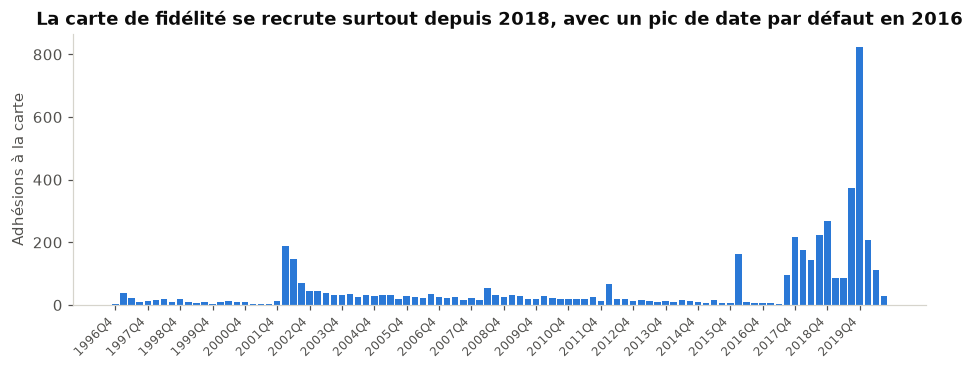

**`multicard`** : 154 797 clients à 0, 4 897 à 1 (3,1 % des clients renseignés), 730 manquants (les 729 profils anonymes + le client dont la ligne est corrompue).
La valeur brute 21 n'apparaît que sur 44 lignes, **toutes du même client** : `common._clean` ne garde que 0/1 et met le reste à manquant (vérifié par assertion plus bas).

In [15]:
cs = att_first.card_subscription
cd = D_tr.card_date
n_card_text = int(cs.notna().sum())
n_card_date = int(cd.notna().sum())
corrupt = cs[cs.notna() & cd.reindex(cs.index).isna()]
assert len(corrupt) == 1
top_dates = cd.value_counts()
fut = cd[cd >= c.REF_DATE]
in_window = ((cd >= c.START_DATE) & (cd < c.REF_DATE)).sum()
KEY.update(card_share=float(D_tr.has_card.mean()), card_valid=n_card_date, card_corrupt=len(corrupt), card_default_date=int(top_dates.iloc[0]),
           card_future=len(fut), card_in_window=int(in_window), card_row_na=float(raw_tr.card_subscription.isna().mean()))
md(f"""- **Part de clients avec carte** : {pc(KEY['card_share'])} ({fr(n_card_text)} clients ont une valeur) ; au niveau ligne, {pc(KEY['card_row_na'])} des lignes sont vides, car les adhérents achètent un peu plus souvent.
- **Valeur corrompue** : un client (`id_client` {corrupt.index[0]}, {int((raw_tr.id_client == corrupt.index[0]).sum())} lignes) a pour « date » le texte `{corrupt.iloc[0]}` : enregistrement manifestement corrompu à la source (le même client porte aussi `multicard` = 21 et `price_segmentation` = 08, voir 3.8).
`pd.to_datetime(errors='coerce')` le transforme en date manquante : la date n'est valide que pour {fr(n_card_date)} clients.
- **Date par défaut probable** : {int(top_dates.iloc[0])} clients adhèrent un 01/01/2016, contre au plus {int(top_dates.iloc[1])} pour n'importe quelle autre date : migration du système de fidélité ou date par défaut ; l'ancienneté de ces clients est donc imprécise.
- **Dates postérieures à l'historique** : {len(fut)} clients ont une date d'adhésion **après le 31/07/2020** (jusqu'au {cd.max():%d/%m/%Y}), c'est-à-dire dans le futur par rapport à la photo des données : l'ancienneté à la date de référence serait négative.
On la plafonne à 0 et on garde la date comme information « adhésion récente » ({fr(in_window)} adhésions pendant l'année observée, avec des pics autour du 5-7 novembre 2019 : probablement une opération de recrutement à la carte).""")

fig, ax = plt.subplots(figsize=(10, 3.2))
s = cd.dropna().dt.to_period('Q').value_counts().sort_index()
ax.bar(s.index.astype(str), s.values, color=c.BLUE)
ax.set_xticks(range(0, len(s), 4))
ax.set_xticklabels(s.index.astype(str)[::4], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Adhésions à la carte')
ax.set_title('La carte de fidélité se recrute surtout depuis 2018, avec un pic de date par défaut en 2016')
savefig(fig, 'carte_adhesions', f'Les adhésions à la carte de fidélité s\'accélèrent depuis 2018 ; {KEY["card_default_date"]} clients partagent la même date (01/01/2016), probablement une date par défaut.')

mc = D_tr.multicard
md(f"""**`multicard`** : {fr((mc == 0).sum())} clients à 0, {fr((mc == 1).sum())} à 1 ({pc((mc == 1).sum() / mc.notna().sum())} des clients renseignés), {fr(mc.isna().sum())} manquants (les {fr(D_tr.anonymous.sum())} profils anonymes + le client dont la ligne est corrompue).
La valeur brute 21 n'apparaît que sur {int((raw_tr.multicard == 21).sum())} lignes, **toutes du même client** : `common._clean` ne garde que 0/1 et met le reste à manquant (vérifié par assertion plus bas).""")
dec('Fidélité', 'card_subscription', f'Date et non indicateur ; {pc(1 - KEY["card_share"])} de vides ; {len(corrupt)} valeur textuelle corrompue ; date par défaut 01/01/2016 ; {len(fut)} dates postérieures au 31/07/2020',
    'has_card = date valide (le texte corrompu n\'est plus compté) ; date parsée (JJ/MM/AAAA, invalide -> manquant) ; ancienneté à la date de référence plafonnée à 0 ; indicatrice « adhésion récente »', f'La date apporte une ancienneté, mais ne vaut rien pour les adhésions futures ; {pc(1 - KEY["card_share"])} de vides interdisent d\'imputer',
    f"{pc(KEY['card_share'])} de clients avec carte ; {fr(n_card_date)} dates valides ; {len(corrupt)} corrompue ; {len(fut)} dates futures", 'common._clean (has_card, parsing) + notebook 02 (ancienneté)')
dec('Fidélité', 'multicard', f'Valeur aberrante 21 ({int((raw_tr.multicard == 21).sum())} lignes, 1 client) ; manquant pour les anonymes',
    'Valeur 21 -> manquant ; manquant gardé comme modalité « inconnu » (3e modalité)', 'Seules 0 et 1 sont définies ; le manquant coïncide avec les profils anonymes, c\'est une information',
    f"{fr(mc.isna().sum())} clients manquants ({pc(mc.isna().mean(), 2)})", 'common._clean (déjà)')

### 3.8 Le client à l'enregistrement corrompu : `price_segmentation` = `08`, `multicard` = 21, carte « RÉPUBLIQUE DÉMOCRATIQUE" »

In [16]:
bad_id = corrupt.index[0]
rows_bad = raw_tr[raw_tr.id_client == bad_id]
n_08 = int((raw_tr.price_segmentation == '08').sum())
n_08_clean = int((tk_tr.price_segmentation.isin(['08', '8'])).sum())
ids_21 = set(raw_tr.loc[raw_tr.multicard == 21, 'id_client'])
ids_08 = set(raw_tr.loc[raw_tr.price_segmentation == '08', 'id_client'])
print(f'Client {bad_id} : {len(rows_bad)} lignes ; lignes à price_segmentation = 08 : {n_08} ; toutes de ce client : {ids_08 == {bad_id}}')
print(f'Lignes à multicard = 21 : {int((raw_tr.multicard == 21).sum())} ; toutes de ce client : {ids_21 == {bad_id}}')
print(f'Tickets à price_segmentation 08/8 après nettoyage : {n_08_clean} ; segment de ce client après nettoyage : {tk_tr.loc[tk_tr.id_client == bad_id, "price_segmentation"].isna().all()} (manquant) ; has_card : {bool(cl_tr.loc[bad_id, "has_card"])}')
print(f'Lignes avec la chaîne DÉMOCRATIQUE dans le test : {int(raw_te.card_subscription.fillna("").str.contains("DÉMOCRATIQUE").sum())}')
display(rows_bad.drop(columns=['transaction_date']).head(3))
assert ids_08 == {bad_id} and ids_21 == {bad_id}
assert n_08_clean == 0 and tk_tr.loc[tk_tr.id_client == bad_id, 'price_segmentation'].isna().all() and not cl_tr.loc[bad_id, 'has_card'] and np.isnan(cl_tr.loc[bad_id, 'multicard'])
assert set(tk_tr.price_segmentation.dropna().unique()) == {'Access', 'Mixte', 'Quali', 'xx'}
assert set(raw_tr.price_segmentation.dropna().unique()) == {'Access', 'Mixte', 'Quali', 'xx', '08'}
KEY['bad_client_lines'] = len(rows_bad)
md(f"""**Trouvaille.** Les trois anomalies (`card_subscription` textuelle, `multicard` = 21, `price_segmentation` = `08`) viennent **d'un seul et même client** ({len(rows_bad)} lignes) : un texte libre (un nom de pays tronqué) se trouve dans le champ date, et les deux champs suivants sont eux aussi hors domaine : probable décalage de colonnes à la source.
Conséquence : la modalité `8` décrite dans l'énoncé (« produits à prix différents mais dans la même gamme ») **n'existe pas dans les données** ; `08` ne vient que de ce client. 
Une première version de `common._clean` la renommait en `8` ; la version actuelle met `08` à **manquant**, et le client a désormais `has_card` faux et `multicard` manquant (assertions ci-dessus) : il reste avec ses tickets (valides), mais sans attribut fiable. 
Le **test ne contient aucune ligne de ce type**. Après nettoyage, `price_segmentation` a donc quatre modalités (Access, Mixte, Quali, xx) plus le manquant.""")
dec('Qualité', 'price_segmentation, card_subscription, multicard', f'Un seul client ({len(rows_bad)} lignes) a un enregistrement décalé : « 08 », « RÉPUBLIQUE DÉMOCRATIQUE" », 21',
    'Conserver le client et ses tickets ; price_segmentation « 08 » -> manquant, has_card faux, multicard manquant (common._clean)', 'Les champs sont décalés, donc non fiables ; les montants et dates restent valides ; la modalité « 8 » n\'existe nulle part ailleurs ni dans le test',
    f"1 client, {len(rows_bad)} lignes ; 0 ligne dans le test", 'common._clean')

Client 21052729 : 44 lignes ; lignes à price_segmentation = 08 : 44 ; toutes de ce client : True
Lignes à multicard = 21 : 44 ; toutes de ce client : True
Tickets à price_segmentation 08/8 après nettoyage : 0 ; segment de ce client après nettoyage : True (manquant) ; has_card : False
Lignes avec la chaîne DÉMOCRATIQUE dans le test : 0


,id_client,stores_nb,item_count,gross_amount,discount_amount,basket_value,payment_gift,payment_cheque,payment_cash,payment_card,email_domain,civility,zip_code,card_subscription,multicard,price_segmentation
726,21052729,41573,5,35.14,0.0,35.14,0,0,0,1,NaN,MME,41150,"RÉPUBLIQUE DÉMOCRATIQUE""",21.0,08
16438,21052729,41573,15,34.67,0.0,34.67,0,0,0,1,NaN,MME,41150,"RÉPUBLIQUE DÉMOCRATIQUE""",21.0,08
176493,21052729,41573,4,9.10,0.0,9.10,0,0,1,0,NaN,MME,41150,"RÉPUBLIQUE DÉMOCRATIQUE""",21.0,08


**Trouvaille.** Les trois anomalies (`card_subscription` textuelle, `multicard` = 21, `price_segmentation` = `08`) viennent **d'un seul et même client** (44 lignes) : un texte libre (un nom de pays tronqué) se trouve dans le champ date, et les deux champs suivants sont eux aussi hors domaine : probable décalage de colonnes à la source.
Conséquence : la modalité `8` décrite dans l'énoncé (« produits à prix différents mais dans la même gamme ») **n'existe pas dans les données** ; `08` ne vient que de ce client. 
Une première version de `common._clean` la renommait en `8` ; la version actuelle met `08` à **manquant**, et le client a désormais `has_card` faux et `multicard` manquant (assertions ci-dessus) : il reste avec ses tickets (valides), mais sans attribut fiable. 
Le **test ne contient aucune ligne de ce type**. Après nettoyage, `price_segmentation` a donc quatre modalités (Access, Mixte, Quali, xx) plus le manquant.

### 3.9 Profils anonymes et civilité

In [17]:
an = D_tr[D_tr.anonymous]
rest = D_tr[~D_tr.anonymous]
assert (D_tr.anonymous == (D_tr.civility == 'ND')).all()
anon_tab = pd.DataFrame({
    'Anonymes': [len(an), an.n_tickets.mean(), an.n_tickets.median(), 100 * an.has_email.mean(), 100 * an.zip5.notna().mean(), 100 * an.y.mean()],
    'Autres clients': [len(rest), rest.n_tickets.mean(), rest.n_tickets.median(), 100 * rest.has_email.mean(), 100 * rest.zip5.notna().mean(), 100 * rest.y.mean()]},
    index=['Clients', 'Tickets par client (moyenne)', 'Tickets par client (médiane)', '% avec e-mail', '% avec code postal valide', 'Taux de rachat (%)'])
display(anon_tab.round(2))
anon_te = int(D_te.anonymous.sum())
KEY.update(anon_n=len(an), anon_share=len(an) / len(D_tr), anon_rate=float(an.y.mean()), anon_te=anon_te)
civ = D_tr.civility.value_counts()
md(f"""**Lecture.** {fr(len(an))} clients ({pc(len(an) / len(D_tr), 2)}) n'ont ni civilité ni `multicard` : ce sont des **achats sans fiche client** (caisse sans identification complète).
Leur taux de rachat est de {pc(an.y.mean(), 2)} contre {pc(rest.y.mean(), 2)} pour les autres, avec {fr(an.n_tickets.mean(), 1)} tickets en moyenne contre {fr(rest.n_tickets.mean(), 1)} : ils ressemblent à des passages uniques. {anon_te} profils anonymes dans le test ({pc(anon_te / len(D_te), 2)}).
**Décision** : les conserver (4 clients sur 1 000, aucun gain à les retirer) mais les identifier par un indicateur `anonymous` qui évite que « manquant » soit confondu avec « civilité NR ».
La modalité **`NR`** (non renseigné ; {pc(civ['NR'] / len(D_tr))} des clients) est une réponse explicite, différente de `ND` (profil anonyme, `NaN` brut) : on garde 4 modalités (M, MME, NR, ND), ce qui donne 3 indicatrices au codage (N−1).""")
dec('Manquants', 'civility, multicard', 'Profils anonymes : civilité et multicard absentes (' + pc(len(an) / len(D_tr), 2) + ' des clients, rachat ' + pc(an.y.mean(), 1) + ')',
    'Conserver ; indicateur anonymous ; civilité ND distincte de NR', 'Clients réels et très peu actifs : les retirer n\'apporterait rien, les conserver avec un drapeau laisse le modèle ajuster',
    f"{fr(len(an))} clients ({pc(len(an) / len(D_tr), 2)}) ; rachat {pc(an.y.mean(), 2)} vs {pc(rest.y.mean(), 2)}", 'common._clean (drapeau) + notebook 02')

,Anonymes,Autres clients
Clients,729.00,159695.00
Tickets par client (moyenne),8.93,20.58
Tickets par client (médiane),2.00,8.00
% avec e-mail,0.00,54.90
% avec code postal valide,0.00,80.85
Taux de rachat (%),0.14,7.76


**Lecture.** 729 clients (0,45 %) n'ont ni civilité ni `multicard` : ce sont des **achats sans fiche client** (caisse sans identification complète).
Leur taux de rachat est de 0,14 % contre 7,76 % pour les autres, avec 8,9 tickets en moyenne contre 20,6 : ils ressemblent à des passages uniques. 173 profils anonymes dans le test (0,43 %).
**Décision** : les conserver (4 clients sur 1 000, aucun gain à les retirer) mais les identifier par un indicateur `anonymous` qui évite que « manquant » soit confondu avec « civilité NR ».
La modalité **`NR`** (non renseigné ; 18,0 % des clients) est une réponse explicite, différente de `ND` (profil anonyme, `NaN` brut) : on garde 4 modalités (M, MME, NR, ND), ce qui donne 3 indicatrices au codage (N−1).

### 3.10 Adresses e-mail : casse, fautes de frappe, rareté des domaines

In [18]:
dom_raw = raw_tr.email_domain.dropna()
case_diff = int((dom_raw != dom_raw.str.upper()).sum())
space_diff = int((dom_raw != dom_raw.str.strip()).sum())
dc = D_tr.email_domain.value_counts()
n_dom = len(dc)
n_mail = int(D_tr.has_email.sum())
top12 = dc[dc >= 1000]
n100 = int((dc >= 100).sum())
rare = dc[dc < 30]
# fautes de frappe probables : domaines rares très proches d'un grand domaine
close = {d: m[0] for d in rare.index if (m := difflib.get_close_matches(d, top12.index.tolist(), n=1, cutoff=0.8)) and m[0] != d}
typo = pd.Series(close)
KEY.update(n_domains=n_dom, dom_top_share=float(top12.sum() / n_mail), dom100_share=float(dc[dc >= 100].sum() / n_mail), n_dom100=n100,
           has_email_share=float(D_tr.has_email.mean()), n_rare=len(rare), clients_rare=int(rare.sum()), n_typo_dom=len(typo), n_typo_clients=int(dc[typo.index].sum()))
tab = pd.DataFrame({'Domaines': [n_dom, len(top12), n100, len(rare)],
                    'Clients concernés': [n_mail, int(top12.sum()), int(dc[dc >= 100].sum()), int(rare.sum())],
                    '% des clients avec e-mail': [100.0, 100 * top12.sum() / n_mail, 100 * dc[dc >= 100].sum() / n_mail, 100 * rare.sum() / n_mail]},
                   index=['Tous les domaines', 'Domaines ≥ 1 000 clients', 'Domaines ≥ 100 clients', 'Domaines < 30 clients (rares)']).round(1)
display(tab)
md(f"""**Lecture.** Dans le fichier, les domaines sont déjà en **majuscules** et sans espace parasite ({case_diff} écarts de casse, {space_diff} espaces) : le `.str.strip().str.upper()` de `common._clean` est une précaution **sans effet sur ces données**, pas un correctif.
Les {fr(n_mail)} clients ({pc(KEY['has_email_share'])}) qui ont un e-mail se répartissent en {fr(n_dom)} domaines très inégalement : **{len(top12)} domaines (≥ 1 000 clients) couvrent {pc(KEY['dom_top_share'], 0)}** des adresses,
et {len(rare)} domaines rares (< 30 clients) n'en couvrent que {pc(KEY['clients_rare'] / n_mail, 1)} ; environ {len(typo)} d'entre eux ressemblent à des fautes de frappe d'un grand domaine (`GMAI.COM`, `GAMIL.COM`, `WANADO.FR`, `HOMAIL.FR`… : {fr(KEY['n_typo_clients'])} clients).
Un encodage direct à {fr(n_dom)} modalités créerait des milliers d'indicatrices quasi vides (surapprentissage, matrice énorme). **Décision** : regrouper en famille (Gmail, Microsoft, Yahoo, fournisseurs d'accès français, autres) et en domaines ≥ 100 clients, le reste en « AUTRE » ; ne pas corriger les fautes de frappe (≈ {pc(KEY['n_typo_clients'] / n_mail, 1)} des adresses, gain nul).
L'information la plus puissante est sans doute la simple **présence d'un e-mail** (voir partie 6), qui conditionne aussi l'usage opérationnel : **{pc(1 - KEY['has_email_share'])} des clients sont injoignables par e-mail** et ne peuvent pas être touchés par la campagne.""")
dec('Catégorielles', 'email_domain', f'{fr(n_dom)} domaines, longue traîne ; aucune faute de casse ; {len(typo)} fautes de frappe probables',
    'has_email + regroupement : domaines ≥ 100 clients conservés, reste = AUTRE, plus familles (Gmail, Microsoft, Yahoo, FAI) ; N-1 indicatrices', 'La longue traîne est trop rare pour être estimée ; le regroupement conserve l\'information utile',
    f"{fr(n_dom)} -> {n100 + 1} modalités ; couvre {pc(KEY['dom100_share'], 0)} des adresses", 'notebook 02')

,Domaines,Clients concernés,% des clients avec e-mail
Tous les domaines,2474,87672,100.0
Domaines ≥ 1 000 clients,12,76748,87.5
Domaines ≥ 100 clients,29,82736,94.4
Domaines < 30 clients (rares),2426,3773,4.3


**Lecture.** Dans le fichier, les domaines sont déjà en **majuscules** et sans espace parasite (0 écarts de casse, 0 espaces) : le `.str.strip().str.upper()` de `common._clean` est une précaution **sans effet sur ces données**, pas un correctif.
Les 87 672 clients (54,7 %) qui ont un e-mail se répartissent en 2 474 domaines très inégalement : **12 domaines (≥ 1 000 clients) couvrent 88 %** des adresses,
et 2426 domaines rares (< 30 clients) n'en couvrent que 4,3 % ; environ 346 d'entre eux ressemblent à des fautes de frappe d'un grand domaine (`GMAI.COM`, `GAMIL.COM`, `WANADO.FR`, `HOMAIL.FR`… : 682 clients).
Un encodage direct à 2 474 modalités créerait des milliers d'indicatrices quasi vides (surapprentissage, matrice énorme). **Décision** : regrouper en famille (Gmail, Microsoft, Yahoo, fournisseurs d'accès français, autres) et en domaines ≥ 100 clients, le reste en « AUTRE » ; ne pas corriger les fautes de frappe (≈ 0,8 % des adresses, gain nul).
L'information la plus puissante est sans doute la simple **présence d'un e-mail** (voir partie 6), qui conditionne aussi l'usage opérationnel : **45,3 % des clients sont injoignables par e-mail** et ne peuvent pas être touchés par la campagne.

### 3.11 `price_segmentation` : près de la moitié de manquants, à lire comme une information ?
Au niveau ligne, près de la moitié des lignes sont vides ; on a vu en 2.2 que la modalité est **constante par client**. Combien de **clients** sont concernés, et le manquant est-il informatif ou simplement lié à l'activité ou à la géographie ?

In [19]:
D_tr['ps_missing'] = D_tr.ps_na_share == 1
KEY.update(ps_na_rows=float(tk_tr.price_segmentation.isna().mean()), ps_na_clients=float(D_tr.ps_missing.mean()))
dist_ps = D_tr.price_seg.fillna('Manquant').value_counts()
tab = pd.DataFrame({'clients': dist_ps, '% clients': (100 * dist_ps / len(D_tr)).round(1),
                    'taux de rachat (%)': (100 * D_tr.groupby(D_tr.price_seg.fillna('Manquant')).y.mean().reindex(dist_ps.index)).round(2)})
display(tab)

# le manquant dépend-il de l'activité ? du département du magasin ?
D_tr['n_tix_cls'] = pd.cut(D_tr.n_tickets, [0, 1, 2, 5, 10, 20, 50, 100, np.inf], labels=['1', '2', '3-5', '6-10', '11-20', '21-50', '51-100', '> 100'])
by_act = D_tr.groupby('n_tix_cls', observed=True).agg(clients=('y', 'size'), manquant_ps=('ps_missing', 'mean'), rachat_si_manquant=('y', lambda s: s[D_tr.loc[s.index, 'ps_missing']].mean()),
                                                      rachat_si_renseigne=('y', lambda s: s[~D_tr.loc[s.index, 'ps_missing']].mean()))
by_act.columns = ['clients', '% sans segment', 'rachat si manquant (%)', 'rachat si renseigné (%)']
by_act[['% sans segment', 'rachat si manquant (%)', 'rachat si renseigné (%)']] *= 100
display(by_act.round(1))
reg_na = D_tr.groupby('region').agg(clients=('y', 'size'), ps_missing=('ps_missing', 'mean')).query('clients >= 1500').sort_values('ps_missing', ascending=False)
display((reg_na.head(4).assign(ps_missing=lambda d: (100 * d.ps_missing).round(0)).rename(columns={'ps_missing': '% sans segment'})).T)
KEY['ps_na_corsica'] = float(D_tr[D_tr.region == '20'].ps_missing.mean())
gap_adj = (by_act['rachat si renseigné (%)'] - by_act['rachat si manquant (%)'])
md(f"""**Lecture.** Au niveau **client**, {pc(KEY['ps_na_clients'])} des clients n'ont pas de segment de prix (contre {pc(KEY['ps_na_rows'])} des lignes : les gros acheteurs sont plus souvent segmentés). Le taux de rachat est de {pc(D_tr[D_tr.ps_missing].y.mean(), 1)} pour les non segmentés contre {pc(D_tr[~D_tr.ps_missing].y.mean(), 1)} pour les segmentés.
Mais ce contraste brut est **en partie un effet d'activité** (les clients non segmentés sont aussi les moins fréquents : médiane de {fr(D_tr[D_tr.ps_missing].n_tickets.median(), 0)} tickets contre {fr(D_tr[~D_tr.ps_missing].n_tickets.median(), 0)}) et **géographique** (en Corse, {pc(KEY['ps_na_corsica'], 0)} des clients sont non segmentés : le segment dépend de la politique du magasin, pas du client).
En comparant **à nombre de tickets égal**, l'écart presque disparaît (de {fr(gap_adj.min(), 1)} à {fr(gap_adj.max(), 1)} point de rachat entre segmentés et non segmentés selon la classe, pour des taux de classe qui vont de 0,4 % à près de 50 %) : le contraste brut est essentiellement un effet d'activité, le signal propre du manquant est faible.
**Décision** : ne pas imputer (le manquant n'est pas aléatoire : MNAR, lié au magasin et à l'activité) et ne pas supprimer la variable ; le manquant devient une **modalité à part entière** (`Manquant`) à côté d'Access, Mixte, Quali, xx, avec N−1 = 4 indicatrices (modalité bon marché à conserver ; son utilité sera jugée par le pré-filtrage et le modèle) ;
le client corrompu (`08`) est déjà en `Manquant` (voir 3.8).""")
dec('Manquants', 'price_segmentation', f"{pc(KEY['ps_na_clients'])} de clients sans segment (47 % des lignes) ; manquant lié à l'activité et au magasin (Corse : {pc(KEY['ps_na_corsica'], 0)})",
    'Pas d\'imputation, pas de suppression : modalité « Manquant » + Access / Mixte / Quali / xx (N-1 indicatrices)', 'Le manquant n\'est pas aléatoire (lié à l\'activité et au magasin) ; à activité égale son signal est faible ; imputer fabriquerait une information de produits qu\'on n\'a pas',
    f"{pc(KEY['ps_na_clients'])} des clients ; rachat {pc(D_tr[D_tr.ps_missing].y.mean(), 1)} (manquant) vs {pc(D_tr[~D_tr.ps_missing].y.mean(), 1)} (renseigné)", 'notebook 02')

,clients,% clients,taux de rachat (%)
price_seg,,,
Manquant,91039,56.7,6.31
Mixte,36137,22.5,10.25
Quali,14212,8.9,10.58
Access,13096,8.2,9.16
xx,5940,3.7,3.96


,clients,% sans segment,rachat si manquant (%),rachat si renseigné (%)
n_tix_cls,,,,
1,26752,73.0,0.4,0.8
2,14657,66.0,0.8,1.3
3-5,24835,60.8,1.5,2.1
6-10,22868,54.6,3.3,3.6
11-20,24371,50.7,5.8,6.5
21-50,29228,47.5,12.4,13.2
51-100,13202,46.1,26.2,26.1
> 100,4511,42.9,47.6,49.1


region,49,20,12,71
clients,1892.0,4380.0,1626.0,1617.0
% sans segment,97.0,96.0,91.0,91.0


**Lecture.** Au niveau **client**, 56,7 % des clients n'ont pas de segment de prix (contre 47,4 % des lignes : les gros acheteurs sont plus souvent segmentés). Le taux de rachat est de 6,3 % pour les non segmentés contre 9,6 % pour les segmentés.
Mais ce contraste brut est **en partie un effet d'activité** (les clients non segmentés sont aussi les moins fréquents : médiane de 6 tickets contre 12) et **géographique** (en Corse, 96 % des clients sont non segmentés : le segment dépend de la politique du magasin, pas du client).
En comparant **à nombre de tickets égal**, l'écart presque disparaît (de -0,2 à 1,5 point de rachat entre segmentés et non segmentés selon la classe, pour des taux de classe qui vont de 0,4 % à près de 50 %) : le contraste brut est essentiellement un effet d'activité, le signal propre du manquant est faible.
**Décision** : ne pas imputer (le manquant n'est pas aléatoire : MNAR, lié au magasin et à l'activité) et ne pas supprimer la variable ; le manquant devient une **modalité à part entière** (`Manquant`) à côté d'Access, Mixte, Quali, xx, avec N−1 = 4 indicatrices (modalité bon marché à conserver ; son utilité sera jugée par le pré-filtrage et le modèle) ;
le client corrompu (`08`) est déjà en `Manquant` (voir 3.8).

### 3.12 Bilan des valeurs manquantes : niveau ligne et niveau client
Les manquants des attributs client sont « tout ou rien » par client. On regarde (a) ce que chaque niveau d'analyse en dit et (b) si le manquant dépend de l'activité du client (un client peu actif est-il moins bien renseigné ?).

,lignes (%),clients (%),nature
E-mail,38.8,45.3,non renseigné par le client
Code postal (manquant brut),9.2,19.0,non renseigné
Code postal (manquant ou invalide),9.2,19.5,non renseigné ou saisie invalide
Carte de fidélité,93.4,96.9,structurel (pas d'adhésion)
Segment de prix,47.4,56.7,structurel (politique magasin) + non renseigné
Civilité,0.2,0.5,absence de fiche client
Multicard,0.2,0.5,absence de fiche client


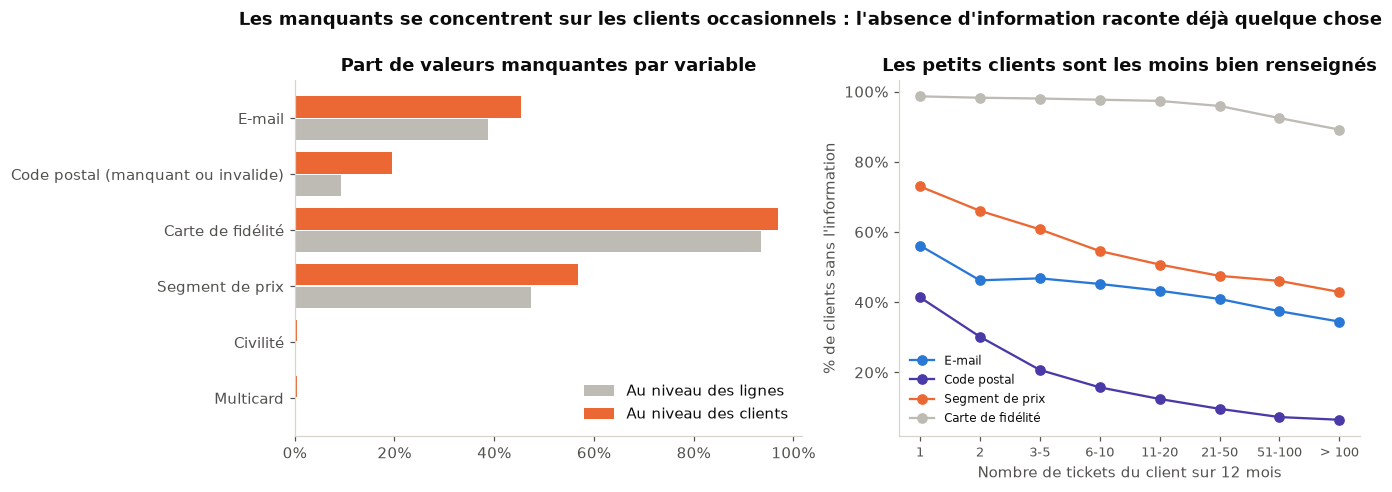

**Lecture.** Le niveau d'analyse change les chiffres : ainsi, 93,4 % des lignes mais 96,9 % des clients n'ont pas de carte. Surtout, **le manquant est lié à l'activité** :
56 % des clients à un seul ticket n'ont pas d'e-mail, contre 34 % de ceux à plus de 100 tickets. Le mécanisme n'est donc pas aléatoire (*MAR/MNAR* : l'absence dépend d'une autre variable, voire de la valeur elle-même) ; une imputation par la moyenne ou la médiane serait trompeuse.
**Règle générale retenue pour les variables catégorielles** : le manquant devient une modalité (`inconnu`), ce qui est la règle métier de la slide 86 (« imputation par règle métier ») ; pour les variables numériques créées plus tard (ancienneté de carte, délais), on remplacera par une valeur neutre assortie d'une indicatrice d'absence.

In [20]:
row_na = pd.Series({
    'E-mail': raw_tr.email_domain.isna().mean(),
    'Code postal (manquant brut)': raw_tr.zip_code.isna().mean(),
    'Code postal (manquant ou invalide)': (~raw_tr.zip_code.str.fullmatch(r'\d{4,5}', na=False)).mean(),
    'Carte de fidélité': raw_tr.card_subscription.isna().mean(),
    'Segment de prix': raw_tr.price_segmentation.isna().mean(),
    'Civilité': raw_tr.civility.isna().mean(),
    'Multicard': raw_tr.multicard.isna().mean()})
cli_na = pd.Series({
    'E-mail': 1 - D_tr.has_email.mean(),
    'Code postal (manquant brut)': att_first.zip_code.isna().mean(),
    'Code postal (manquant ou invalide)': D_tr.zip5.isna().mean(),
    'Carte de fidélité': 1 - D_tr.has_card.mean(),
    'Segment de prix': D_tr.ps_missing.mean(),
    'Civilité': D_tr.civility.eq('ND').mean(),
    'Multicard': D_tr.multicard.isna().mean()})
na_tab = pd.DataFrame({'lignes (%)': 100 * row_na, 'clients (%)': 100 * cli_na}).round(1)
na_tab['nature'] = ['non renseigné par le client', 'non renseigné', 'non renseigné ou saisie invalide', 'structurel (pas d\'adhésion)',
                    'structurel (politique magasin) + non renseigné', 'absence de fiche client', 'absence de fiche client']
display(na_tab)
act = D_tr.groupby('n_tix_cls', observed=True).agg(
    email=('has_email', lambda s: 100 * (1 - s.mean())), zipcode=('zip5', lambda s: 100 * s.isna().mean()),
    carte=('has_card', lambda s: 100 * (1 - s.mean())), segment=('ps_missing', lambda s: 100 * s.mean()))
KEY.update(na_email_1=float(act.email.iloc[0]), na_email_100=float(act.email.iloc[-1]), na_zip_1=float(act.zipcode.iloc[0]), na_zip_100=float(act.zipcode.iloc[-1]))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
labs = ['E-mail', 'Code postal (manquant ou invalide)', 'Carte de fidélité', 'Segment de prix', 'Civilité', 'Multicard']
yy = np.arange(len(labs))
ax.barh(yy + 0.2, row_na[labs] * 100, height=0.38, color=c.GREY, label='Au niveau des lignes')
ax.barh(yy - 0.2, cli_na[labs] * 100, height=0.38, color=c.ACCENT, label='Au niveau des clients')
ax.set_yticks(yy)
ax.set_yticklabels(labs)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
ax.legend(frameon=False, loc='lower right')
ax.set_title('Part de valeurs manquantes par variable')
ax = axes[1]
for col, lab, colr in [('email', 'E-mail', c.BLUE), ('zipcode', 'Code postal', c.PURPLE), ('segment', 'Segment de prix', c.ACCENT), ('carte', 'Carte de fidélité', c.GREY)]:
    ax.plot(range(len(act)), act[col], marker='o', color=colr, label=lab)
ax.set_xticks(range(len(act)))
ax.set_xticklabels(act.index, fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
ax.set_xlabel('Nombre de tickets du client sur 12 mois')
ax.set_ylabel('% de clients sans l\'information')
ax.legend(frameon=False, fontsize=8)
ax.set_title('Les petits clients sont les moins bien renseignés')
fig.suptitle('Les manquants se concentrent sur les clients occasionnels : l\'absence d\'information raconte déjà quelque chose', fontweight='bold', y=1.03)
savefig(fig, 'manquants', 'Le taux de manquants dépend du niveau (ligne vs client) et de l\'activité : les clients occasionnels sont les moins renseignés.')
md(f"""**Lecture.** Le niveau d'analyse change les chiffres : ainsi, {pc(row_na['Carte de fidélité'])} des lignes mais {pc(cli_na['Carte de fidélité'])} des clients n'ont pas de carte. Surtout, **le manquant est lié à l'activité** :
{pc(KEY['na_email_1'] / 100, 0)} des clients à un seul ticket n'ont pas d'e-mail, contre {pc(KEY['na_email_100'] / 100, 0)} de ceux à plus de 100 tickets. Le mécanisme n'est donc pas aléatoire (*MAR/MNAR* : l'absence dépend d'une autre variable, voire de la valeur elle-même) ; une imputation par la moyenne ou la médiane serait trompeuse.
**Règle générale retenue pour les variables catégorielles** : le manquant devient une modalité (`inconnu`), ce qui est la règle métier de la slide 86 (« imputation par règle métier ») ; pour les variables numériques créées plus tard (ancienneté de carte, délais), on remplacera par une valeur neutre assortie d'une indicatrice d'absence.""")
dec('Manquants', 'toutes variables client', 'Manquants tout ou rien par client, non aléatoires (liés à l\'activité et au magasin)',
    'Pas d\'imputation statistique : modalité explicite « inconnu » pour les catégorielles ; valeur neutre + indicatrice pour les numériques dérivées', 'Imputer par moyenne/médiane écraserait le signal (le manquant est lié à l\'activité) ; supprimer des lignes serait coûteux (jusqu\'à 97 % des clients)',
    f"e-mail manquant pour {pc(KEY['na_email_1'] / 100, 0)} des clients à 1 ticket contre {pc(KEY['na_email_100'] / 100, 0)} à plus de 100", 'notebook 02')

### 3.13 Cohérence région du magasin vs département du client
`stores_nb` (2 premiers chiffres) donne le département du **magasin** ; `zip_code` donne celui du **client**. Fréquenter un magasin hors de son département est soit une anomalie, soit un comportement (déplacement, résidence secondaire, vacances).

In [21]:
Dk = D_tr[D_tr.dept.isin(VALID_DEPT)]
same = Dk.dept == Dk.region
# part des tickets réalisés dans le département de résidence
tk_dept = tk_tr[['id_client', 'store_region']].merge(Dk[['dept']], left_on='id_client', right_index=True)
share_home_tk = (tk_dept.store_region == tk_dept.dept).mean()
any_home = (tk_dept.assign(h=tk_dept.store_region == tk_dept.dept).groupby('id_client').h.max()).mean()
pairs = (Dk[~same].groupby(['dept', 'region']).size().sort_values(ascending=False).head(8).rename('clients').reset_index())
pairs.columns = ['Département du client', 'Département du magasin principal', 'clients']
KEY.update(same_dept=float(same.mean()), any_home=float(any_home), share_home_tk=float(share_home_tk), multi_region=float((D_tr.n_regions > 1).mean()))
display(pairs)
md(f"""**Lecture.** Pour {pc(same.mean())} des clients dont le code postal est valide, le magasin le plus fréquenté est dans leur département ; {pc(any_home)} ont au moins un ticket dans leur département, et {pc(share_home_tk)} de leurs tickets y sont réalisés.
Les écarts les plus fréquents sont des **départements voisins** (Rhône/Isère, Ain/Rhône, Ardèche/Drôme, Val-de-Marne/Paris, Bouches-du-Rhône/Var…), pas des erreurs de saisie : {pc(KEY['multi_region'])} des clients fréquentent plus d'un département.
La cohérence est donc bonne, et l'écart « client hors de son département habituel » est un **comportement** (client occasionnel ou touriste) plutôt qu'une anomalie à corriger. On l'étudie comme variable candidate en partie 6 (les codes étrangers `ETR` sont exclus de ce test, voir 3.5) ; on garde le **département du magasin comme variable géographique principale** (jamais manquante), le département du client comme complément.""")
dec('Géographie', 'stores_nb, zip_code', f"Département du magasin ≠ département du client pour {pc(1 - same.mean(), 0)} des clients valides",
    'Ne pas corriger : écart = comportement (voisinage, déplacement) ; variable géographique principale = département du magasin ; indicateur « hors département » candidat', 'Les écarts sont structurés (départements voisins), pas aléatoires',
    f"{pc(same.mean())} de concordance ; {pc(KEY['multi_region'])} de clients multi-départements", 'notebook 02')

,Département du client,Département du magasin principal,clients
0,69,38,419
1,01,69,353
2,07,26,285
3,43,42,212
4,94,75,198
5,13,83,157
6,83,13,148
7,83,06,131


**Lecture.** Pour 89,4 % des clients dont le code postal est valide, le magasin le plus fréquenté est dans leur département ; 91,3 % ont au moins un ticket dans leur département, et 92,9 % de leurs tickets y sont réalisés.
Les écarts les plus fréquents sont des **départements voisins** (Rhône/Isère, Ain/Rhône, Ardèche/Drôme, Val-de-Marne/Paris, Bouches-du-Rhône/Var…), pas des erreurs de saisie : 11,6 % des clients fréquentent plus d'un département.
La cohérence est donc bonne, et l'écart « client hors de son département habituel » est un **comportement** (client occasionnel ou touriste) plutôt qu'une anomalie à corriger. On l'étudie comme variable candidate en partie 6 (les codes étrangers `ETR` sont exclus de ce test, voir 3.5) ; on garde le **département du magasin comme variable géographique principale** (jamais manquante), le département du client comme complément.

### 3.14 Moyens de paiement

In [22]:
pay = tk_tr[['payment_card', 'payment_cash', 'payment_cheque', 'payment_gift']]
n_modes = pay.sum(axis=1)
none_share = (n_modes == 0).mean()
none_by_month = (n_modes == 0).groupby(tk_tr.ts.dt.to_period('M')).mean()
pay_tab = pd.DataFrame({'% des tickets': (100 * pd.concat([pay.mean(), pd.Series({'payment_none': none_share})])).round(1)})
display(pay_tab.T)
KEY.update(pay_none=float(none_share), pay_none_first=float(none_by_month.iloc[0]), pay_none_max=float(none_by_month.max()), pay_multi=float((n_modes >= 2).mean()))
md(f"""**Lecture.** La carte bancaire intervient dans {pc(pay.payment_card.mean(), 0)} des tickets, les espèces dans {pc(pay.payment_cash.mean(), 0)} ; {pc(KEY['pay_multi'])} des tickets combinent plusieurs modes.
Point d'attention : **{pc(none_share)} des tickets ne portent aucun des quatre indicateurs** (aucun mode connu : paiement par un autre moyen non codé, ticket-restaurant, paiement mobile, avoir…), et cette part passe de {pc(KEY['pay_none_first'])} en août 2019 à {pc(KEY['pay_none_max'])} au plus haut de 2020 : dérive à surveiller (la nature de ce « autre » moyen de paiement a pu changer avec le confinement).
**Décision** : ne pas imputer ; les quatre indicateurs sont conservés ; on y ajoute la modalité **`aucun`** pour construire des parts de tickets par mode et un mode dominant par client (partie 6) ; la dérive dans le temps est signalée dans les limites.""")
dec('Paiement', 'payment_*', f'{pc(none_share)} des tickets sans aucun mode de paiement (part en hausse depuis mars 2020)',
    'Conserver les 4 indicateurs ; ajouter l\'état « aucun » ; construire des parts par mode et un mode dominant par client', 'Un autre moyen de paiement non codé : ce n\'est pas une erreur, mais une information incomplète dont l\'importance a varié dans le temps',
    f"{fr(int((n_modes == 0).sum()))} tickets ; {pc(KEY['pay_none_first'])} (août 2019) -> {pc(KEY['pay_none_max'])} (maximum mensuel)", 'notebook 02')

,payment_card,payment_cash,payment_cheque,payment_gift,payment_none
% des tickets,67.9,22.7,3.4,6.9,6.0


**Lecture.** La carte bancaire intervient dans 68 % des tickets, les espèces dans 23 % ; 6,8 % des tickets combinent plusieurs modes.
Point d'attention : **6,0 % des tickets ne portent aucun des quatre indicateurs** (aucun mode connu : paiement par un autre moyen non codé, ticket-restaurant, paiement mobile, avoir…), et cette part passe de 4,3 % en août 2019 à 9,2 % au plus haut de 2020 : dérive à surveiller (la nature de ce « autre » moyen de paiement a pu changer avec le confinement).
**Décision** : ne pas imputer ; les quatre indicateurs sont conservés ; on y ajoute la modalité **`aucun`** pour construire des parts de tickets par mode et un mode dominant par client (partie 6) ; la dérive dans le temps est signalée dans les limites.

### 3.15 Contrôle des règles de `common._clean` : fait-on bien ce qu'on dit ?
On rejoue, sur le train **et** le test, une batterie d'assertions qui vérifient chaque règle de nettoyage à partir des données brutes. Une assertion qui échoue arrêterait le notebook.

In [23]:
def check_clean(raw, tk, cl, name):
    # --- tickets
    assert not tk.duplicated(['id_client', 'ts']).any(), f'{name} : doublon (client, instant)'
    assert tk.n_lines.sum() == len(raw)
    for col in ['item_count', 'gross_amount', 'discount_amount', 'basket_value']:
        assert np.isclose(raw[col].sum(), tk[col].sum()), (name, col)
    assert np.allclose(tk.gross_amount - tk.discount_amount, tk.basket_value, atol=1e-6)
    assert (tk.store5.str.len() == 5).all() and (tk.store5.str[:2] == tk.store_region).all()
    assert (tk.store5.astype(int) == tk.store).all(), 'le code magasin est modifié'
    assert (tk.is_return == (tk.basket_value <= 0)).all()
    assert set(tk.price_segmentation.dropna()) <= {'Access', 'Mixte', 'Quali', 'xx'}
    assert tk[['payment_gift', 'payment_cheque', 'payment_cash', 'payment_card']].isin([0, 1]).all().all()
    # --- clients : une ligne par client brut, mêmes identifiants
    assert cl.index.is_unique and set(cl.index) == set(raw.id_client)
    assert (cl.has_email == cl.email_domain.notna()).all()
    assert (cl.email_domain.dropna() == cl.email_domain.dropna().str.upper()).all()
    assert cl.zip5.dropna().str.fullmatch(r'\d{5}').all() and (cl.zip5.dropna() != '00000').all()
    assert (cl.dept[cl.zip5.notna()] == cl.zip5.dropna().str[:2]).all() and (cl.dept.dropna().isin(['ETR']) | cl.zip5.reindex(cl.dept.dropna().index).notna()).all()
    assert not (cl.zip5 == '00000').any()
    assert cl.multicard.dropna().isin([0, 1]).all()
    assert cl.civility.isin(['M', 'MME', 'NR', 'ND']).all()
    assert (cl.anonymous == (cl.civility == 'ND')).all() and (cl.anonymous <= cl.multicard.isna()).all()
    assert (cl.has_card == cl.card_date.notna()).all()
    # --- reconstruction indépendante de zip5 et dept depuis le brut
    zr_ = raw.groupby('id_client').zip_code.first().reindex(cl.index)
    f4_, ok_ = zr_.str.fullmatch(r'\d{4}', na=False), zr_.str.fullmatch(r'\d{5}', na=False) & (zr_ != '00000')
    assert (cl.zip5[ok_] == zr_[ok_]).all() and cl.zip5[~ok_].isna().all()
    assert (cl.dept[f4_] == 'ETR').all() and cl.dept[~(f4_ | ok_)].isna().all()
    return True


check_clean(raw_tr, tk_tr, cl_tr, 'train')
check_clean(raw_te, tk_te, cl_te, 'test')
n_bad_dept = KEY['zip_bad_dept']
md(f"""**Toutes les assertions passent sur le train et le test** : un ticket par (client, instant) avec totaux conservés, code magasin à 5 chiffres et département cohérent, `is_return` ⇔ panier ≤ 0,
un client par identifiant, domaines en majuscules, `zip5` et `dept` reconstruits indépendamment depuis le brut (codes à 4 chiffres → `ETR`, « 00000 » exclu), `has_card` ⇔ date d'adhésion valide, `price_segmentation` à quatre modalités, `multicard` ∈ {{0, 1, manquant}}, `anonymous` ⇔ civilité `ND`.

**Règles corrigées dans `common._clean` à la suite de ce notebook** (le notebook décrit la version actuelle du socle) : (1) `zip5` ne garde que les codes à 5 chiffres, « 00000 » devient manquant et les {fr(z4.sum())} codes à 4 chiffres (suisses ou belges) donnent `dept = 'ETR'` ; (2) `has_card` = date d'adhésion valide ; (3) la modalité `08` de `price_segmentation` (un seul client corrompu) devient manquante.

**Points résiduels, sans conséquence ou à traiter au notebook 02** :
1. {n_bad_dept} clients ont un code à 5 chiffres dont le département n'existe pas (hors 01-95, 97, 98) : à regrouper en « inconnu ».
2. Le `.upper()` sur les domaines est sans effet (déjà en majuscules) : précaution, pas un correctif.
3. **Heure UTC** conservée (voulu, cohérent avec la coupure d'août) : pour des profils horaires lisibles, convertir en heure de Paris, à ne faire que pour la description.
4. **Code magasin des tickets mélangeant deux magasins** : le premier est gardé ({KEY['multi_diff_store']} tickets) ; arbitraire mais sans conséquence.""")

**Toutes les assertions passent sur le train et le test** : un ticket par (client, instant) avec totaux conservés, code magasin à 5 chiffres et département cohérent, `is_return` ⇔ panier ≤ 0,
un client par identifiant, domaines en majuscules, `zip5` et `dept` reconstruits indépendamment depuis le brut (codes à 4 chiffres → `ETR`, « 00000 » exclu), `has_card` ⇔ date d'adhésion valide, `price_segmentation` à quatre modalités, `multicard` ∈ {0, 1, manquant}, `anonymous` ⇔ civilité `ND`.

**Règles corrigées dans `common._clean` à la suite de ce notebook** (le notebook décrit la version actuelle du socle) : (1) `zip5` ne garde que les codes à 5 chiffres, « 00000 » devient manquant et les 554 codes à 4 chiffres (suisses ou belges) donnent `dept = 'ETR'` ; (2) `has_card` = date d'adhésion valide ; (3) la modalité `08` de `price_segmentation` (un seul client corrompu) devient manquante.

**Points résiduels, sans conséquence ou à traiter au notebook 02** :
1. 3 clients ont un code à 5 chiffres dont le département n'existe pas (hors 01-95, 97, 98) : à regrouper en « inconnu ».
2. Le `.upper()` sur les domaines est sans effet (déjà en majuscules) : précaution, pas un correctif.
3. **Heure UTC** conservée (voulu, cohérent avec la coupure d'août) : pour des profils horaires lisibles, convertir en heure de Paris, à ne faire que pour la description.
4. **Code magasin des tickets mélangeant deux magasins** : le premier est gardé (66 tickets) ; arbitraire mais sans conséquence.

## 4. Valeurs extrêmes

Slides 86-87 : repérer les valeurs extrêmes par l'**écart-type ou les percentiles**, les traiter par **plafonnement ou suppression**, et transformer par le **logarithme** les variables très asymétriques. On regarde d'abord les distributions, puis on compare les règles de détection, avant de proposer un traitement (il sera appliqué dans le notebook 02, pas ici).

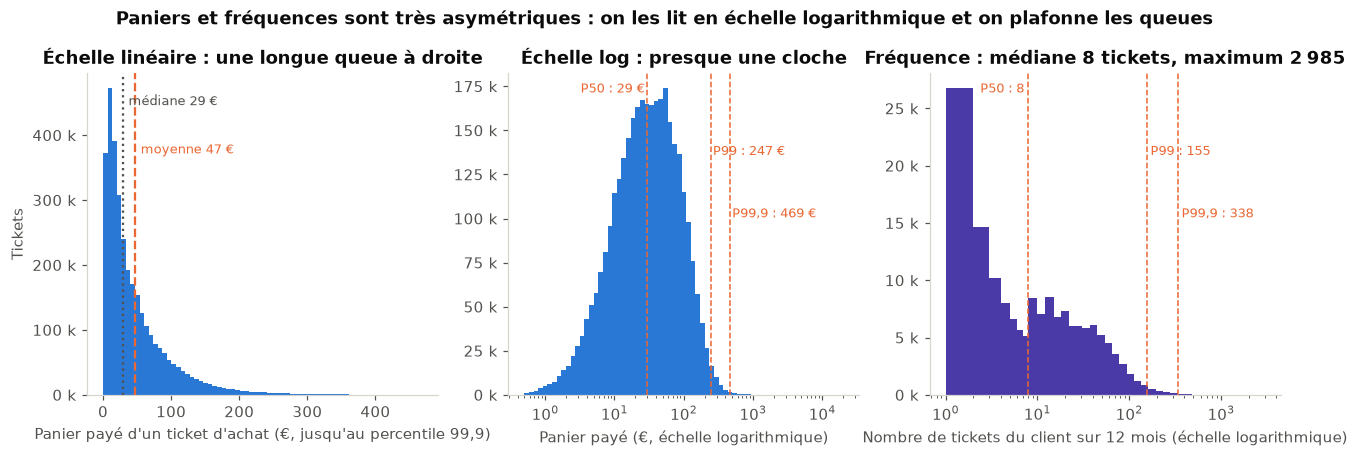

In [24]:
bk = buy.basket_value
it = buy.item_count.where(buy.item_count > 0)
nt = D_tr.n_tickets

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ax = axes[0]
ax.hist(bk[bk <= bk.quantile(0.999)], bins=70, color=c.BLUE)
ax.set_xlabel('Panier payé d\'un ticket d\'achat (€, jusqu\'au percentile 99,9)')
ax.set_ylabel('Tickets')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{fr(v / 1e3, 0)} k'))
ax.axvline(bk.mean(), color=c.ACCENT, ls='--')
ax.axvline(bk.median(), color=c.INK2, ls=':')
ax.text(bk.mean() + 8, ax.get_ylim()[1] * 0.75, f'moyenne {fr(bk.mean(), 0)} €', color=c.ACCENT, fontsize=8.5)
ax.text(bk.median() + 8, ax.get_ylim()[1] * 0.9, f'médiane {fr(bk.median(), 0)} €', color=c.INK2, fontsize=8.5)
ax.set_title('Échelle linéaire : une longue queue à droite')
ax = axes[1]
bins = np.logspace(np.log10(0.5), np.log10(bk.max()), 70)
ax.hist(bk[bk > 0], bins=bins, color=c.BLUE)
ax.set_xscale('log')
ax.set_xlabel('Panier payé (€, échelle logarithmique)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{fr(v / 1e3, 0)} k'))
for q, lab, ypos, ha in [(0.5, 'P50', 1.0, 'right'), (0.99, 'P99', 0.8, 'left'), (0.999, 'P99,9', 0.6, 'left')]:
    v = bk.quantile(q)
    ax.axvline(v, color=c.ACCENT, ls='--', lw=1)
    ax.text(v * (0.93 if ha == 'right' else 1.07), ax.get_ylim()[1] * ypos * 0.97, f'{lab} : {fr(v, 0)} €', color=c.ACCENT, fontsize=8.5, va='top', ha=ha)
ax.set_title('Échelle log : presque une cloche')
ax = axes[2]
bins = np.unique(np.floor(np.logspace(0, np.log10(nt.max() + 1), 45)))
ax.hist(nt, bins=bins, color=c.PURPLE)
ax.set_xscale('log')
ax.set_xlabel('Nombre de tickets du client sur 12 mois (échelle logarithmique)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{fr(v / 1e3, 0)} k'))
for q, lab, ypos, ha in [(0.5, 'P50', 1.0, 'right'), (0.99, 'P99', 0.8, 'left'), (0.999, 'P99,9', 0.6, 'left')]:
    v = nt.quantile(q)
    ax.axvline(v, color=c.ACCENT, ls='--', lw=1)
    ax.text(v * (0.9 if ha == 'right' else 1.1), ax.get_ylim()[1] * ypos * 0.97, f'{lab} : {fr(v, 0)}', color=c.ACCENT, fontsize=8.5, va='top', ha=ha)
ax.set_title(f'Fréquence : médiane {fr(nt.median(), 0)} tickets, maximum {fr(nt.max())}')
fig.suptitle('Paniers et fréquences sont très asymétriques : on les lit en échelle logarithmique et on plafonne les queues', fontweight='bold', y=1.03)
savefig(fig, 'distributions_extremes', 'Paniers et nombres de tickets suivent une loi très asymétrique : échelle logarithmique obligatoire, plafonnement des extrêmes nécessaire.')

In [25]:
def extreme_row(s, name, level):
    s = s.dropna()
    ls = np.log1p(s.clip(lower=0))
    q1, q3 = s.quantile([0.25, 0.75])
    lq1, lq3 = ls.quantile([0.25, 0.75])
    thr_sigma = s.mean() + 3 * s.std()
    thr_sigma_log = np.expm1(ls.mean() + 3 * ls.std())
    thr_tukey = q3 + 1.5 * (q3 - q1)
    thr_tukey_log = np.expm1(lq3 + 3 * (lq3 - lq1))
    p99, p999 = s.quantile([0.99, 0.999])
    return {'variable': name, 'niveau': level, 'médiane': s.median(), 'P99': p99, 'P99,9': p999, 'max': s.max(),
            'asymétrie': stats.skew(s), 'asymétrie après log': stats.skew(ls),
            'seuil moyenne+3σ': thr_sigma, '% au-dessus (3σ)': 100 * (s > thr_sigma).mean(),
            'seuil Tukey 1,5 IQR': thr_tukey, '% au-dessus (Tukey)': 100 * (s > thr_tukey).mean(),
            'seuil 3σ sur log': thr_sigma_log, '% au-dessus (3σ log)': 100 * (s > thr_sigma_log).mean(),
            '% au-dessus de P99,9': 100 * (s > p999).mean()}


ext = pd.DataFrame([
    extreme_row(buy.basket_value, 'Panier payé du ticket (€)', 'ticket d\'achat'),
    extreme_row(it, 'Articles par ticket', 'ticket d\'achat'),
    extreme_row(D_tr.n_tickets, 'Tickets par client (12 mois)', 'client'),
    extreme_row(D_tr.ca.dropna(), 'CA par client sur 12 mois (€)', 'client'),
    extreme_row(D_tr.basket_mean.dropna(), 'Panier moyen par client (€)', 'client')]).set_index('variable')
display(ext[['niveau', 'médiane', 'P99', 'P99,9', 'max', 'asymétrie', 'asymétrie après log']].round(2))
display(ext[['seuil moyenne+3σ', '% au-dessus (3σ)', 'seuil Tukey 1,5 IQR', '% au-dessus (Tukey)', 'seuil 3σ sur log', '% au-dessus (3σ log)', '% au-dessus de P99,9']].round(2))

,niveau,médiane,P99,"P99,9",max,asymétrie,asymétrie après log
variable,,,,,,,
Panier payé du ticket (€),ticket d'achat,29.37,246.99,468.65,20227.48,22.24,-0.20
Articles par ticket,ticket d'achat,10.00,79.00,128.00,2159.00,3.73,0.08
Tickets par client (12 mois),client,8.00,155.00,338.00,2985.00,12.85,0.34
CA par client sur 12 mois (€),client,330.32,7656.76,14724.46,95053.64,8.25,-0.37
Panier moyen par client (€),client,39.36,231.78,478.92,2926.32,6.45,-0.58


,seuil moyenne+3σ,% au-dessus (3σ),"seuil Tukey 1,5 IQR",% au-dessus (Tukey),seuil 3σ sur log,% au-dessus (3σ log),"% au-dessus de P99,9"
variable,,,,,,,
Panier payé du ticket (€),217.16,1.55,136.68,6.08,687.24,0.03,0.1
Articles par ticket,68.10,1.78,45.00,6.67,176.23,0.03,0.1
Tickets par client (12 mois),128.03,1.61,59.50,8.38,385.58,0.06,0.1
CA par client sur 12 mois (€),6298.82,1.90,2578.66,10.54,55140.02,0.01,0.1
Panier moyen par client (€),203.93,1.44,135.59,4.94,512.93,0.08,0.1


In [26]:
# les clients extrêmes en nombre de tickets sont-ils des erreurs, des professionnels ? (analyse descriptive)
thr_heavy = D_tr.n_tickets.quantile(0.999)
tpd = tk_tr.groupby(['id_client', tk_tr.ts.dt.normalize()]).size()
tpd_client = tpd.groupby('id_client').mean()
rate_cls = D_tr.groupby(pd.cut(D_tr.n_tickets, [0, 100, 200, 300, 500, 5000])).y.agg(['size', 'mean'])
big = D_tr.n_tickets >= 300
hv = pd.DataFrame({
    'Clients ≥ 300 tickets': [big.sum(), D_tr[big].n_tickets.median(), tpd_client[D_tr[big].index].mean(), D_tr[big].basket_mean.mean(), 100 * D_tr[big].has_email.mean(), 100 * D_tr[big].y.mean()],
    'Autres clients': [(~big).sum(), D_tr[~big].n_tickets.median(), tpd_client[D_tr[~big].index].mean(), D_tr[~big].basket_mean.mean(), 100 * D_tr[~big].has_email.mean(), 100 * D_tr[~big].y.mean()]},
    index=['Clients', 'Tickets sur 12 mois (médiane)', 'Tickets par jour d\'achat (moyenne)', 'Panier moyen (€)', '% avec e-mail', 'Taux de rachat (%)'])
display(hv.round(2))
max_tpd = int(tpd.max())
share_day_multi = float((tpd > 1).mean())
KEY.update(n_heavy300=int(big.sum()), heavy_rate=float(D_tr[big].y.mean()), p999_tickets=float(thr_heavy), p99_tickets=float(D_tr.n_tickets.quantile(0.99)),
           max_tickets=int(D_tr.n_tickets.max()), p999_basket=float(buy.basket_value.quantile(0.999)), p999_items=float(it.quantile(0.999)),
           max_basket=float(buy.basket_value.max()), max_tpd=max_tpd, share_day_multi=share_day_multi, plateau_rate=float(D_tr[D_tr.n_tickets > 200].y.mean()))
display(rate_cls.rename(columns={'size': 'clients', 'mean': 'taux de rachat'}).assign(**{'taux de rachat': lambda d: (100 * d['taux de rachat']).round(1)}))

,Clients ≥ 300 tickets,Autres clients
Clients,258.00,160166.00
Tickets sur 12 mois (médiane),353.00,8.00
Tickets par jour d'achat (moyenne),2.45,1.06
Panier moyen (€),27.04,52.08
% avec e-mail,77.91,54.61
Taux de rachat (%),68.99,7.63


,clients,taux de rachat
n_tickets,,
"(0, 100]",155913,6.5
"(100, 200]",3647,44.3
"(200, 300]",614,64.3
"(300, 500]",220,70.0
"(500, 5000]",30,66.7


In [27]:
# impact chiffré du plafonnement proposé (aucune modification des données : simulation)
cap_basket = buy.basket_value.quantile(0.999)
cap_items = it.quantile(0.999)
cap_nt = D_tr.n_tickets.quantile(0.999)
ca_sorted = D_tr.ca.fillna(0).sort_values(ascending=False)
top1_share = ca_sorted.iloc[:int(0.01 * len(ca_sorted))].sum() / ca_sorted.sum()
# part des clients qui ont au moins un ticket au-dessus du P99,9 de panier : sont-ils atypiques ?
big_ticket_clients = buy[buy.basket_value > cap_basket].id_client.unique()
rate_big_ticket = D_tr.loc[big_ticket_clients, 'y'].mean()
impact = pd.DataFrame({
    'Seuil proposé (P99,9)': [cap_basket, cap_items, cap_nt],
    'Valeurs plafonnées': [int((buy.basket_value > cap_basket).sum()), int((it > cap_items).sum()), int((D_tr.n_tickets > cap_nt).sum())],
    'Moyenne avant': [buy.basket_value.mean(), it.mean(), D_tr.n_tickets.mean()],
    'Moyenne après': [buy.basket_value.clip(upper=cap_basket).mean(), it.clip(upper=cap_items).mean(), D_tr.n_tickets.clip(upper=cap_nt).mean()]},
    index=['Panier du ticket (€)', 'Articles par ticket', 'Tickets par client'])
display(impact.round(2))
KEY.update(top1_ca_share=float(top1_share), rate_big_ticket=float(rate_big_ticket), n_big_ticket_clients=len(big_ticket_clients),
           cap_mean_shift=float(100 * (impact.loc['Panier du ticket (€)', 'Moyenne après'] / impact.loc['Panier du ticket (€)', 'Moyenne avant'] - 1)))
md(f"""**Lecture.**
- **Asymétrie forte** : le panier moyen ({fr(bk.mean(), 0)} €) est nettement au-dessus de la médiane ({fr(bk.median(), 0)} €) ; le maximum atteint {fr(KEY['max_basket'])} €. Le logarithme ramène l'asymétrie de {fr(ext.loc['Panier payé du ticket (€)', 'asymétrie'], 1)} à {fr(ext.loc['Panier payé du ticket (€)', 'asymétrie après log'], 1)}.
- **Comparer les règles de détection** : la règle « moyenne + 3σ » sur l'échelle brute signale {pc(ext.loc['Panier payé du ticket (€)', '% au-dessus (3σ)'] / 100, 1)} des tickets, mais c'est un artefact : sur une distribution asymétrique, la moyenne et l'écart-type sont eux-mêmes tirés par les extrêmes.
La règle de Tukey brute signale {pc(ext.loc['Panier payé du ticket (€)', '% au-dessus (Tukey)'] / 100, 1)} des tickets (trop : une queue longue n'est pas un défaut), alors que **les règles sur l'échelle logarithmique ou par percentile** ({pc(ext.loc['Panier payé du ticket (€)', '% au-dessus (3σ log)'] / 100, 2)} pour 3σ log, 0,1 % par construction pour P99,9) isolent un nombre raisonnable de cas.
- **Les clients à plusieurs centaines de tickets ne sont pas des erreurs.** {KEY['n_heavy300']} clients ont au moins 300 tickets (maximum {fr(KEY['max_tickets'])}, soit environ {fr(KEY['max_tickets'] / 365, 0)} par jour calendaire) : petits paniers ({fr(hv.loc['Panier moyen (€)', 'Clients ≥ 300 tickets'], 0)} € en moyenne), plusieurs passages par jour d'achat,
et **taux de rachat de {pc(KEY['heavy_rate'], 0)}** contre {pc(y.mean(), 1)} en moyenne. Profil compatible avec une carte utilisée par un commerce de proximité, une collectivité ou plusieurs foyers (hypothèse : on ne peut pas la vérifier). Ce sont des **vrais clients très actifs, probablement les plus faciles à prédire** : les supprimer retirerait de l'information utile.
- **Le signal sature** : le taux de rachat plafonne à environ {pc(KEY['plateau_rate'], 0)} au-delà de 200 tickets. Plafonner le nombre de tickets au P99,9 ({fr(cap_nt)} tickets, {int(impact.loc['Tickets par client', 'Valeurs plafonnées'])} clients touchés) ne détruit donc aucune information.
- Les clients dont au moins un ticket dépasse le P99,9 de panier ({fr(cap_basket)} €) sont {fr(len(big_ticket_clients))} ; leur taux de rachat est de {pc(rate_big_ticket, 1)} (environ {fr(rate_big_ticket / y.mean(), 1)} fois la moyenne, cohérent avec une clientèle plus active) : rien d'une erreur de saisie, ce sont de vrais gros achats. Le plafonnement du panier au P99,9 ne déplace la moyenne que de {fr(KEY['cap_mean_shift'], 1)} %.
- **Concentration** : le 1 % de clients au CA le plus élevé réalise {pc(KEY['top1_ca_share'], 0)} du chiffre d'affaires d'achat.""")

dec('Valeurs extrêmes', 'basket_value, item_count (ticket)', f"Queue très longue (panier max {fr(KEY['max_basket'])} €, articles max {fr(it.max())}) ; asymétrie {fr(ext.loc['Panier payé du ticket (€)', 'asymétrie'], 0)}",
    f"Ne pas supprimer ; plafonner au percentile 99,9 (panier {fr(cap_basket)} €, articles {fr(cap_items)}) avant d'agréger ; log1p pour les modèles linéaires", 'Détection par percentile (P99,9) plutôt que par moyenne+3σ (biaisée par les extrêmes) ; peu de tickets touchés, moyenne quasi inchangée',
    f"{fr(int((buy.basket_value > cap_basket).sum()))} tickets plafonnés (0,1 %) ; moyenne du panier {fr(KEY['cap_mean_shift'], 1)} %", 'notebook 02')
dec('Valeurs extrêmes', 'n_tickets, ca (client)', f"Clients à très forte fréquence (max {fr(KEY['max_tickets'])} tickets) : professionnels ? cartes partagées ?",
    f"Conserver ces clients ; plafonner les comptes au P99,9 ({fr(cap_nt)} tickets) et utiliser log1p ; envisager un indicateur « plusieurs tickets par jour »", f"Ce sont de vrais clients très actifs (rachat {pc(KEY['heavy_rate'], 0)}) ; le signal sature au-delà de 200 tickets",
    f"{int(impact.loc['Tickets par client', 'Valeurs plafonnées'])} clients plafonnés (0,1 %) ; {KEY['n_heavy300']} clients ≥ 300 tickets", 'notebook 02')
dec('Valeurs extrêmes', 'retours (montants négatifs)', 'Extrêmes négatifs (retours jusqu\'à ' + fr(-tk_tr.basket_value.min()) + ' €)', 'Traités à part (drapeau is_return, agrégés séparément), pas plafonnés', 'Un retour est un autre phénomène qu\'un achat extrême',
    f"{fr(len(ret))} tickets", 'notebook 02')

,"Seuil proposé (P99,9)",Valeurs plafonnées,Moyenne avant,Moyenne après
Panier du ticket (€),468.65,3287,47.34,47.12
Articles par ticket,128.00,3180,16.06,16.01
Tickets par client,338.00,158,20.53,20.38


**Lecture.**
- **Asymétrie forte** : le panier moyen (47 €) est nettement au-dessus de la médiane (29 €) ; le maximum atteint 20 227 €. Le logarithme ramène l'asymétrie de 22,2 à -0,2.
- **Comparer les règles de détection** : la règle « moyenne + 3σ » sur l'échelle brute signale 1,6 % des tickets, mais c'est un artefact : sur une distribution asymétrique, la moyenne et l'écart-type sont eux-mêmes tirés par les extrêmes.
La règle de Tukey brute signale 6,1 % des tickets (trop : une queue longue n'est pas un défaut), alors que **les règles sur l'échelle logarithmique ou par percentile** (0,03 % pour 3σ log, 0,1 % par construction pour P99,9) isolent un nombre raisonnable de cas.
- **Les clients à plusieurs centaines de tickets ne sont pas des erreurs.** 258 clients ont au moins 300 tickets (maximum 2 985, soit environ 8 par jour calendaire) : petits paniers (27 € en moyenne), plusieurs passages par jour d'achat,
et **taux de rachat de 69 %** contre 7,7 % en moyenne. Profil compatible avec une carte utilisée par un commerce de proximité, une collectivité ou plusieurs foyers (hypothèse : on ne peut pas la vérifier). Ce sont des **vrais clients très actifs, probablement les plus faciles à prédire** : les supprimer retirerait de l'information utile.
- **Le signal sature** : le taux de rachat plafonne à environ 66 % au-delà de 200 tickets. Plafonner le nombre de tickets au P99,9 (338 tickets, 158 clients touchés) ne détruit donc aucune information.
- Les clients dont au moins un ticket dépasse le P99,9 de panier (469 €) sont 1 512 ; leur taux de rachat est de 14,5 % (environ 1,9 fois la moyenne, cohérent avec une clientèle plus active) : rien d'une erreur de saisie, ce sont de vrais gros achats. Le plafonnement du panier au P99,9 ne déplace la moyenne que de -0,5 %.
- **Concentration** : le 1 % de clients au CA le plus élevé réalise 12 % du chiffre d'affaires d'achat.

## 5. Dynamique temporelle

*Lien avec le cours* : extraction de la date (jour, semaine, mois, week-end) (slide 85) et prise en compte de la **saisonnalité** pour fixer la fenêtre de calcul de la cible (slide 50). Les profils horaires sont lus en **heure de Paris** (UTC + 1 ou + 2 h) pour être interprétables ; le reste du projet reste en UTC.

,tickets,CA achats (M€),clients,panier moyen (€),clients actifs (% base)
month,,,,,
2019-08,323405,14.66,82934,45.4,51.7
2019-09,306633,12.84,81621,42.0,50.9
2019-10,306939,12.60,81095,41.1,50.6
2019-11,302152,13.53,80524,44.9,50.2
2019-12,329809,15.44,84368,46.9,52.6
2020-01,287106,11.85,76796,41.4,47.9
2020-02,272024,11.43,74141,42.1,46.2
2020-03,234321,12.68,67718,54.2,42.2
2020-04,190292,12.43,53273,65.4,33.2


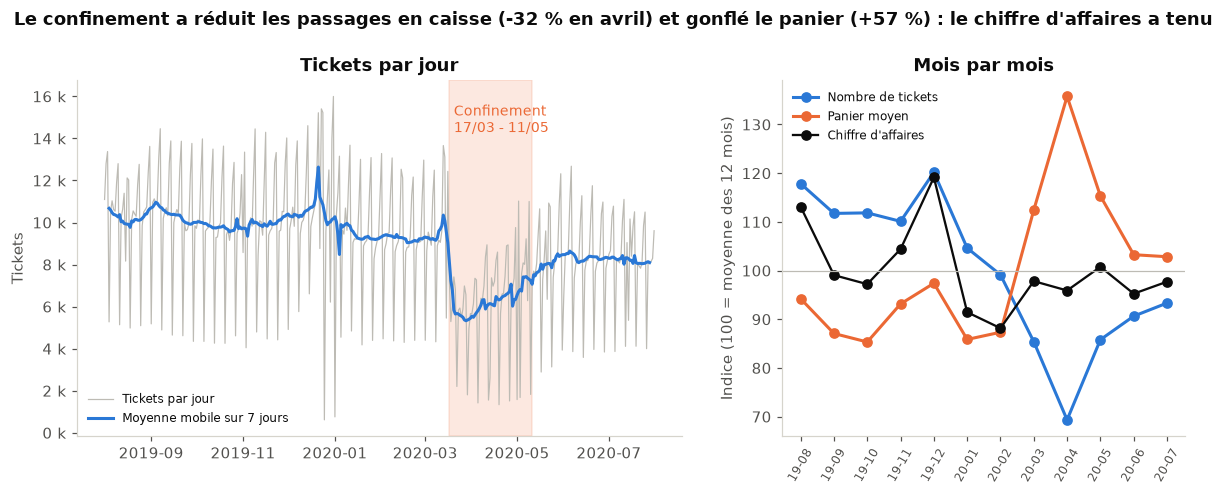

**Lecture.** Avril 2020 compte 32 % de tickets en moins que la moyenne de janvier-février, mais un panier moyen de 57 % plus élevé (courses regroupées) : le chiffre d'affaires d'achat est même 7 % au-dessus de la moyenne de janvier-février.
La part de la base active dans le mois tombe à 33 % en avril, contre 52 % en août 2019. **Conséquence** : récence, fréquence et panier calculés sur les 12 mois mélangent deux régimes de comportement ;
les comportements de mars-avril sont atypiques (l'activité retombe presque à la normale dès mai). Fenêtres glissantes récentes (30, 60, 90 jours avant le 01/08/2020) sont donc moins contaminées par le confinement que le cumul annuel, un argument de plus pour des variables par fenêtre en notebook 02.

In [28]:
day = tk_tr.groupby(tk_tr.ts.dt.normalize()).size()
mth = tk_tr.groupby('month').agg(tickets=('basket_value', 'size'), ca=('basket_value', lambda s: s[s > 0].sum()), clients=('id_client', 'nunique'))
mth['panier'] = mth.ca / tk_tr[~tk_tr.is_return].groupby('month').size()
mth['clients actifs (% base)'] = 100 * mth.clients / len(cl_tr)
ref = mth.loc[[pd.Period('2020-01'), pd.Period('2020-02')]]
conf = mth.loc[[pd.Period('2020-03'), pd.Period('2020-04')]]
KEY.update(apr_tickets_vs_janfeb=float(mth.loc[pd.Period('2020-04'), 'tickets'] / ref.tickets.mean() - 1),
           apr_basket_vs_janfeb=float(mth.loc[pd.Period('2020-04'), 'panier'] / ref.panier.mean() - 1),
           apr_ca_vs_janfeb=float(mth.loc[pd.Period('2020-04'), 'ca'] / ref.ca.mean() - 1),
           apr_active_share=float(mth.loc[pd.Period('2020-04'), 'clients actifs (% base)']), aug19_active_share=float(mth.loc[pd.Period('2019-08'), 'clients actifs (% base)']))
idx = (mth[['tickets', 'ca', 'panier']] / mth[['tickets', 'ca', 'panier']].mean() * 100)
out = mth.copy()
out.index = out.index.astype(str)
display(out.assign(tickets=out.tickets.astype(int), ca=(out.ca / 1e6).round(2), panier=out.panier.round(1), **{'clients actifs (% base)': out['clients actifs (% base)'].round(1)}).rename(columns={'ca': 'CA achats (M€)', 'panier': 'panier moyen (€)'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]
ax.plot(day.index, day.values, color=c.GREY, lw=0.8, label='Tickets par jour')
ax.plot(day.index, day.rolling(7, center=True).mean(), color=c.BLUE, lw=2, label='Moyenne mobile sur 7 jours')
ax.axvspan(pd.Timestamp('2020-03-17'), pd.Timestamp('2020-05-11'), color=c.ACCENT, alpha=0.15)
ax.text(pd.Timestamp('2020-03-20'), day.max() * 0.98, 'Confinement\n17/03 - 11/05', color=c.ACCENT, fontsize=9, va='top')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{fr(v / 1e3, 0)} k'))
ax.set_ylabel('Tickets')
ax.legend(frameon=False, loc='lower left', fontsize=8)
ax.set_title('Tickets par jour')
ax = axes[1]
x = [str(p)[2:] for p in idx.index]
for col, lab, colr in [('tickets', 'Nombre de tickets', c.BLUE), ('panier', 'Panier moyen', c.ACCENT), ('ca', 'Chiffre d\'affaires', c.INK)]:
    ax.plot(range(len(idx)), idx[col], marker='o', color=colr, label=lab, lw=2 if col != 'ca' else 1.5)
ax.axhline(100, color=c.GREY, lw=0.8)
ax.set_xticks(range(len(idx)))
ax.set_xticklabels(x, rotation=60, fontsize=8)
ax.set_ylabel('Indice (100 = moyenne des 12 mois)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('Mois par mois')
fig.suptitle(f'Le confinement a réduit les passages en caisse ({fr(100 * KEY["apr_tickets_vs_janfeb"], 0)} % en avril) et gonflé le panier (+{fr(100 * KEY["apr_basket_vs_janfeb"], 0)} %) : le chiffre d\'affaires a tenu', fontweight='bold', y=1.03)
savefig(fig, 'dynamique_mensuelle', f'Le confinement réduit le nombre de tickets ({fr(100 * KEY["apr_tickets_vs_janfeb"], 0)} % en avril vs janvier-février) mais gonfle le panier (+{fr(100 * KEY["apr_basket_vs_janfeb"], 0)} %) : le CA tient.')
md(f"""**Lecture.** Avril 2020 compte {pc(-KEY['apr_tickets_vs_janfeb'], 0)} de tickets en moins que la moyenne de janvier-février, mais un panier moyen de {pc(KEY['apr_basket_vs_janfeb'], 0)} plus élevé (courses regroupées) : le chiffre d'affaires d'achat est même {pc(KEY['apr_ca_vs_janfeb'], 0)} au-dessus de la moyenne de janvier-février.
La part de la base active dans le mois tombe à {pc(KEY['apr_active_share'] / 100, 0)} en avril, contre {pc(KEY['aug19_active_share'] / 100, 0)} en août 2019. **Conséquence** : récence, fréquence et panier calculés sur les 12 mois mélangent deux régimes de comportement ;
les comportements de mars-avril sont atypiques (l'activité retombe presque à la normale dès mai). Fenêtres glissantes récentes (30, 60, 90 jours avant le 01/08/2020) sont donc moins contaminées par le confinement que le cumul annuel, un argument de plus pour des variables par fenêtre en notebook 02.""")

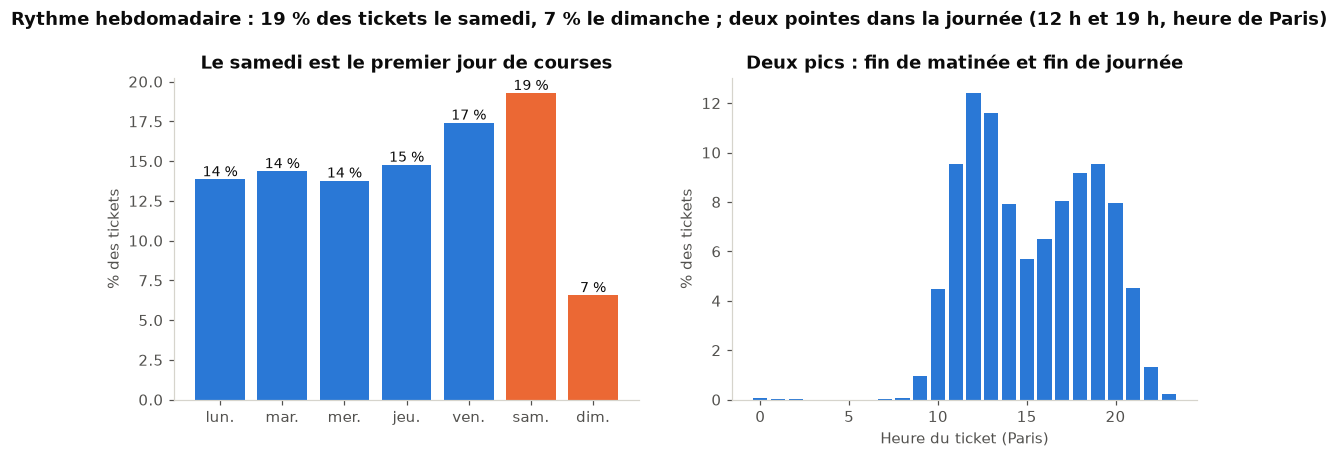

In [29]:
loc = tk_tr.ts.dt.tz_localize('UTC').dt.tz_convert('Europe/Paris')
dow_names = ['lun.', 'mar.', 'mer.', 'jeu.', 'ven.', 'sam.', 'dim.']
dow = loc.dt.day_of_week.value_counts().sort_index()
hour = loc.dt.hour.value_counts().sort_index()
pk_am, pk_pm = int(hour[hour.index < 15].idxmax()), int(hour[hour.index >= 15].idxmax())
KEY.update(sat_share=float(dow.loc[5] / dow.sum()), sun_share=float(dow.loc[6] / dow.sum()), pk_am=pk_am, pk_pm=pk_pm)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.bar(dow_names, 100 * dow.values / dow.sum(), color=[c.BLUE] * 5 + [c.ACCENT, c.ACCENT])
for i, v in enumerate(100 * dow.values / dow.sum()):
    ax.text(i, v + 0.2, f'{fr(v, 0)} %', ha='center', fontsize=9)
ax.set_ylabel('% des tickets')
ax.set_title('Le samedi est le premier jour de courses')
ax = axes[1]
ax.bar(hour.index, 100 * hour.values / hour.sum(), color=c.BLUE)
ax.set_xlabel('Heure du ticket (Paris)')
ax.set_ylabel('% des tickets')
ax.set_title('Deux pics : fin de matinée et fin de journée')
fig.suptitle(f'Rythme hebdomadaire : {fr(100 * KEY["sat_share"], 0)} % des tickets le samedi, {fr(100 * KEY["sun_share"], 0)} % le dimanche ; deux pointes dans la journée ({pk_am} h et {pk_pm} h, heure de Paris)', fontweight='bold', y=1.04)
savefig(fig, 'rythmes_semaine_heure', 'Le samedi concentre le plus de tickets ; la journée a deux pointes (fin de matinée, fin d\'après-midi), le dimanche est marginal.')

In [30]:
# saisonnalité d'août : un seul mois d'août observé (août 2019)
aug = mth.loc[pd.Period('2019-08')]
rank_ca = int(mth.ca.rank(ascending=False).loc[pd.Period('2019-08')])
rank_tk = int(mth.tickets.rank(ascending=False).loc[pd.Period('2019-08')])
aug_idx_ca = float(aug.ca / mth.ca.mean())
aug_idx_tk = float(aug.tickets / mth.tickets.mean())
rm = tk_tr.groupby(['store_region', 'month']).size().unstack(fill_value=0)
rm = rm[rm.sum(axis=1) >= 30000]
aug_reg = (rm[pd.Period('2019-08')] / rm.drop(columns=pd.Period('2019-08')).mean(axis=1)).sort_values(ascending=False)
KEY.update(aug_rank_tickets=rank_tk, aug_rank_ca=rank_ca, aug_idx_ca=aug_idx_ca, aug_idx_tickets=aug_idx_tk)
t = pd.concat([aug_reg.head(5), aug_reg.tail(3)]).round(2).rename('août 2019 / moyenne des autres mois').to_frame()
t.index.name = 'département du magasin'
display(t)
md(f"""**Août : pas un mois creux dans les données, plutôt l'un des plus actifs.** Août 2019, le seul mois d'août observé, est le **{rank_tk}{'er' if rank_tk == 1 else 'e'} mois en nombre de tickets** et le **{rank_ca}{'er' if rank_ca == 1 else 'e'} en chiffre d'affaires** (indice CA {fr(aug_idx_ca, 2)} par rapport à la moyenne des 12 mois), contrairement à l'hypothèse d'un mois d'été calme :
la clientèle de vacances des départements littoraux le porte (ci-dessus, magasins les plus « estivaux » ; les départements de la région parisienne, eux, se vident).
**Limite de la saisonnalité** : on ne voit qu'**un seul août** et qu'**un seul mois cible** ; un modèle ne peut pas apprendre un effet « mois » (il n'y a aucune variation de mois dans la cible), et les clients qui n'ont acheté qu'en août 2019 (touristes) ne sont pas des habitués.
**Décision** : aucune variable de mois ni de saison ; en revanche, la **part de l'activité réalisée en août 2019** et le **département du magasin** (zones touristiques) sont candidats pour distinguer résidents et vacanciers.""")
dec('Saisonnalité', 'transaction_date', 'Un seul mois cible, un seul août observé ; creux de mars-avril 2020 (confinement)',
    'Aucune variable de mois/saison ; variables par fenêtres récentes (30/60/90 j) pour limiter l\'effet confinement ; jour/heure comme profils d\'habitude', 'La cible n\'a pas de variation de mois : un effet saisonnier ne s\'apprend pas ; les fenêtres récentes sont moins contaminées',
    f"avril 2020 : {pc(KEY['apr_tickets_vs_janfeb'], 0)} de tickets, panier {pc(KEY['apr_basket_vs_janfeb'], 0)} ; août 2019 : {rank_ca}e mois en CA", 'notebook 02')

,août 2019 / moyenne des autres mois
département du magasin,
56,1.47
06,1.35
83,1.34
11,1.32
34,1.32
77,0.95
75,0.92
92,0.91


**Août : pas un mois creux dans les données, plutôt l'un des plus actifs.** Août 2019, le seul mois d'août observé, est le **2e mois en nombre de tickets** et le **2e en chiffre d'affaires** (indice CA 1,13 par rapport à la moyenne des 12 mois), contrairement à l'hypothèse d'un mois d'été calme :
la clientèle de vacances des départements littoraux le porte (ci-dessus, magasins les plus « estivaux » ; les départements de la région parisienne, eux, se vident).
**Limite de la saisonnalité** : on ne voit qu'**un seul août** et qu'**un seul mois cible** ; un modèle ne peut pas apprendre un effet « mois » (il n'y a aucune variation de mois dans la cible), et les clients qui n'ont acheté qu'en août 2019 (touristes) ne sont pas des habitués.
**Décision** : aucune variable de mois ni de saison ; en revanche, la **part de l'activité réalisée en août 2019** et le **département du magasin** (zones touristiques) sont candidats pour distinguer résidents et vacanciers.

## 6. Le rachat selon les variables brutes

On croise le taux de rachat (train) avec les variables disponibles, **discrétisées en classes** (slide 87) pour lire des effectifs : chaque barre affiche le taux et le nombre de clients, la ligne pointillée est le taux global. Les classes de récence et de fréquence sont des seuils métier ; le panier moyen est découpé en quintiles. Ce sont des descriptions pour **comprendre**, pas des variables encore transformées pour le modèle.

In [31]:
BASE = float(y.mean())
# discrétisation des variables continues
D_tr['rec_cls'] = pd.cut(D_tr.recency, [-1, 7, 14, 30, 60, 90, 180, np.inf], labels=['≤ 7 j', '8-14 j', '15-30 j', '31-60 j', '61-90 j', '91-180 j', '> 180 j'])
bq = D_tr.basket_mean.quantile(np.linspace(0, 1, 6)).values
bsk_labels = [f'< {fr(bq[1], 0)} €'] + [f'{fr(bq[i], 0)}-{fr(bq[i + 1], 0)} €' for i in range(1, 4)] + [f'> {fr(bq[4], 0)} €']
D_tr['bsk_cls'] = pd.cut(D_tr.basket_mean, bins=[-np.inf, *bq[1:5], np.inf], labels=bsk_labels)
D_tr['mc_cls'] = D_tr.multicard.map({0.0: 'multicard = 0', 1.0: 'multicard = 1'}).fillna('inconnu')
D_tr['email_cls'] = np.where(D_tr.has_email, 'e-mail renseigné', 'pas d\'e-mail')
D_tr['card_cls'] = np.where(D_tr.has_card, 'carte de fidélité', 'pas de carte')
D_tr['ps_cls'] = D_tr.price_seg.fillna('Manquant')
PAYLAB = {'card': 'carte bancaire', 'cash': 'espèces', 'cheque': 'chèque', 'gift': 'cadeau / avoir', 'none': 'aucun mode connu'}
D_tr['pay_cls'] = D_tr.pay_dom.map(PAYLAB)
D_tr['away_cls'] = np.select([D_tr.dept == 'ETR', D_tr.dept.isin(VALID_DEPT) & (D_tr.dept == D_tr.region), D_tr.dept.isin(VALID_DEPT)],
                             ['code postal étranger', 'achète dans son département', 'achète hors de son département'], 'département client inconnu')
FAM = {'GMAIL.COM': 'Gmail', 'HOTMAIL.FR': 'Microsoft', 'HOTMAIL.COM': 'Microsoft', 'LIVE.FR': 'Microsoft', 'OUTLOOK.FR': 'Microsoft', 'OUTLOOK.COM': 'Microsoft', 'MSN.COM': 'Microsoft',
       'YAHOO.FR': 'Yahoo', 'YAHOO.COM': 'Yahoo', 'ORANGE.FR': 'FAI français', 'WANADOO.FR': 'FAI français', 'FREE.FR': 'FAI français', 'SFR.FR': 'FAI français', 'NEUF.FR': 'FAI français',
       'LAPOSTE.NET': 'FAI français', 'BBOX.FR': 'FAI français', 'CLUB-INTERNET.FR': 'FAI français', 'ALICEADSL.FR': 'FAI français', 'NUMERICABLE.FR': 'FAI français', 'CEGETEL.NET': 'FAI français',
       'VOILA.FR': 'FAI français', 'AOL.COM': 'AOL', 'ICLOUD.COM': 'iCloud'}
D_tr['fam_cls'] = np.where(D_tr.has_email, D_tr.email_domain.map(FAM).fillna('autre domaine'), 'pas d\'e-mail')
D_tr['dom_cls'] = np.where(D_tr.has_email, np.where(D_tr.email_domain.map(D_tr.email_domain.value_counts()) >= 1000, D_tr.email_domain, 'AUTRE (< 1 000 clients)'), 'pas d\'e-mail')


def rate_table(col, order=None):
    g = D_tr.groupby(col, observed=True).y.agg(clients='size', rachats='sum')
    g['taux'] = g.rachats / g.clients
    ci = [wilson(k, n) for k, n in zip(g.rachats, g.clients)]
    g['ic_bas'], g['ic_haut'] = [a for a, b in ci], [b for a, b in ci]
    g['part_clients'] = g.clients / g.clients.sum()
    g['lift'] = g.taux / BASE
    if order is not None:
        g = g.reindex(order)
    g.index.name = 'classe'
    return g


def barh_rate(ax, tab, title, fontsize=8.5, highlight=None):
    t = tab.iloc[::-1]
    cols = [c.ACCENT if v > BASE else c.GREY for v in t.taux]
    ax.barh(range(len(t)), 100 * t.taux, color=cols, height=0.7)
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels([str(i) for i in t.index], fontsize=fontsize)
    xmax = 100 * t.taux.max()
    for i, (v, n) in enumerate(zip(t.taux, t.clients)):
        ax.text(100 * v + xmax * 0.015, i, f'{fr(100 * v, 1)} %  (n = {fr(n)})', va='center', fontsize=fontsize - 0.5)
    ax.axvline(100 * BASE, color=c.INK2, ls=':', lw=1)
    ax.set_xlim(0, xmax * 1.55)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
    ax.set_title(title, fontsize=10.5)


RT = {}
RT['recence'] = rate_table('rec_cls')
RT['nb_tickets'] = rate_table('n_tix_cls')
RT['panier_moyen'] = rate_table('bsk_cls')
RT['civilite'] = rate_table('civility', ['M', 'MME', 'NR', 'ND'])
RT['email'] = rate_table('email_cls')
RT['carte'] = rate_table('card_cls')
RT['multicard'] = rate_table('mc_cls', ['multicard = 0', 'multicard = 1', 'inconnu'])
RT['paiement_dominant'] = rate_table('pay_cls')
RT['segment_prix'] = rate_table('ps_cls', ['Access', 'Mixte', 'Quali', 'xx', 'Manquant'])
RT['famille_email'] = rate_table('fam_cls')
RT['domaine_email'] = rate_table('dom_cls')
RT['hors_departement'] = rate_table('away_cls')
display(RT['recence'][['clients', 'part_clients', 'taux', 'lift']].round(4))
display(RT['nb_tickets'][['clients', 'part_clients', 'taux', 'lift']].round(4))

,clients,part_clients,taux,lift
classe,,,,
≤ 7 j,37811,0.2357,0.2245,2.9068
8-14 j,13714,0.0855,0.1089,1.4094
15-30 j,18256,0.1138,0.0655,0.8481
31-60 j,18536,0.1155,0.0343,0.4442
61-90 j,9993,0.0623,0.0195,0.2526
91-180 j,21580,0.1345,0.0089,0.1158
> 180 j,40534,0.2527,0.0047,0.0604


,clients,part_clients,taux,lift
classe,,,,
1,26752,0.1668,0.0054,0.0702
2,14657,0.0914,0.0096,0.1237
3-5,24835,0.1548,0.0176,0.2273
6-10,22868,0.1425,0.0344,0.4455
11-20,24371,0.1519,0.0615,0.7957
21-50,29228,0.1822,0.1283,1.6605
51-100,13202,0.0823,0.2614,3.3840
> 100,4511,0.0281,0.4846,6.2734


In [32]:
# les repères du brief, recalculés
r = RT['recence']['taux']
nt_r = RT['nb_tickets']['taux']
top = c.topk_metrics(D_tr.y.values, -D_tr.recency.fillna(D_tr.recency.max()).values)
KEY.update(rec_le7=float(r.iloc[0]), rec_gt180=float(r.iloc[-1]), rec_8_14=float(r.iloc[1]), rec_15_30=float(r.iloc[2]), rec_31_60=float(r.iloc[3]),
           nt_1=float(nt_r.iloc[0]), nt_gt50=float(nt_r.iloc[-2:].mean()), nt_gt100=float(nt_r.iloc[-1]),
           top10_recency_precision=float(top['precision']), top10_recency_recall=float(top['recall']), top10_recency_lift=float(top['lift']))
brief = pd.DataFrame({'Brief': [22.5, 10.9, 6.6, 3.4, 0.5], 'Mesuré ici (récence, hors retours)': [100 * KEY['rec_le7'], 100 * KEY['rec_8_14'], 100 * KEY['rec_15_30'], 100 * KEY['rec_31_60'], 100 * KEY['rec_gt180']]},
                     index=['≤ 7 jours', '8-14 jours', '15-30 jours', '31-60 jours', '> 180 jours']).round(1)
display(brief)
KEY['brief_gap'] = float((brief.iloc[:, 0] - brief.iloc[:, 1]).abs().max())
rec_ceil = np.ceil((c.REF_DATE - D_tr['last']).dt.total_seconds() / 86400)
rate_ceil = D_tr.y[rec_ceil <= 7].mean()
md(f"""Recalculées de zéro, les valeurs du brief sont **confirmées** à la décimale près avec la convention des **jours révolus** ({fr(KEY['brief_gap'], 1)} point d'écart maximal). Avec la convention « jours commencés » (un achat d'hier = 1 jour), la première classe vaudrait {pc(rate_ceil, 1)} : la définition compte, et on garde les jours révolus partout dans le projet. Cibler les 10 % de clients les plus récents (la règle de référence que le modèle doit battre) donne une précision de {pc(top['precision'], 1)} et un rappel de {pc(top['recall'], 1)} (lift {fr(top['lift'], 1)}).""")

,Brief,"Mesuré ici (récence, hors retours)"
≤ 7 jours,22.5,22.5
8-14 jours,10.9,10.9
15-30 jours,6.6,6.6
31-60 jours,3.4,3.4
> 180 jours,0.5,0.5


Recalculées de zéro, les valeurs du brief sont **confirmées** à la décimale près avec la convention des **jours révolus** (0,0 point d'écart maximal). Avec la convention « jours commencés » (un achat d'hier = 1 jour), la première classe vaudrait 23,0 % : la définition compte, et on garde les jours révolus partout dans le projet. Cibler les 10 % de clients les plus récents (la règle de référence que le modèle doit battre) donne une précision de 23,5 % et un rappel de 30,4 % (lift 3,0).

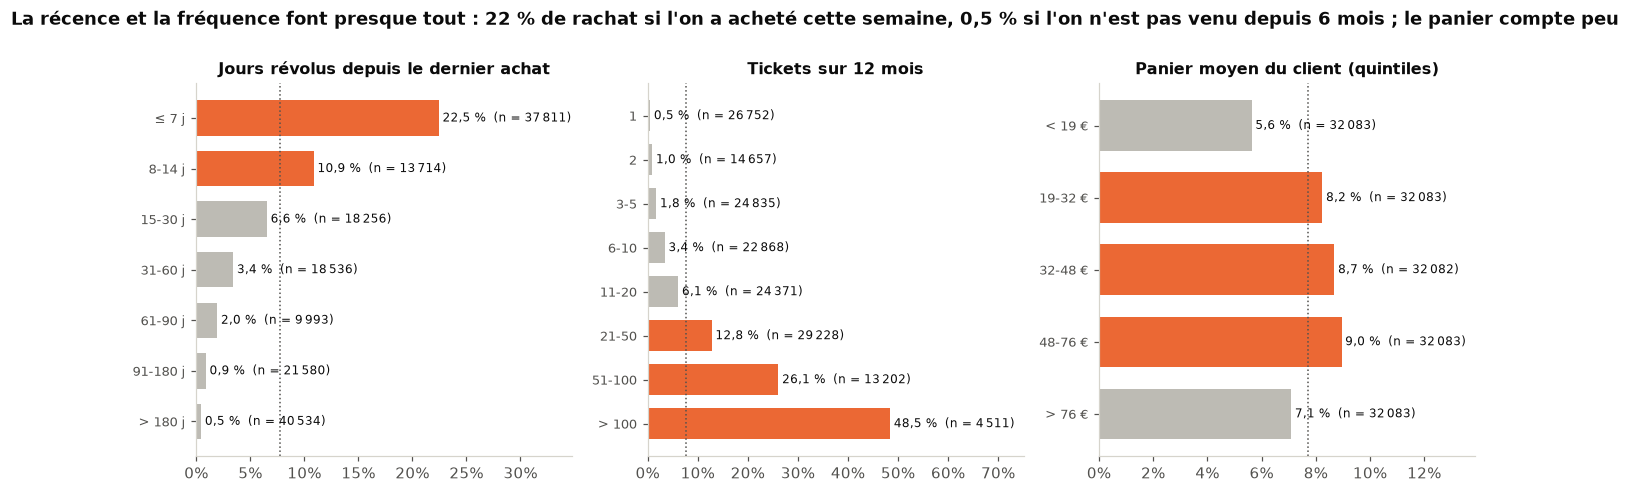

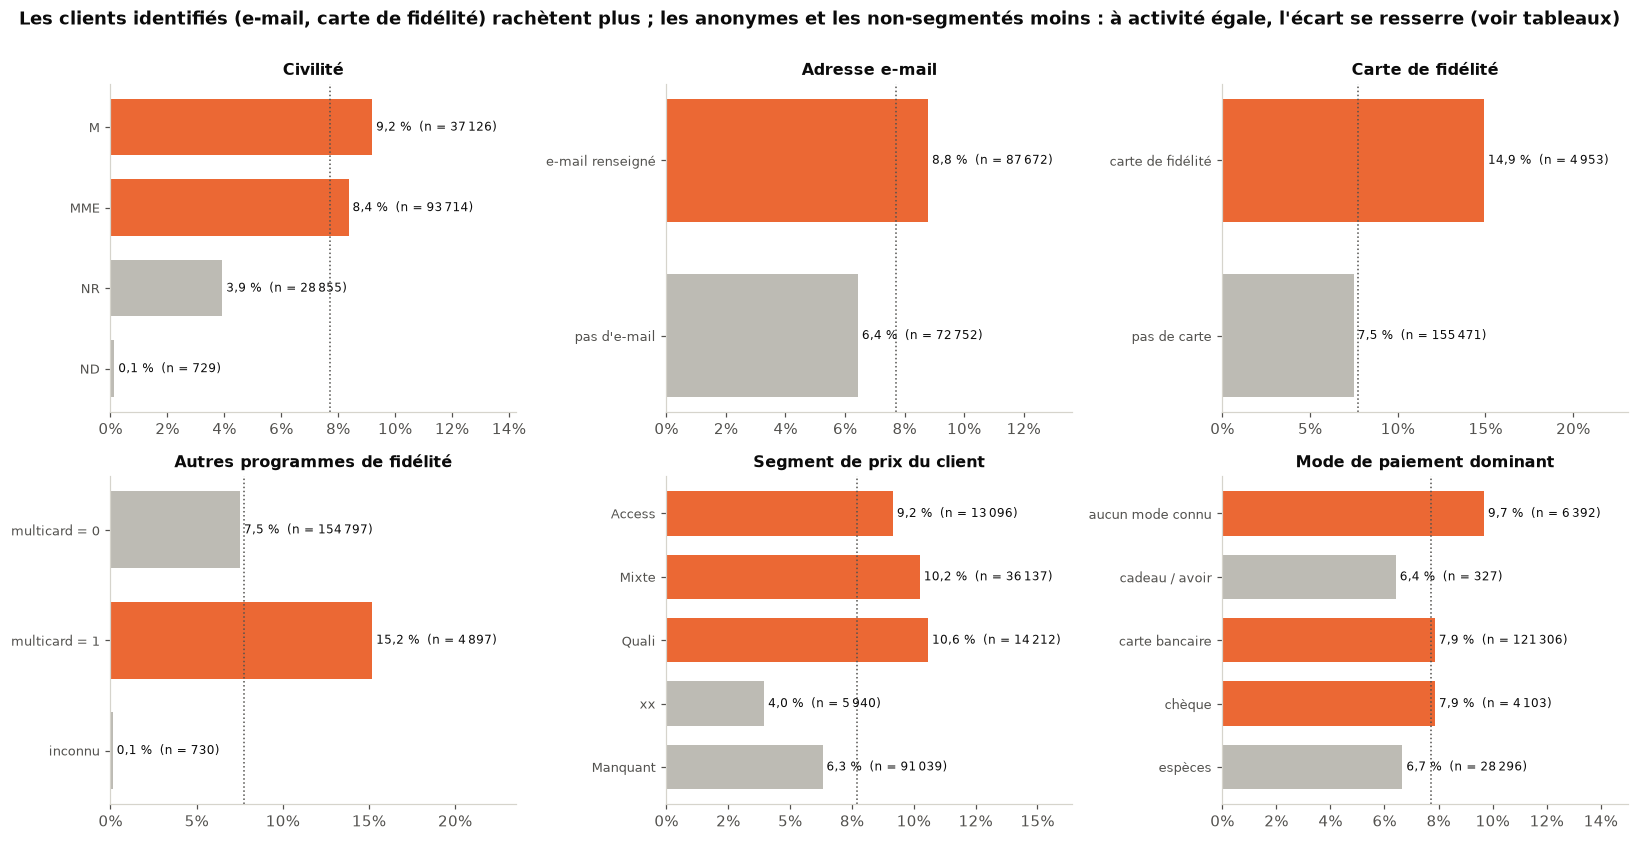

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
barh_rate(axes[0], RT['recence'], 'Jours révolus depuis le dernier achat')
barh_rate(axes[1], RT['nb_tickets'], 'Tickets sur 12 mois')
barh_rate(axes[2], RT['panier_moyen'], 'Panier moyen du client (quintiles)')
fig.suptitle(f'La récence et la fréquence font presque tout : {fr(100 * KEY["rec_le7"], 0)} % de rachat si l\'on a acheté cette semaine, {fr(100 * KEY["rec_gt180"], 1)} % si l\'on n\'est pas venu depuis 6 mois ; le panier compte peu', fontweight='bold', y=1.03)
savefig(fig, 'rachat_recence_frequence_panier', f'Un client qui a acheté dans la semaine rachète {fr(KEY["rec_le7"] / KEY["rec_gt180"], 0)} fois plus souvent que celui qui n\'est pas venu depuis six mois ; la fréquence discrimine aussi, le panier peu.')

fig, axes = plt.subplots(2, 3, figsize=(15, 7.6))
for ax, (k, t) in zip(axes.ravel(), [('civilite', 'Civilité'), ('email', 'Adresse e-mail'), ('carte', 'Carte de fidélité'),
                                       ('multicard', 'Autres programmes de fidélité'), ('segment_prix', 'Segment de prix du client'), ('paiement_dominant', 'Mode de paiement dominant')]):
    barh_rate(ax, RT[k], t)
fig.suptitle('Les clients identifiés (e-mail, carte de fidélité) rachètent plus ; les anonymes et les non-segmentés moins : à activité égale, l\'écart se resserre (voir tableaux)', fontweight='bold', y=1.0)
fig.tight_layout()
savefig(fig, 'rachat_profil_client', f'Avec e-mail ou carte de fidélité, le rachat est {fr(RT["email"].taux.iloc[0] / RT["email"].taux.iloc[1], 1)} fois (e-mail) et {fr(RT["carte"].taux.iloc[0] / RT["carte"].taux.iloc[1], 1)} fois (carte) plus élevé ; les anonymes ne rachètent presque jamais.')

In [34]:
# est-ce l'e-mail (ou la carte) qui compte, ou la fréquence ? comparaison à nombre de tickets égal
def stratified(flag, labels):
    t = D_tr.groupby(['n_tix_cls', flag], observed=True).y.agg(['size', 'mean']).unstack()
    out = pd.DataFrame({f'{labels[0]} : rachat (%)': 100 * t[('mean', labels[0])], f'{labels[1]} : rachat (%)': 100 * t[('mean', labels[1])],
                        f'{labels[0]} : clients': t[('size', labels[0])], f'{labels[1]} : clients': t[('size', labels[1])]})
    return out


s_email = stratified('email_cls', ['e-mail renseigné', 'pas d\'e-mail'])
s_card = stratified('card_cls', ['carte de fidélité', 'pas de carte'])
display(s_email.round(1))
gap_email_adj = (s_email.iloc[:, 0] - s_email.iloc[:, 1])
w = s_email.iloc[:, 2] + s_email.iloc[:, 3]
KEY.update(email_rate=float(RT['email'].loc['e-mail renseigné', 'taux']), noemail_rate=float(RT['email'].loc['pas d\'e-mail', 'taux']),
           card_rate=float(RT['carte'].loc['carte de fidélité', 'taux']), nocard_rate=float(RT['carte'].loc['pas de carte', 'taux']),
           gap_email_adj=float((gap_email_adj * w).sum() / w.sum()))
display(s_card.round(1))
md(f"""**À activité égale, l'écart se resserre fortement.** Brut : {pc(KEY['email_rate'])} de rachat avec e-mail contre {pc(KEY['noemail_rate'])} sans ; carte de fidélité : {pc(KEY['card_rate'])} contre {pc(KEY['nocard_rate'])}.
Une fois comparés **à nombre de tickets égal** (tableaux ci-dessus), l'avantage de l'e-mail tombe à environ {fr(KEY['gap_email_adj'], 1)} point en moyenne pondérée : une grande partie du contraste brut vient de ce que les clients identifiés sont aussi les plus fréquents.
Message pour le marketing : **identifier le client (e-mail, carte) est surtout le marqueur d'un client déjà engagé**, pas un levier causal ; mais l'e-mail est de toute façon la condition pour pouvoir le toucher.""")

,e-mail renseigné : rachat (%),pas d'e-mail : rachat (%),e-mail renseigné : clients,pas d'e-mail : clients
n_tix_cls,,,,
1,0.7,0.4,11733,15019
2,0.9,1.0,7881,6776
3-5,2.0,1.5,13214,11621
6-10,3.8,3.0,12532,10336
11-20,6.3,5.9,13825,10546
21-50,13.4,12.0,17270,11958
51-100,26.7,25.2,8261,4941
> 100,48.3,48.8,2956,1555


,carte de fidélité : rachat (%),pas de carte : rachat (%),carte de fidélité : clients,pas de carte : clients
n_tix_cls,,,,
1,0.8,0.5,361,26391
2,0.4,1.0,255,14402
3-5,1.6,1.8,488,24347
6-10,2.5,3.5,527,22341
11-20,5.1,6.2,643,23728
21-50,13.2,12.8,1195,28033
51-100,28.3,26.0,996,12206
> 100,49.4,48.3,488,4023


**À activité égale, l'écart se resserre fortement.** Brut : 8,8 % de rachat avec e-mail contre 6,4 % sans ; carte de fidélité : 14,9 % contre 7,5 %.
Une fois comparés **à nombre de tickets égal** (tableaux ci-dessus), l'avantage de l'e-mail tombe à environ 0,6 point en moyenne pondérée : une grande partie du contraste brut vient de ce que les clients identifiés sont aussi les plus fréquents.
Message pour le marketing : **identifier le client (e-mail, carte) est surtout le marqueur d'un client déjà engagé**, pas un levier causal ; mais l'e-mail est de toute façon la condition pour pouvoir le toucher.

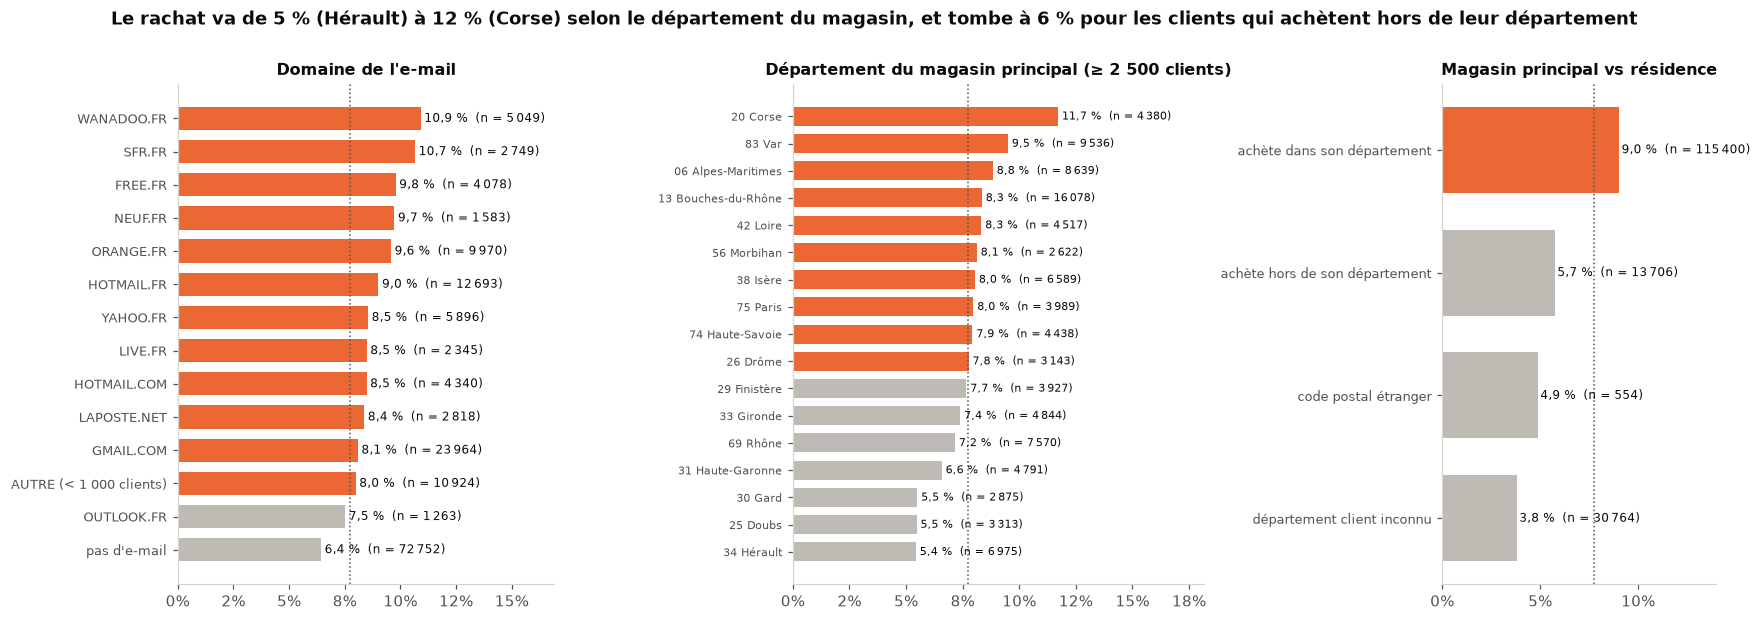

,clients,part_clients,taux,lift
classe,,,,
achète dans son département,115400,0.7193,0.0902,1.1678
achète hors de son département,13706,0.0854,0.0574,0.7433
code postal étranger,554,0.0035,0.0487,0.6309
département client inconnu,30764,0.1918,0.0380,0.4915


,clients,part_clients,taux,lift
classe,,,,
FAI français,28453,0.1774,0.0989,1.2803
AOL,860,0.0054,0.0907,1.1742
Microsoft,21331,0.1330,0.0875,1.1331
iCloud,570,0.0036,0.0842,1.0902
Yahoo,6735,0.0420,0.0831,1.0764
Gmail,23964,0.1494,0.0809,1.0469
autre domaine,5759,0.0359,0.0702,0.9082
pas d'e-mail,72752,0.4535,0.0644,0.8333


In [35]:
# domaines, départements, résidents vs hors département
reg_t = rate_table('region')
reg_t = reg_t[reg_t.clients >= 2500].sort_values('taux', ascending=False)
NAMES = {'13': 'Bouches-du-Rhône', '83': 'Var', '06': 'Alpes-Maritimes', '69': 'Rhône', '38': 'Isère', '34': 'Hérault', '33': 'Gironde', '31': 'Haute-Garonne', '74': 'Haute-Savoie',
         '42': 'Loire', '29': 'Finistère', '26': 'Drôme', '25': 'Doubs', '20': 'Corse', '75': 'Paris', '30': 'Gard', '44': 'Loire-Atlantique', '56': 'Morbihan', '73': 'Savoie', '63': 'Puy-de-Dôme',
         '11': 'Aude', '66': 'Pyrénées-Orientales', '84': 'Vaucluse', '78': 'Yvelines', '94': 'Val-de-Marne', '92': 'Hauts-de-Seine', '93': 'Seine-Saint-Denis', '77': 'Seine-et-Marne', '95': 'Val-d\'Oise',
         '49': 'Maine-et-Loire', '35': 'Ille-et-Vilaine', '21': 'Côte-d\'Or', '22': 'Côtes-d\'Armor', '01': 'Ain', '47': 'Lot-et-Garonne', '71': 'Saône-et-Loire', '12': 'Aveyron', '81': 'Tarn', '37': 'Indre-et-Loire',
         '45': 'Loiret', '51': 'Marne', '67': 'Bas-Rhin', '68': 'Haut-Rhin', '57': 'Moselle', '59': 'Nord', '62': 'Pas-de-Calais', '76': 'Seine-Maritime', '14': 'Calvados', '64': 'Pyrénées-Atlantiques', '97': 'Outre-mer'}
reg_t.index = [f'{i} {NAMES.get(i, "")}'.strip() for i in reg_t.index]
RT['departement_magasin'] = reg_t
spread_reg = (reg_t.taux.max() - reg_t.taux.min())
KEY.update(reg_max_rate=float(reg_t.taux.max()), reg_min_rate=float(reg_t.taux.min()), reg_max_name=reg_t.taux.idxmax(), reg_min_name=reg_t.taux.idxmin(), n_reg_shown=len(reg_t),
           away_rate=float(RT['hors_departement'].loc['achète hors de son département', 'taux']), home_rate=float(RT['hors_departement'].loc['achète dans son département', 'taux']),
           away_share=float(RT['hors_departement'].loc['achète hors de son département', 'part_clients']))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), gridspec_kw={'width_ratios': [1.1, 1.2, 0.8]})
barh_rate(axes[0], RT['domaine_email'].sort_values('taux', ascending=False), 'Domaine de l\'e-mail')
barh_rate(axes[1], RT['departement_magasin'], f'Département du magasin principal (≥ 2 500 clients)', fontsize=7.5)
barh_rate(axes[2], RT['hors_departement'], 'Magasin principal vs résidence')
fig.suptitle(f'Le rachat va de {fr(100 * KEY["reg_min_rate"], 0)} % ({KEY["reg_min_name"][3:]}) à {fr(100 * KEY["reg_max_rate"], 0)} % ({KEY["reg_max_name"][3:]}) selon le département du magasin, et tombe à {fr(100 * KEY["away_rate"], 0)} % pour les clients qui achètent hors de leur département', fontweight='bold', y=1.0)
fig.tight_layout()
savefig(fig, 'rachat_domaine_geographie', f'Le rachat varie du simple au double selon le département du magasin ({fr(100 * KEY["reg_min_rate"], 0)} à {fr(100 * KEY["reg_max_rate"], 0)} %), peu selon le domaine d\'e-mail ; les clients qui achètent hors de leur département de résidence rachètent moins ({fr(100 * KEY["away_rate"], 1)} % contre {fr(100 * KEY["home_rate"], 1)} %).')
display(RT['hors_departement'][['clients', 'part_clients', 'taux', 'lift']].round(4))
display(RT['famille_email'][['clients', 'part_clients', 'taux', 'lift']].round(4).sort_values('taux', ascending=False))

In [36]:
# pouvoir discriminant univarié, hors échantillon : taux de la classe estimé sur les 4 autres plis, appliqué au pli testé
def univariate_auc(col):
    k = D_tr[col].astype(str)
    s = pd.Series(index=D_tr.index, dtype=float)
    for f in range(c.N_FOLDS):
        tr, te = (D_tr.fold != f), (D_tr.fold == f)
        rates = D_tr.loc[tr].groupby(k[tr]).y.mean()
        s[te] = k[te].map(rates).fillna(D_tr.loc[tr, 'y'].mean())
    return roc_auc_score(D_tr.y, s)


uni = pd.Series({
    'Récence (classes)': univariate_auc('rec_cls'),
    'Nombre de tickets (classes)': univariate_auc('n_tix_cls'),
    'Panier moyen (quintiles)': univariate_auc('bsk_cls'),
    'Civilité': univariate_auc('civility'),
    'E-mail renseigné': univariate_auc('email_cls'),
    'Carte de fidélité': univariate_auc('card_cls'),
    'Multicard': univariate_auc('mc_cls'),
    'Mode de paiement dominant': univariate_auc('pay_cls'),
    'Segment de prix': univariate_auc('ps_cls'),
    'Famille de domaine e-mail': univariate_auc('fam_cls'),
    'Département du magasin': univariate_auc('region'),
    'Achète hors de son département': univariate_auc('away_cls')}).sort_values(ascending=False)
raw_auc = {'Récence continue (jours)': roc_auc_score(D_tr.y, -D_tr.recency), 'Nombre de tickets continu': roc_auc_score(D_tr.y, D_tr.n_tickets)}
uni_df = uni.to_frame('AUC univarié (hors échantillon)').round(3)
display(uni_df)
display(pd.Series(raw_auc, name='AUC de la variable brute').round(3).to_frame())
KEY.update(auc_rec=float(uni['Récence (classes)']), auc_nt=float(uni['Nombre de tickets (classes)']), auc_rec_raw=float(raw_auc['Récence continue (jours)']), auc_nt_raw=float(raw_auc['Nombre de tickets continu']),
           auc_email=float(uni['E-mail renseigné']), auc_best_weak=float(uni.drop(['Récence (classes)', 'Nombre de tickets (classes)']).max()))
md(f"""**Classement des variables brutes** (AUC d'un score qui ne dépend que de la variable, taux de classe estimé hors échantillon ; indicatif, **non utilisé comme feature**).
La **récence** ({fr(KEY['auc_rec'], 3)}) et la **fréquence** ({fr(KEY['auc_nt'], 3)}) dominent : à elles seules, mesurées en validation croisée sur le train, elles **dépassent déjà l'AUC de la soumission de référence de l'enseignante (0,742)**. Toutes les autres variables brutes restent sous {fr(KEY['auc_best_weak'], 2)},
ce qui définit le travail du notebook 02 : transformer l'historique en variables **comportementales** (fenêtres récentes, rythme d'achat, évolution), seul gisement d'amélioration ; l'identité du client (civilité, domaine, carte) n'ajoute qu'un peu de signal.
C'est le sens du **pré-filtrage** de la slide 88 : on ne gardera pas, par principe, toutes les variables.""")

,AUC univarié (hors échantillon)
Nombre de tickets (classes),0.820
Récence (classes),0.814
Segment de prix,0.569
Achète hors de son département,0.567
Civilité,0.556
Département du magasin,0.551
Famille de domaine e-mail,0.548
Panier moyen (quintiles),0.544
E-mail renseigné,0.538
Multicard,0.517


,AUC de la variable brute
Récence continue (jours),0.818
Nombre de tickets continu,0.829


**Classement des variables brutes** (AUC d'un score qui ne dépend que de la variable, taux de classe estimé hors échantillon ; indicatif, **non utilisé comme feature**).
La **récence** (0,814) et la **fréquence** (0,820) dominent : à elles seules, mesurées en validation croisée sur le train, elles **dépassent déjà l'AUC de la soumission de référence de l'enseignante (0,742)**. Toutes les autres variables brutes restent sous 0,57,
ce qui définit le travail du notebook 02 : transformer l'historique en variables **comportementales** (fenêtres récentes, rythme d'achat, évolution), seul gisement d'amélioration ; l'identité du client (civilité, domaine, carte) n'ajoute qu'un peu de signal.
C'est le sens du **pré-filtrage** de la slide 88 : on ne gardera pas, par principe, toutes les variables.

In [37]:
# enregistrement de tous les tableaux de rachat (format long)
long = pd.concat({k: v.reset_index() for k, v in RT.items()}, names=['variable']).reset_index(level=0).set_index(['variable', 'classe'])
long = long[['clients', 'part_clients', 'rachats', 'taux', 'ic_bas', 'ic_haut', 'lift']]
c.save_result('01_taux_rachat_par_classe', long.round(5))
c.save_result('01_auc_univarie', uni_df)
c.save_result('01_train_vs_test', cmp.round(3))
c.save_result('01_dictionnaire_variables', dico)
c.save_result('01_manquants', na_tab)
c.save_result('01_valeurs_extremes', ext.round(3))
c.save_result('01_rachat_par_pli', fold_tab)
c.save_result('01_mensuel', out.assign(ca=out.ca.round(0), panier=out.panier.round(2)))
print(f'{len(long)} lignes enregistrées dans results/01_taux_rachat_par_classe.csv')

84 lignes enregistrées dans results/01_taux_rachat_par_classe.csv


## 7. Décisions de préparation et passage de relais

Le tableau ci-dessous rassemble les décisions prises dans les parties 2 à 5. La colonne « appliqué dans » distingue ce qui est **déjà fait dans `common._clean`** de ce qui est **confié au notebook 02**.

In [38]:
dec_df = pd.DataFrame(DEC)
dec_df.insert(0, 'id', [f'D{i + 1:02d}' for i in range(len(dec_df))])
dec_df = dec_df.set_index('id')
c.save_result('01_cleaning_decisions', dec_df)
pd.set_option('display.max_colwidth', 400)
display(dec_df[['theme', 'variable', 'anomalie', 'decision', 'justification', 'impact_chiffre', 'applique_dans']])
print(f'{len(dec_df)} décisions enregistrées dans results/01_cleaning_decisions.csv')

,theme,variable,anomalie,decision,justification,impact_chiffre,applique_dans
id,,,,,,,
D01,Cadrage,repurchase,"Taux de rachat de la cible (7,7 %) très inférieur à l'activité mensuelle historique",Conserver la cible telle que fournie ; ne pas interpréter les probabilités comme des taux mensuels ; juger par le classement,Seul le rang des clients sert au ciblage ; la définition exacte de la fenêtre août 2020 n'est pas vérifiable,Reconduction mensuelle historique 62 %-80 % contre 16 % pour juillet vers août 2020,notebooks 06-07 (lecture des scores)
D02,Structure,"id_client, transaction_date","Plusieurs lignes pour un même (client, instant)","Agréger en un ticket : somme des articles et montants, maximum des indicateurs de paiement","Ce sont des paiements fractionnés (montants bruts différents dans 99 % des cas), pas des doublons ; conservation des totaux vérifiée","3 298 736 lignes → 3 292 994 tickets (5 742 lignes absorbées, 5 691 tickets multi-lignes)",common._clean (déjà)
D03,Retours,"basket_value, item_count","Tickets de retour / avoir (panier ≤ 0, articles négatifs)","Drapeau is_return conservé ; récence, fréquence, panier calculés hors retours ; part de retours gardée comme feature candidate",Un retour n'est pas un achat et ne doit pas rajeunir la récence ; la perte d'information est nulle (tickets conservés),"6 854 tickets (0,21 %), 3 625 clients ; 190 clients dont le dernier ticket est un retour",common._clean (drapeau) + notebook 02 (usage)
D04,Montants,"gross_amount, discount_amount, basket_value",basket_value = gross − discount exactement (colinéarité parfaite),"Ne conserver que le panier payé (basket_value) et le taux de remise (remise / brut, plafonné à [0, 1]) ; supprimer gross_amount des features","Évite une colinéarité parfaite (régressions pénalisées, logistique) et donne une variable commerciale lisible","écart max 9e-13 € ; remise moyenne = 6,9 % du brut sur les tickets d'achat",notebook 02
D05,Codes,stores_nb,Zéro initial perdu (4 chiffres pour les départements 01-09) ; les 3 derniers chiffres ne sont pas un code postal,zfill(5) -> store5 ; département = 2 premiers chiffres (store_region) ; jamais les 3 derniers comme code postal,Concordance avec le département du client : de 0 % à 86 %,"292 012 lignes (8,9 %), 161 magasins",common._clean
D06,Codes,zip_code,"Le zéro initial n'est pas perdu : les codes à 4 chiffres sont des codes étrangers (Suisse, Belgique)",Pas de zfill sur les codes postaux ; codes à 4 chiffres -> dept = « ETR » et zip5 manquant ; dept = 2 premiers chiffres des codes à 5 chiffres,Rétablir un zéro ne ramènerait dans le bon département que 4 % des clients concernés (contre 90 % pour les codes ordinaires) ; magasins en zone frontalière,554 clients (554 auraient été rangés à tort en départements 01-09),common._clean
D07,Codes,zip_code,"Manquant ou invalide (ponctuation, étranger) ; « 00000 » = valeur par défaut",common._clean : zip5 = code à 5 chiffres valide (« 00000 » exclu) ; pas d'imputation : dept manquant = « inconnu » ; département du magasin en repli,La résidence n'est pas déductible du magasin ; imputer créerait de la fausse information,"19,2 % des clients sans département ; dont 274 « 00000 »",common._clean
D08,Fidélité,card_subscription,"Date et non indicateur ; 96,9 % de vides ; 1 valeur textuelle corrompue ; date par défaut 01/01/2016 ; 4 dates postérieures au 31/07/2020","has_card = date valide (le texte corrompu n'est plus compté) ; date parsée (JJ/MM/AAAA, invalide -> manquant) ; ancienneté à la date de référence plafonnée à 0 ; indicatrice « adhésion récente »","La date apporte une ancienneté, mais ne vaut rien pour les adhésions futures ; 96,9 % de vides interdisent d'imputer","3,1 % de clients avec carte ; 4 953 dates valides ; 1 corrompue ; 4 dates futures","common._clean (has_card, parsing) + notebook 02 (ancienneté)"
D09,Fidélité,multicard,"Valeur aberrante 21 (44 lignes, 1 client) ; manquant pour les anonymes",Valeur 21 -> manquant ; manquant gardé comme modalité « inconnu 

20 décisions enregistrées dans results/01_cleaning_decisions.csv


### À confier au notebook 02 (feature engineering)

1. **Repartir du socle corrigé** : `dept = 'ETR'` pour les codes postaux étrangers, `zip5` manquant si invalide ou « 00000 », `has_card` fondé sur la date, `price_segmentation` à quatre modalités ; regrouper en « inconnu » les quelques départements inexistants.
2. **Calculer récence, fréquence, panier sur les tickets d'achat** (hors retours) ; garder le nombre / la part de retours comme variables à part.
3. **Plafonner au percentile 99,9 avant d'agréger** : panier du ticket, articles par ticket, nombre de tickets du client (et CA) ; ajouter des versions `log1p` pour les modèles linéaires, kNN et SVM (arbres et boosting n'en ont pas besoin).
4. **Remplacer `gross_amount` par le taux de remise** (`discount / gross`, plafonné à [0, 1], `gross <= 0` → 0) : le trio brut / remise / payé est parfaitement colinéaire.
5. **Fenêtres récentes** (30, 60, 90, 180 jours avant le 01/08/2020) et parts d'activité, pour limiter l'effet du confinement ; aucun effet de mois ou de saison.
6. **Catégorielles** : e-mail → `has_email` + familles de domaines + domaines ≥ 100 clients (reste = AUTRE) ; civilité à 4 modalités (M, MME, NR, ND) ; segment de prix Access / Mixte / Quali / xx / Manquant ; mode de paiement dominant avec modalité `aucun` ; **N−1 indicatrices** pour les modèles linéaires.
7. **Géographie** : département du magasin (jamais manquant) en variable principale, département du client (`dept`) avec « inconnu » et « ETR », indicateur « achète hors de son département », magasin → regroupement (plus d'un millier de magasins).
8. **Ancienneté de carte** plafonnée à 0 (dates futures), valeur neutre + indicatrice d'absence ; pas d'imputation par la moyenne ou la médiane des attributs client (manquant informatif, mécanisme non aléatoire).
9. **Mode de paiement « aucun »** en hausse depuis mars 2020 : surveiller la dérive.
10. **Pré-filtrage** (slide 88) : supprimer `gross_amount` (colinéaire), `multicard` si non discriminante en validation, les variables à rareté extrême.

## 8. Limites et pistes d'amélioration

In [39]:
md(f"""**Ce qui limite l'analyse.**
- **Cible plus étroite que son nom** : le taux de rachat d'août 2020 ({pc(y.mean(), 1)}) est bien inférieur à l'activité mensuelle historique (reconduction de {pc(KEY['persist_min'], 0)} à {pc(KEY['persist_max'], 0)}, {pc(KEY['persist_aug'], 0)} de juillet à août) ; la fenêtre exacte de la cible n'est pas vérifiable sans les données d'août. Les probabilités ne sont pas des taux de rachat mensuels.
- **Un seul mois cible, un seul août observé** : impossible d'apprendre la saisonnalité, ni de valider la stabilité du modèle dans le temps (pas de deuxième période de test). Les plis de validation croisée sont aléatoires, pas chronologiques.
- **Confinement** (mars-mai 2020) : la période d'observation mêle deux régimes ; les comportements annuels cumulés sont partiellement contaminés.
- **Attributs client rares ou non datés** : civilité, domaine, carte, multicard sont des photos sans date ; `card_subscription` n'est connue que pour {pc(KEY['card_share'])} des clients ; `price_segmentation` est un attribut client (non un historique) manquant à {pc(KEY['ps_na_clients'], 0)}.
- **Fusion de tickets à la minute** et **UTC** : effets mesurés négligeables ({fr(KEY['lines_removed'])} lignes absorbées, {pc(KEY['n_multi'] / len(tk_tr), 2)} des tickets multi-lignes).
- **Pas d'information sur les produits** : seuls le nombre d'articles et le segment de prix décrivent le contenu du panier ; pas de catégorie ni de marque.
- **Hypothèses non vérifiables** : clients à très forte fréquence (commerces, cartes partagées), date par défaut du 01/01/2016, nature du paiement « aucun ». Elles n'invalident rien mais ne sont qu'indicatives.
- **Descriptions, pas causalité** : tous les écarts de rachat sont des corrélations (par exemple, l'e-mail identifie plus un client engagé qu'il ne le rend plus actif).

**Pistes d'amélioration** (alimentent les notebooks suivants et la critique à l'oral).
- **Tester la définition de la cible** auprès de l'enseignante (fenêtre d'août) et, en situation réelle, la mesurer par un **test A/B** avec groupe témoin (slide 89).
- **Enrichissement par données ouvertes** (cité en slide 85) : jours fériés, météo, calendrier scolaire et flux touristiques par département, revenus par commune INSEE à partir du code postal du client ; densité commerciale autour du magasin. Aucun accès web ici : à présenter comme piste.
- **Rapprocher les fautes de frappe d'e-mail** (distance d'édition) : gain attendu faible ({pc(KEY['n_typo_clients'] / n_mail, 1)} des adresses).
- **Traiter explicitement les clients à très forte fréquence** (segment « professionnels / foyers multiples ») : modèle ou règle dédiée.
- **Surveiller la dérive** : la part de paiements « aucun » a doublé en 2020 ; prévoir un suivi des variables et un ré-entraînement (slide 89).""")

**Ce qui limite l'analyse.**
- **Cible plus étroite que son nom** : le taux de rachat d'août 2020 (7,7 %) est bien inférieur à l'activité mensuelle historique (reconduction de 62 % à 80 %, 16 % de juillet à août) ; la fenêtre exacte de la cible n'est pas vérifiable sans les données d'août. Les probabilités ne sont pas des taux de rachat mensuels.
- **Un seul mois cible, un seul août observé** : impossible d'apprendre la saisonnalité, ni de valider la stabilité du modèle dans le temps (pas de deuxième période de test). Les plis de validation croisée sont aléatoires, pas chronologiques.
- **Confinement** (mars-mai 2020) : la période d'observation mêle deux régimes ; les comportements annuels cumulés sont partiellement contaminés.
- **Attributs client rares ou non datés** : civilité, domaine, carte, multicard sont des photos sans date ; `card_subscription` n'est connue que pour 3,1 % des clients ; `price_segmentation` est un attribut client (non un historique) manquant à 57 %.
- **Fusion de tickets à la minute** et **UTC** : effets mesurés négligeables (5 742 lignes absorbées, 0,17 % des tickets multi-lignes).
- **Pas d'information sur les produits** : seuls le nombre d'articles et le segment de prix décrivent le contenu du panier ; pas de catégorie ni de marque.
- **Hypothèses non vérifiables** : clients à très forte fréquence (commerces, cartes partagées), date par défaut du 01/01/2016, nature du paiement « aucun ». Elles n'invalident rien mais ne sont qu'indicatives.
- **Descriptions, pas causalité** : tous les écarts de rachat sont des corrélations (par exemple, l'e-mail identifie plus un client engagé qu'il ne le rend plus actif).

**Pistes d'amélioration** (alimentent les notebooks suivants et la critique à l'oral).
- **Tester la définition de la cible** auprès de l'enseignante (fenêtre d'août) et, en situation réelle, la mesurer par un **test A/B** avec groupe témoin (slide 89).
- **Enrichissement par données ouvertes** (cité en slide 85) : jours fériés, météo, calendrier scolaire et flux touristiques par département, revenus par commune INSEE à partir du code postal du client ; densité commerciale autour du magasin. Aucun accès web ici : à présenter comme piste.
- **Rapprocher les fautes de frappe d'e-mail** (distance d'édition) : gain attendu faible (0,8 % des adresses).
- **Traiter explicitement les clients à très forte fréquence** (segment « professionnels / foyers multiples ») : modèle ou règle dédiée.
- **Surveiller la dérive** : la part de paiements « aucun » a doublé en 2020 ; prévoir un suivi des variables et un ré-entraînement (slide 89).

In [40]:
# --------------------------------------------------------------------------- résumé pour le deck et l'oral
f_ = lambda x, d=1: fr(x, d)
lines = []
A = lines.append
A('# Notebook 01 · Vue d\'ensemble et qualité des données : résumé')
A('')
A('## Chiffres clés (train, 01/08/2019 → 31/07/2020, cible = achat en août 2020)')
A(f"- **Volumes** : {fr(KEY['n_rows_train'])} lignes brutes → {fr(KEY['n_tickets_train'])} tickets, {fr(KEY['n_clients_train'])} clients (test : {fr(KEY['n_rows_test'])} lignes, {fr(KEY['n_tickets_test'])} tickets, {fr(KEY['n_clients_test'])} clients). Client = au moins un ticket sur 12 mois.")
A(f"- **Taux de rachat** : {pc(KEY['rate'], 2)} ({fr(KEY['n_pos'])} positifs) ; écart entre plis {f_(KEY['fold_spread_pts'], 3)} point. Train et test comparables (KS ≤ {f_(KEY['ks_max'], 3)} ; écart relatif max {f_(KEY['cmp_max_rel_gap'], 1)} %).")
A(f"- **Récence** : rachat {pc(KEY['rec_le7'])} si dernier achat ≤ 7 j, {pc(KEY['rec_gt180'])} si > 180 j (définition : jours révolus entre le dernier ticket d'achat et le 01/08/2020). **Fréquence** : {pc(KEY['nt_1'])} (1 ticket) à {pc(KEY['nt_gt100'], 0)} (> 100).")
A(f"- **Règle de référence** (top 10 % des plus récents) : précision {pc(KEY['top10_recency_precision'])}, rappel {pc(KEY['top10_recency_recall'])}, lift {f_(KEY['top10_recency_lift'], 1)}. AUC univarié : récence {f_(KEY['auc_rec'], 3)}, fréquence {f_(KEY['auc_nt'], 3)} ; toute autre variable brute < {f_(KEY['auc_best_weak'], 2)}.")
A(f"- **Joignabilité** : {pc(1 - KEY['has_email_share'])} des clients sans e-mail (injoignables par e-mailing) ; rachat {pc(KEY['email_rate'])} avec e-mail vs {pc(KEY['noemail_rate'])} sans (écart surtout dû à l'activité).")
A('')
A('## Figures (figures/01_*.png)')
for k, v in FIGS.items():
    A(f'- `{k}` : {v}')
A('')
A('## Décisions méthodologiques (détail : results/01_cleaning_decisions.csv)')
A(f"- Ticket = (client, instant) : {fr(KEY['lines_removed'])} lignes absorbées ({fr(KEY['n_multi'])} tickets multi-lignes : paiements fractionnés), totaux conservés. Retours ({pc(KEY['returns_share'], 2)} des tickets) gardés avec drapeau, hors récence/fréquence/panier.")
A('- Zéro initial : perdu pour `stores_nb` (rétabli ; concordance magasin/client ' + pc(KEY['match_dept_region'], 0) + ') ; **pas perdu pour `zip_code`** : les ' + fr(KEY['zip4_clients']) + ' codes à 4 chiffres sont suisses/belges, donnent `dept = ETR` dans `common._clean` (jamais de `zfill` sur les codes postaux). Les 3 derniers chiffres du magasin ne sont pas un code postal.')
A('- Manquants : pas d\'imputation statistique ; modalité « inconnu » (e-mail, code postal, segment de prix, civilité ND, multicard). Les manquants sont liés à l\'activité (e-mail absent pour ' + pc(KEY['na_email_1'] / 100, 0) + ' des clients à 1 ticket vs ' + pc(KEY['na_email_100'] / 100, 0) + ' à > 100).')
A(f"- Valeurs extrêmes : détection par percentiles et log (moyenne+3σ biaisée) ; **plafonner au P99,9** (panier {fr(KEY['p999_basket'])} €, {fr(KEY['p999_tickets'])} tickets/client) et log1p ; ne pas supprimer les clients très actifs (rachat {pc(KEY['heavy_rate'], 0)} au-delà de 300 tickets). À implémenter au notebook 02.")
A('- `gross − discount = basket` exact : garder panier payé et taux de remise. Pas de variable de mois ni de saison (un seul mois cible).')
A('')
A('## Anomalies et défauts de `common.py`')
A(f"- **Cible** : {pc(KEY['rate'], 1)} de rachat contre {pc(KEY['persist_min'], 0)}-{pc(KEY['persist_max'], 0)} de reconduction mensuelle historique ({pc(KEY['persist_aug'], 0)} juillet → août) ≈ activité de {f_(KEY['k_eq_days'], 1)} jour(s) : fenêtre de la cible à vérifier ; seul le classement compte.")
A(f"- **Un client** ({KEY['bad_client_lines']} lignes) à l'enregistrement corrompu : `card_subscription` textuelle, `multicard` = 21, `price_segmentation` = `08` (modalité absente du test). Le socle met désormais `08` à manquant, `has_card` à faux et `multicard` à manquant.")
A(f"- **Corrections apportées à `common._clean` suite à ce notebook** : `zip5` limité aux codes à 5 chiffres (« 00000 » : {fr(KEY['zip_placeholder'])} clients → manquant), codes à 4 chiffres ({fr(KEY['zip4_clients'])} clients suisses/belges) → `dept = 'ETR'` ; `has_card` = date valide ; `.upper()` des domaines sans effet ; `price_segmentation` constant par client (pas de « segment dominant »).")
A(f"- Dates d'adhésion à la carte postérieures au 31/07/2020 ({KEY['card_future']} clients) ; date par défaut 01/01/2016 ({KEY['card_default_date']} clients). Août n'est pas un mois creux : août 2019 est le {KEY['aug_rank_ca']}e mois en CA (et en tickets) ; la limite est un seul mois cible, donc pas de saisonnalité apprenable.")
A(f"- Repères du brief recalculés : rachat {pc(KEY['rate'], 2)}, repères de récence (écart max {f_(KEY['brief_gap'], 1)} point), {pc(KEY['returns_share'], 2)} de retours, {pc(1 - KEY['card_share'], 0)} de clients sans carte, {pc(1 - KEY['has_email_share'], 0)} sans e-mail, {pc(KEY['anon_share'], 2)} d'anonymes : confirmés. À nuancer : « {pc(KEY['ps_na_rows'], 0)} de manquants » de price_segmentation = niveau ligne ({pc(KEY['ps_na_clients'], 0)} des clients) ; août n'est pas un mois creux.")
A('')
A('## Limites et pistes')
A('- Cible plus étroite que « acheter dans le mois » (rachat ' + pc(KEY['rate'], 1) + ' vs reconduction mensuelle historique ' + pc(KEY['persist_min'], 0) + '-' + pc(KEY['persist_max'], 0) + ') : fenêtre à vérifier, les probabilités ne sont pas des taux mensuels.')
A('- Un seul mois cible : pas de saisonnalité apprenable ; plis aléatoires, non chronologiques ; confinement mars-mai 2020 ; attributs client non datés ; pas d\'information produit.')
A('- Pistes : vérifier la fenêtre de la cible, test A/B avec témoin, enrichissement open data (calendrier, météo, revenus INSEE), segment dédié aux très gros fréquentants, suivi de la dérive des paiements « aucun ».')
(c.RES / '01_summary.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
c.save_result('01_key_numbers', {k: (float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer, int)) else v)) for k, v in KEY.items()})
print(f'results/01_summary.md : {len(lines)} lignes')
assert len(lines) <= 60, len(lines)

results/01_summary.md : 38 lignes
